# Corporate Default & Distress Prediction with Machine Learning

**Author:** Thanh Vy Vo

This notebook treats next-year corporate default as a rare-event classification problem. It audits the firm-year data, builds six models (logistic regression, LASSO, Ridge, a decision tree, a random forest and boosted trees), studies class imbalance, freezes every choice on validation data, evaluates the frozen models once on later years, checks calibration and interpretation, examines stressed economic periods, and ends with a deployment recommendation.

### Contents

1. Data Audit, Rare Events, and Exploratory Analysis
2. Linear Benchmark Models
3. Trees, Bagging, and Boosting
4. Class Imbalance Experiment
5. Final Out-of-Sample Evaluation and Risk Deciles
6. Calibration and Model Interpretation
7. Stress-Period Analysis and Final Economic Conclusions

An appendix at the end lists the reproducibility checks and exports the results.

### Conventions

> - **Target.** `y_default` is 1 if the firm defaults in `target_year`, which is `fiscal_year` + 1, and 0 otherwise. Predictors measured in fiscal year t forecast the outcome in year t + 1.
> - **Split.** The split is chronological and never shuffled: fiscal years 1999-2011 for training, 2012-2014 for validation and 2015-2018 for test, which correspond to target years 2000-2012, 2013-2015 and 2016-2019.
> - **Data use.** Every fitted transformation (scaling, encoding) is estimated on training rows only. Target-based exploration in Section 1 uses training rows only; the audit and the annual default-rate plot use aggregate counts over all years because they involve no model choice. Tuning, the imbalance method, thresholds, calibration maps and the best-model and deployment rules use validation data only. Test outcomes enter only Section 1's aggregate counts and data-integrity checks (one default per firm, raw/model agreement); none is used for any model, setting, threshold or calibration before the freeze. Test outcomes are released only after the final specifications are frozen in Section 5, and then only score the frozen models. No final model is fitted, tuned or selected after the unlock; the only later fits are the descriptive Section 7 sub-models on training rows. No model is refitted on training plus validation data. Undersampling touches the training sample only.
> - **Models and predictors.** There are 21 continuous predictors in five economic groups plus a one-hot industry code. Model 1 (unpenalized logistic regression) drops `equity_to_assets` and `cogs_to_sales` because they are exact complements of `debt_to_assets` and `gross_margin`; Models 2-6 use all 21.
> - **Comparing models.** Defaults are rare, so small gaps in validation and test metrics can be noise. Every labelled comparison resamples whole firms 2,000 times; a difference is labelled "higher" or "lower" only if the middle 95% of the resampled differences lies entirely above or below zero, and "similar" otherwise.
> - **Deciles.** Firm-years are ranked by predicted default probability; Decile 1 is the highest predicted risk.
> - **Framing.** The data are an anonymized firm-year panel with amounts on a synthetic scale, so results illustrate methods rather than real-world magnitudes. Coefficients and importances are predictive associations, not causal effects.

**How to run.** Place the four CSV files in the `data/` folder and run the cells from top to bottom.

In [1]:
import hashlib
import json
import os
import platform
import sys

import numpy as np
import pandas as pd
import scipy
import sklearn
import xgboost
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import cycler
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import HTML, display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "sklearn": sklearn.__version__, "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__, "xgboost": xgboost.__version__}
print("Library versions: " + ", ".join(f"{k} {v}" for k, v in VERSIONS.items()))


Library versions: python 3.14.8, numpy 2.5.4, pandas 3.0.6, sklearn 1.9.1, scipy 1.18.1, matplotlib 3.11.2, xgboost 3.4.1


In [2]:
SEED = 42
N_JOBS = 8
DATA_FILES = {"model": "data/Corporate_Default_Model_Data_1999_2018.csv",
              "raw": "data/Corporate_Default_Raw_FirmYear_1999_2018.csv",
              "annual": "data/Corporate_Default_Annual_Counts.csv",
              "dictionary": "data/data_dictionary.csv"}
DOCUMENTED_FACTS = {"n_rows": 78682, "n_firms": 8262, "fy_min": 1999, "fy_max": 2018, "n_defaults": 609}
SPLIT_YEARS = {"train": (1999, 2011), "validation": (2012, 2014), "test": (2015, 2018)}   # fiscal years
GROUPS = {   # five economic groups
    "liquidity": ["current_ratio", "quick_ratio"],
    "leverage": ["debt_to_assets", "longterm_debt_to_assets", "current_liabilities_to_assets", "equity_to_assets"],
    "profitability": ["net_income_to_assets", "ebitda_to_assets", "ebit_to_assets",
                      "retained_earnings_to_assets", "gross_margin"],
    "efficiency": ["sales_to_assets", "cogs_to_sales", "operating_expense_to_sales",
                   "receivables_to_sales", "inventory_to_sales"],
    "market": ["market_to_book", "log_market_value", "annual_return", "return_volatility", "market_beta"],
}
GROUP_NAMES = {"liquidity": "Liquidity", "leverage": "Leverage / capital structure", "profitability": "Profitability",
               "efficiency": "Operating efficiency", "market": "Market information"}
CONT = [v for g in GROUPS.values() for v in g]                       # 21 continuous predictors
INDUSTRY_LEVELS = list(range(1, 11)); REF_INDUSTRY = 1
FEATURES = CONT + ["industry_code"]                                  # 22 raw predictor columns
M1_DROP = ["equity_to_assets", "cogs_to_sales"]                      # exact complements
M1_CONT = [v for v in CONT if v not in M1_DROP]                      # 19
MARKET_VARS = GROUPS["market"]
ACCOUNTING_VARS = [v for v in M1_CONT if v not in MARKET_VARS]       # 14
COMPARE_VARS = ["current_ratio", "debt_to_assets", "net_income_to_assets", "retained_earnings_to_assets",
                "sales_to_assets", "log_market_value", "annual_return", "return_volatility"]
DIST_VARS = ["current_ratio", "debt_to_assets", "net_income_to_assets", "sales_to_assets",
             "annual_return", "return_volatility"]
CORR_VARS = M1_CONT
EXPECTED_SIGNS = {"debt_to_assets": "+", "current_ratio": "-", "net_income_to_assets": "-",
                  "retained_earnings_to_assets": "-", "log_market_value": "-", "annual_return": "-",
                  "return_volatility": "+"}
PROFILE_VARS = ["debt_to_assets", "net_income_to_assets", "current_ratio", "log_market_value",
                "annual_return", "return_volatility"]
MODELS = ["m1", "m2", "m3", "m4", "m5", "m6"]
LINEAR_MODELS = ["m1", "m2", "m3"]; TREE_MODELS = ["m4", "m5", "m6"]; ENSEMBLE_MODELS = ["m5", "m6"]
MODEL_NAMES = {"m1": "Model 1: Logistic regression", "m2": "Model 2: LASSO logistic (L1)",
               "m3": "Model 3: Ridge logistic (L2)", "m4": "Model 4: Decision tree",
               "m5": "Model 5: Random forest", "m6": "Model 6: XGBoost (boosted trees)"}
MODEL_SHORT = {"m1": "M1 Logit", "m2": "M2 LASSO", "m3": "M3 Ridge", "m4": "M4 Tree",
               "m5": "M5 Forest", "m6": "M6 XGBoost"}
TREATMENTS = ["unweighted", "weighted", "undersampled"]
TREATMENT_NAMES = {"unweighted": "Unweighted", "weighted": "Class-weighted (balanced)",
                   "undersampled": "Random undersampling (1:1)"}
TIE_TOL = 1e-4
C_GRID = [0.01, 0.1, 1.0, 10.0]
LASSO_ZERO_TOL = 1e-6
DT_GRID = [(d, l) for d in [2, 3, 4, 5, 6] for l in [200, 50]]                 # (max_depth, min_samples_leaf)
CURVE_DEPTHS = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, None]
RF_N_ESTIMATORS = 200
RF_GRID = [(d, l, mf) for d in [6, 12] for l in [100, 20] for mf in ["sqrt", 0.33]]
XGB_FIXED = {"subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 5, "reg_lambda": 1.0,
             "tree_method": "hist", "objective": "binary:logistic"}
XGB_GRID = [(d, lr, n) for d in [2, 4] for lr in [0.03, 0.1] for n in [200, 500]]
UNDERSAMPLE_DRAWS = 20                     # seeds SEED .. SEED + 19; SEED is the adopted draw
CUTOFF = 0.5
TOP_FRAC = 0.10; N_DECILES = 10
N_BOOT = 2000; BOOT_LEVEL = 0.95
PERM_REPEATS = 10
N_BINS = 10
PROB_CLIP = 1e-6
STRESS = {"dotcom": [2001, 2002, 2003], "gfc": [2007, 2008, 2009]}            # target years
PERIOD_NAMES = {"dotcom": "Early-2000s stress (target years 2001-2003)",
                "gfc": "Global Financial Crisis (target years 2007-2009)",
                "nonstress": "Other target years", "nonstress_train": "Other training target years"}
SMD_NOTABLE = 0.2; SMD_SMALL = 0.1
CORR_STRONG = 0.7; CORR_VERY_STRONG = 0.9
GRID_CLOSE = 0.01                          # tuning-grid ROC-AUC differences below this are described as "close"
RATIO_TOL = 1e-5
N_TOP = 10

SETTINGS_ROWS = [
    ("SEED", SEED, "Random seed used by every random component"),
    ("N_JOBS", N_JOBS, "Threads for the random forest and XGBoost"),
    ("DOCUMENTED_FACTS", DOCUMENTED_FACTS, "Documented dataset counts, checked against the data"),
    ("SPLIT_YEARS", SPLIT_YEARS, "Fiscal-year ranges of the training, validation and test samples"),
    ("CONT", f"{len(CONT)} ratios", "Continuous predictors in five economic groups"),
    ("INDUSTRY_LEVELS", f"{INDUSTRY_LEVELS[0]}-{INDUSTRY_LEVELS[-1]}", "Industry categories; one-hot encoded with a fixed list"),
    ("REF_INDUSTRY", REF_INDUSTRY, "Reference industry dropped from Model 1 only"),
    ("M1_DROP", M1_DROP, "Exact complements left out of Model 1"),
    ("TIE_TOL", TIE_TOL, "Validation ROC-AUC gap within which tuning candidates are tied"),
    ("C_GRID", C_GRID, "Inverse penalty strengths tried for LASSO and Ridge"),
    ("LASSO_ZERO_TOL", LASSO_ZERO_TOL, "A standardized LASSO coefficient this small counts as zero"),
    ("DT_GRID", DT_GRID, "Decision tree (maximum depth, minimum leaf size) candidates"),
    ("CURVE_DEPTHS", CURVE_DEPTHS, "Depths in the overfitting curve (None = unconstrained)"),
    ("RF_N_ESTIMATORS", RF_N_ESTIMATORS, "Trees per random forest"),
    ("RF_GRID", RF_GRID, "Random forest (depth, minimum leaf, predictors per split) candidates"),
    ("XGB_FIXED", XGB_FIXED, "XGBoost settings held fixed"),
    ("XGB_GRID", XGB_GRID, "XGBoost (depth, learning rate, rounds) candidates"),
    ("UNDERSAMPLE_DRAWS", UNDERSAMPLE_DRAWS, "Random undersampling draws in the robustness display"),
    ("CUTOFF", CUTOFF, "Fixed probability cut-off shown next to the tuned threshold"),
    ("TOP_FRAC", TOP_FRAC, "Share of firm-years in the top-risk group"),
    ("N_DECILES", N_DECILES, "Number of risk groups"),
    ("N_BOOT", N_BOOT, "Firm-resampling replicates"),
    ("BOOT_LEVEL", BOOT_LEVEL, "Coverage of the resampling intervals"),
    ("PERM_REPEATS", PERM_REPEATS, "Shuffles per variable in permutation importance"),
    ("N_BINS", N_BINS, "Quantile bins in reliability plots"),
    ("PROB_CLIP", PROB_CLIP, "Probabilities are clipped to this range before taking log-odds"),
    ("STRESS", STRESS, "Stress periods (target years)"),
    ("SMD_NOTABLE", SMD_NOTABLE, "Standardized mean difference called notable"),
    ("SMD_SMALL", SMD_SMALL, "Standardized mean difference called small"),
    ("CORR_STRONG", CORR_STRONG, "Absolute correlation called strong"),
    ("CORR_VERY_STRONG", CORR_VERY_STRONG, "Absolute correlation called very strong"),
    ("GRID_CLOSE", GRID_CLOSE, "Tuning-grid ROC-AUC gaps below this are called close"),
    ("RATIO_TOL", RATIO_TOL, "Tolerance when rebuilding ratios from raw components"),
    ("N_TOP", N_TOP, "Predictors shown in importance plots"),
]
print("Analysis settings")
sys.stdout.flush()
display(HTML(pd.DataFrame([(n, str(v), m) for n, v, m in SETTINGS_ROWS],
                          columns=["Setting", "Value", "Meaning"]).to_html(index=False)))
print(f"Constants defined: {len(SETTINGS_ROWS)} settings listed; {len(CONT)} continuous predictors, "
      f"{len(FEATURES)} predictor columns, {len(MODELS)} models.")


Analysis settings


Setting,Value,Meaning
SEED,42,Random seed used by every random component
N_JOBS,8,Threads for the random forest and XGBoost
DOCUMENTED_FACTS,"{'n_rows': 78682, 'n_firms': 8262, 'fy_min': 1999, 'fy_max': 2018, 'n_defaults': 609}","Documented dataset counts, checked against the data"
SPLIT_YEARS,"{'train': (1999, 2011), 'validation': (2012, 2014), 'test': (2015, 2018)}","Fiscal-year ranges of the training, validation and test samples"
CONT,21 ratios,Continuous predictors in five economic groups
INDUSTRY_LEVELS,1-10,Industry categories; one-hot encoded with a fixed list
REF_INDUSTRY,1,Reference industry dropped from Model 1 only
M1_DROP,"['equity_to_assets', 'cogs_to_sales']",Exact complements left out of Model 1
TIE_TOL,0.0001,Validation ROC-AUC gap within which tuning candidates are tied
C_GRID,"[0.01, 0.1, 1.0, 10.0]",Inverse penalty strengths tried for LASSO and Ridge


Constants defined: 34 settings listed; 21 continuous predictors, 22 predictor columns, 6 models.


In [3]:
# ---- style and palettes -------------------------------------------------------------------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "legend.fontsize": 8, "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": MUTED,
    "xtick.color": INK2, "ytick.color": INK2, "axes.prop_cycle": cycler(color=CATEGORICAL),
})
MODEL_COLORS = {"m1": "#1baf7a", "m2": "#2a78d6", "m3": "#6b4fd8", "m4": "#eda100", "m5": "#eb6834", "m6": "#c2185b"}
MODEL_LINESTYLES = {m: ("-" if m in LINEAR_MODELS else "--") for m in MODELS}      # linear solid, trees dashed
TREATMENT_COLORS = {"unweighted": "#898781", "weighted": "#2a78d6", "undersampled": "#eb6834"}
CLASS_COLORS = {"nondefault": "#2a78d6", "default": "#eb6834"}
CAL_COLORS = {"raw": "#2a78d6", "platt": "#eb6834", "isotonic": "#1baf7a"}
PERIOD_COLORS = {"dotcom": "#eda100", "gfc": "#eb6834", "nonstress": "#2a78d6"}
GROUP_COLORS = {"liquidity": "#1baf7a", "leverage": "#eb6834", "profitability": "#2a78d6",
                "efficiency": "#eda100", "market": "#6b4fd8", "industry": "#898781"}

# ---- plain labels and units ---------------------------------------------------------------
VAR_LABELS = {
    "current_ratio": "Current ratio", "quick_ratio": "Quick ratio", "debt_to_assets": "Debt / assets",
    "longterm_debt_to_assets": "Long-term debt / assets", "current_liabilities_to_assets": "Current liabilities / assets",
    "equity_to_assets": "Equity / assets", "net_income_to_assets": "Net income / assets",
    "ebitda_to_assets": "EBITDA / assets", "ebit_to_assets": "EBIT / assets",
    "retained_earnings_to_assets": "Retained earnings / assets", "gross_margin": "Gross margin",
    "sales_to_assets": "Sales / assets", "cogs_to_sales": "COGS / sales",
    "operating_expense_to_sales": "Operating expense / sales", "receivables_to_sales": "Receivables / sales",
    "inventory_to_sales": "Inventory / sales", "market_to_book": "Market-to-book",
    "log_market_value": "Log market value", "annual_return": "Annual return",
    "return_volatility": "Return volatility", "market_beta": "Market beta",
    "industry_code": "Industry (all dummies)",
}
VAR_GROUPS = {v: g for g, vs in GROUPS.items() for v in vs}
VAR_UNITS = {}          # filled from the data dictionary in the data-loading cell


def var_label(v, unit=True):
    """Plain variable name, with the dictionary unit in parentheses when known."""
    label = VAR_LABELS[v]
    return f"{label} ({VAR_UNITS[v]})" if unit and v in VAR_UNITS else label


# ---- number formatting and tables ---------------------------------------------------------
def _signed_text(x, d):
    """Signed text with the near-zero rule: a nonzero value that rounds to zero gets 1-3 extra decimals
    and its true sign; exact zero is unsigned."""
    if x == 0:
        return f"{0.0:.{d}f}"
    s = f"{x:+.{d}f}"
    if float(s) != 0:
        return s
    for k in range(d + 1, d + 4):
        s = f"{x:+.{k}f}"
        if float(s) != 0:
            return s
    return f"{'-' if x < 0 else '+'}{0.0:.{d}f}"


def fmt_num(v, spec):
    """Format one number with a display spec: f2 f3 f4 f5, sf2 sf3 sf5, pct1 pct2, pp1, int."""
    if v is None or (isinstance(v, (float, np.floating)) and not np.isfinite(v)):
        return ""
    x = float(v)
    if spec == "int":
        return f"{int(round(x)):,}"
    if spec in ("f2", "f3", "f4", "f5"):
        d = int(spec[1])
        return f"{round(x, d) + 0.0:.{d}f}"
    if spec in ("sf2", "sf3", "sf5"):
        d = int(spec[2])
        return _signed_text(x, d)
    if spec in ("pct1", "pct2"):
        d = int(spec[3])
        return f"{round(x * 100, d) + 0.0:.{d}f}%"
    if spec == "pp1":
        return _signed_text(x * 100, 1) + " pp"
    raise ValueError(f"unknown format spec {spec!r}")


def show(table, caption=None, formats=None, index_col=None):
    """Print an optional caption, then display a plain formatted table (never a Styler)."""
    sys.stdout.flush()
    if caption:
        print(caption)
        sys.stdout.flush()
    t = table.to_frame() if isinstance(table, pd.Series) else table.copy()
    # index_col stays an ordinary first column: one header row that carries its name (pandas would put an
    # index name on a second header row).
    formats = formats or {}
    for c in t.columns:
        if c == index_col and c not in formats:
            continue
        spec = formats.get(c)
        if spec is None and pd.api.types.is_float_dtype(t[c]):
            spec = "f3"
        if spec is not None:
            t[c] = [fmt_num(v, spec) if isinstance(v, (int, float, np.number)) and not isinstance(v, (bool, np.bool_)) else v
                    for v in t[c]]
    display(HTML(t.to_html(index=False, escape=True, na_rep="")))


def save_fig(fig, name):
    """Check labels, record them, save figures/<name>.png, display the figure once and close it."""
    axes_info = []
    for ax in fig.axes:
        if ax.get_label() == "<colorbar>" or hasattr(ax, "_colorbar"):
            continue
        title = ax.get_title() or ax.get_title(loc="left") or ax.get_title(loc="right")
        if not ax.axison:
            assert title or (fig._suptitle is not None and fig._suptitle.get_text()), f"figure {name}: untitled axes"
            axes_info.append({"title": title, "xlabel": "", "ylabel": "", "axis_off": True})
            continue
        assert ax.get_xlabel().strip(), f"figure {name}: an axes has no x label"
        assert ax.get_ylabel().strip(), f"figure {name}: an axes has no y label"
        assert title.strip(), f"figure {name}: an axes has no title"
        axes_info.append({"title": title, "xlabel": ax.get_xlabel(), "ylabel": ax.get_ylabel()})
    os.makedirs("figures", exist_ok=True)
    path = os.path.join("figures", name + ".png")
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    R["figures"][name] = {"file": f"figures/{name}.png",
                          "suptitle": fig._suptitle.get_text() if fig._suptitle is not None else "",
                          "axes": axes_info}
    sys.stdout.flush()
    display(fig)
    plt.close(fig)


def to_py(obj):
    """Convert numpy, pandas and tuple objects to plain JSON-ready Python objects; reject non-finite numbers."""
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_py(v) for v in obj.tolist()]
    if isinstance(obj, pd.Series):
        return {str(k): to_py(v) for k, v in obj.items()}
    if obj is None or isinstance(obj, (str, np.str_)):
        return None if obj is None else str(obj)
    if isinstance(obj, (np.bool_, bool)):
        return bool(obj)
    if isinstance(obj, (np.integer, int)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        assert np.isfinite(obj), "non-finite number in results"
        return float(obj)
    raise TypeError(f"cannot convert {type(obj).__name__} to a plain Python value")


def spearman(a, b):
    """Spearman correlation: Pearson correlation of average ranks."""
    return float(pd.Series(np.asarray(a, dtype=float)).rank().corr(pd.Series(np.asarray(b, dtype=float)).rank()))


print(f"Display helpers and palettes defined; {len(VAR_LABELS)} variable labels.")


Display helpers and palettes defined; 22 variable labels.


In [4]:
class TestLock:
    """Holds the default flags; test targets are released only after the final specifications are frozen."""
    def __init__(self, y, split, target_year):
        self._y = pd.Series(np.asarray(y, dtype=np.int64), index=split.index)
        self._split, self._ty = split.copy(), target_year.copy()
        self.unlocked, self.test_reads, self.digest = False, 0, None
    def target(self, sample):
        if sample not in ("train", "validation", "test"):
            raise ValueError(f"unknown sample {sample!r}")
        if sample == "test":
            if not self.unlocked:
                raise RuntimeError("Test targets are locked until the final specifications are frozen in Section 5.")
            self.test_reads += 1
        return self._y[(self._split == sample).to_numpy()].to_numpy()
    def counts(self, by):
        """Aggregate firm-years and defaults over all rows by 'split' or 'target_year' (audit only)."""
        key = {"split": self._split, "target_year": self._ty}[by].to_numpy()
        out = pd.DataFrame({"n": self._y.groupby(key).size(), "defaults": self._y.groupby(key).sum()})
        out["rate"] = out["defaults"] / out["n"]
        return out
    def unlock(self, digest):
        if self.unlocked:
            raise RuntimeError("Test targets were already unlocked.")
        self.unlocked, self.digest = True, digest


def roc_auc(y, p): return float(roc_auc_score(y, p))
def pr_auc(y, p): return float(average_precision_score(y, p))
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float((tpr - fpr).max())


def decile_order(p, seed=SEED):
    key = np.random.default_rng(seed).permutation(len(p))
    return np.lexsort((key, -np.asarray(p, dtype=float)))          # highest risk first, ties by fixed random key
def decile_assign(p, seed=SEED):
    order, n = decile_order(p, seed), len(p)
    dec = np.empty(n, dtype=int); dec[order] = np.arange(n) * N_DECILES // n + 1
    return dec                                                     # 1 = highest predicted risk
def top_decile_capture(y, p): return float(y[decile_assign(p) == 1].sum() / y.sum())
def decile_table(y, p, groups):
    dec, tot, cum, rows = decile_assign(p), y.sum(), 0, []
    for d in range(1, N_DECILES + 1):
        m = dec == d; k = int(y[m].sum()); cum += k
        rows.append({"decile": d, "n": int(m.sum()), "firms": int(pd.unique(groups[m]).size), "defaults": k,
                     "rate": k / m.sum(), "share": k / tot, "cum_capture": cum / tot, "mean_pd": float(p[m].mean())})
    return rows
def capture_curve(y, p):
    order = decile_order(p)
    return np.arange(1, len(p) + 1) / len(p), np.cumsum(y[order]) / y.sum()


def max_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    den = prec + rec
    f1 = np.divide(2 * prec * rec, den, out=np.zeros_like(den), where=den > 0)
    idx = np.flatnonzero(f1 == f1.max())[-1]                       # ties -> highest threshold
    return float(thr[idx]), float(f1[idx])
def threshold_metrics(y, p, thr):
    flag = p >= thr
    tp = int(np.sum(flag & (y == 1))); fp = int(np.sum(flag & (y == 0)))
    fn = int(np.sum(~flag & (y == 1))); tn = int(np.sum(~flag & (y == 0)))
    return {"threshold": float(thr), "flagged": tp + fp, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "precision": tp / (tp + fp) if tp + fp else 0.0, "recall": tp / (tp + fn),
            "f1": 2 * tp / (2 * tp + fp + fn) if tp else 0.0, "misclass": (fp + fn) / len(y)}
def rank_metrics(y, p):
    return {"roc_auc": roc_auc(y, p), "pr_auc": pr_auc(y, p), "ks": ks_stat(y, p), "top_decile": top_decile_capture(y, p)}


def _order_blocks(p):
    order = decile_order(p); ps = p[order]
    return order, np.cumsum(np.r_[True, ps[1:] != ps[:-1]]) - 1
def weighted_metrics(y, p, w, order, block, thr=None):
    yo, wo = y[order].astype(float), w[order]
    nb = block[-1] + 1
    P = np.bincount(block, weights=wo * yo, minlength=nb); N = np.bincount(block, weights=wo * (1 - yo), minlength=nb)
    TP, FP = np.cumsum(P), np.cumsum(N); Pt, Nt = TP[-1], FP[-1]
    tot = TP + FP
    prec = np.divide(TP, tot, out=np.zeros_like(TP), where=tot > 0)
    cw = np.cumsum(wo)
    out = {"roc_auc": (np.sum(P * (Nt - FP)) + 0.5 * np.sum(P * N)) / (Pt * Nt),
           "pr_auc": np.sum(np.diff(np.r_[0.0, TP / Pt]) * prec),
           "ks": np.max(TP / Pt - FP / Nt),
           "top_decile": np.sum(wo * yo * ((cw - wo) < TOP_FRAC * cw[-1])) / Pt,
           "brier": np.sum(w * (p - y) ** 2) / np.sum(w)}
    if thr is not None:
        f = p >= thr
        tp, fp, fn = np.sum(w * y * f), np.sum(w * (1 - y) * f), np.sum(w * y * ~f)
        out.update(precision=tp / (tp + fp) if tp + fp > 0 else 0.0, recall=tp / (tp + fn),
                   f1=2 * tp / (2 * tp + fp + fn) if tp > 0 else 0.0)
    return out
def paired_bootstrap(y, probs, groups, thresholds=None, n_boot=N_BOOT, seed=SEED):
    """Firm-cluster bootstrap with shared replicate weights. probs: {key: p}. Returns {key: {metric: array(n_boot)}}."""
    y = np.asarray(y, dtype=float); probs = {k: np.asarray(v, dtype=float) for k, v in probs.items()}
    uniq, inv = np.unique(np.asarray(groups), return_inverse=True)
    prep = {k: _order_blocks(p) for k, p in probs.items()}
    rng, out = np.random.default_rng(seed), {k: {} for k in probs}
    for b in range(n_boot):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[inv].astype(float)
        for k, p in probs.items():
            thr = None if thresholds is None else thresholds[k]
            for m, v in weighted_metrics(y, p, w, *prep[k], thr).items():
                out[k].setdefault(m, np.empty(n_boot))[b] = v
    return out
def pair_summary(a, b, boot_a, boot_b):
    lo, hi = np.percentile(boot_a - boot_b, [50 * (1 - BOOT_LEVEL), 50 * (1 + BOOT_LEVEL)])
    return {"a": float(a), "b": float(b), "d": float(a - b), "lo": float(lo), "hi": float(hi),
            "label": "higher" if lo > 0 else ("lower" if hi < 0 else "similar")}
def metric_interval(boot):
    lo, hi = np.percentile(boot, [50 * (1 - BOOT_LEVEL), 50 * (1 + BOOT_LEVEL)]); return float(lo), float(hi)


def wilson(k, n, z=1.959963984540054):
    ph, den = k / n, 1 + z * z / n
    c, h = (ph + z * z / (2 * n)) / den, z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return float(c - h), float(c + h)
def reliability_bins(y, p, n_bins=N_BINS):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    rows = []
    for k in range(len(edges) - 1):
        m = b == k
        if m.sum() == 0: continue
        d, n = int(y[m].sum()), int(m.sum()); lo, hi = wilson(d, n)
        rows.append({"bin": len(rows) + 1, "n": n, "defaults": d, "mean_pred": float(p[m].mean()),
                     "obs_rate": d / n, "lo": lo, "hi": hi})
    return rows


def logit(p):
    q = np.clip(np.asarray(p, dtype=float), PROB_CLIP, 1 - PROB_CLIP); return np.log(q / (1 - q))
def fit_platt(p, y):
    return LogisticRegression(C=np.inf, solver="newton-cholesky", tol=1e-8, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
def apply_platt(model, p): return model.predict_proba(logit(p).reshape(-1, 1))[:, 1].astype(np.float64)
def fit_isotonic(p, y): return IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(p, y)


def smd(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float((a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2))

print("Metric, resampling, decile and calibration helpers defined; the test-target lock class is ready.")


Metric, resampling, decile and calibration helpers defined; the test-target lock class is ready.


In [5]:
def undersample_index(y, seed):
    rng = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    return np.sort(np.concatenate([pos, rng.choice(neg, size=len(pos), replace=False)]))   # positions in the training arrays
def select_first_best(values, tol=TIE_TOL):
    v = np.asarray(values, float); return int(np.flatnonzero(v >= v.max() - tol)[0])


def make_linear(cont, drop_reference, clf):
    prep = ColumnTransformer([("num", StandardScaler(), cont),
                              ("ind", OneHotEncoder(categories=[INDUSTRY_LEVELS], drop=[REF_INDUSTRY] if drop_reference else None,
                                                    sparse_output=False, handle_unknown="error", dtype=float), ["industry_code"])],
                             remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("clf", clf)])
def make_tree(clf):
    prep = ColumnTransformer([("num", "passthrough", CONT),
                              ("ind", OneHotEncoder(categories=[INDUSTRY_LEVELS], sparse_output=False,
                                                    handle_unknown="error", dtype=float), ["industry_code"])],
                             remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("clf", clf)])
def predict(pipe, X): return pipe.predict_proba(X)[:, 1].astype(np.float64)


# ---- results dictionary --------------------------------------------------------------------
R = {key: {} for key in ["meta", "s1", "s2", "s3", "s4", "s5", "s6", "s7", "freeze", "checks", "figures"]}
R["meta"].update({
    "author": "Thanh Vy Vo",
    "title": "Corporate Default & Distress Prediction with Machine Learning",
    "seed": SEED,
    "n_jobs": N_JOBS,
    "versions": dict(VERSIONS),
    "files": list(DATA_FILES.values()),
    "models": list(MODELS),
    "model_names": dict(MODEL_NAMES),
    "model_short": dict(MODEL_SHORT),
    "treatment_names": dict(TREATMENT_NAMES),
    "period_names": dict(PERIOD_NAMES),
    "group_names": dict(GROUP_NAMES),
    "groups": {g: list(vs) for g, vs in GROUPS.items()},
    "var_labels": dict(VAR_LABELS),
    "var_groups": dict(VAR_GROUPS),
    "expected_signs": dict(EXPECTED_SIGNS),
    "constants": {
        "seed": SEED, "n_jobs": N_JOBS, "documented_facts": dict(DOCUMENTED_FACTS),
        "split_years": {k: list(v) for k, v in SPLIT_YEARS.items()},
        "n_continuous": len(CONT), "n_model1_continuous": len(M1_CONT), "n_industries": len(INDUSTRY_LEVELS),
        "n_accounting": len(ACCOUNTING_VARS), "n_market": len(MARKET_VARS),
        "tie_tol": TIE_TOL, "c_grid": list(C_GRID), "lasso_zero_tol": LASSO_ZERO_TOL,
        "dt_grid": [{"max_depth": d, "min_samples_leaf": l} for d, l in DT_GRID],
        "curve_depths": [d for d in CURVE_DEPTHS if d is not None],
        "rf_n_estimators": RF_N_ESTIMATORS,
        "rf_grid": [{"max_depth": d, "min_samples_leaf": l, "max_features": str(mf)} for d, l, mf in RF_GRID],
        "rf_max_features_count": {"sqrt": 5, "0.33": 10},
        "xgb_fixed": {k: XGB_FIXED[k] for k in ("subsample", "colsample_bytree", "min_child_weight", "reg_lambda")},
        "xgb_grid": [{"max_depth": d, "learning_rate": lr, "n_estimators": n} for d, lr, n in XGB_GRID],
        "newton_tol": 1e-8, "liblinear_tol": 1e-6, "max_iter": 1000, "intercept_scaling": 100.0,
        "undersample_draws": UNDERSAMPLE_DRAWS, "cutoff": CUTOFF, "top_frac": TOP_FRAC, "n_deciles": N_DECILES,
        "n_boot": N_BOOT, "boot_level": BOOT_LEVEL, "perm_repeats": PERM_REPEATS, "n_bins": N_BINS,
        "prob_clip": PROB_CLIP, "stress": {k: list(v) for k, v in STRESS.items()},
        "smd_notable": SMD_NOTABLE, "smd_small": SMD_SMALL, "corr_strong": CORR_STRONG,
        "corr_very_strong": CORR_VERY_STRONG, "grid_close": GRID_CLOSE, "ratio_tol": RATIO_TOL, "n_top": N_TOP,
    },
})
print(f"Model builders ready; results dictionary started with {len(R)} groups: " + ", ".join(R))


Model builders ready; results dictionary started with 11 groups: meta, s1, s2, s3, s4, s5, s6, s7, freeze, checks, figures


## 1. Data Audit, Rare Events, and Exploratory Analysis

This section checks that the data files match their documented description, measures how rare default is, and explores the predictors before any model is fitted.

**Data use in this section.** Sample counts and the annual default-rate picture are descriptive and involve no model choice, so those audit tables and the annual plot use aggregate firm-year and default counts over every row. These counts describe the data; they are never used to choose a model, a variable or a setting. Everything that looks at the default flag together with the predictors (descriptive statistics, default versus non-default comparisons, distributions and correlations) uses **training firm-years only** (fiscal years 1999-2011). Validation and test rows are not explored by outcome here.

**What follows.**

- An audit of the files against the documented counts, the chronological split, a cross-check of the annual counts file, and a reproduction of the 21 model-ready ratios from the raw accounting amounts.
- The annual default rate by target year, with the early-2000s and Global Financial Crisis periods shaded.
- The predictor groups, training descriptive statistics, a default versus non-default comparison, distribution plots and a correlation heatmap.
- The expected direction of default risk for key predictors, and the transformations applied before modelling.


In [6]:
# ---- read the four data files --------------------------------------------------------------
model = pd.read_csv(DATA_FILES["model"])
raw = pd.read_csv(DATA_FILES["raw"])
annual_file = pd.read_csv(DATA_FILES["annual"])
dictionary = pd.read_csv(DATA_FILES["dictionary"])

MODEL_ID_COLS = ["company_id", "fiscal_year", "target_year", "industry_code", "split", "y_default"]
RAW_FRAMES = {"model": model, "raw": raw, "annual": annual_file, "dictionary": dictionary}
print("Files read (rows x columns):")
for key, frame in RAW_FRAMES.items():
    print(f"  {DATA_FILES[key]}: {frame.shape[0]:,} x {frame.shape[1]}")


def record_check(name, condition, message):
    """Store a boolean check, stop the notebook if it fails and print one line when it passes."""
    R["checks"][name] = bool(condition)
    assert condition, f"Check failed: {message}"
    print(f"  passed: {message}")


R["s1"].update({"n_rows": int(model.shape[0]), "n_cols": int(model.shape[1]), "raw_rows": int(raw.shape[0]),
                "raw_cols": int(raw.shape[1]), "annual_rows": int(annual_file.shape[0]),
                "dictionary_rows": int(dictionary.shape[0])})
record_check("csv_shapes_ok",
             model.shape == (DOCUMENTED_FACTS["n_rows"], 27) and raw.shape == (DOCUMENTED_FACTS["n_rows"], 27)
             and annual_file.shape == (20, 4) and dictionary.shape == (54, 5)
             and set(model.columns) == set(MODEL_ID_COLS + CONT),
             "file shapes match the documented files and the model file holds the identifiers, target and 21 ratios")

# ---- audit of the model file ------------------------------------------------------------------
fiscal = model["fiscal_year"].to_numpy()
y_all = model["y_default"].to_numpy()
ratios = model[CONT].to_numpy(dtype=float)
R["s1"].update({
    "n_firms": int(model["company_id"].nunique()), "n_defaults": int(y_all.sum()),
    "fiscal_year_min": int(fiscal.min()), "fiscal_year_max": int(fiscal.max()),
    "target_year_min": int(model["target_year"].min()), "target_year_max": int(model["target_year"].max()),
    "n_missing": int(model.isna().sum().sum()), "n_infinite": int(np.isinf(ratios).sum()),
    "n_duplicate_firm_years": int(model.duplicated(["company_id", "fiscal_year"]).sum()),
})
default_year = model.loc[model["y_default"] == 1].groupby("company_id")["fiscal_year"].min()
defaults_per_firm = model.groupby("company_id")["y_default"].sum()
after_default = model["fiscal_year"] > model["company_id"].map(default_year)
R["s1"]["n_firms_multiple_defaults"] = int((defaults_per_firm > 1).sum())
R["s1"]["n_rows_after_default"] = int(after_default.sum())

print("Audit checks:")
record_check("documented_counts_match",
             (R["s1"]["n_rows"], R["s1"]["n_firms"], R["s1"]["fiscal_year_min"], R["s1"]["fiscal_year_max"],
              R["s1"]["n_defaults"])
             == (DOCUMENTED_FACTS["n_rows"], DOCUMENTED_FACTS["n_firms"], DOCUMENTED_FACTS["fy_min"], DOCUMENTED_FACTS["fy_max"],
                 DOCUMENTED_FACTS["n_defaults"]),
             "firm-years, firms, sample period and defaults equal the documented counts")
record_check("no_missing_or_infinite",
             R["s1"]["n_missing"] == 0 and R["s1"]["n_infinite"] == 0 and bool(np.isfinite(ratios).all()),
             "no missing values anywhere and no infinite values in the 21 ratios")
record_check("target_year_is_fiscal_plus_one",
             bool((model["target_year"].to_numpy() == fiscal + 1).all()),
             "the outcome year is the fiscal year plus one in every row")
record_check("no_duplicate_firm_years", R["s1"]["n_duplicate_firm_years"] == 0,
             "no firm appears twice in the same fiscal year")
record_check("one_default_per_firm_none_after",
             R["s1"]["n_firms_multiple_defaults"] == 0 and R["s1"]["n_rows_after_default"] == 0,
             "every firm defaults at most once and has no firm-year after its default")

identity_cols = ["company_id", "fiscal_year", "target_year", "industry_code", "split", "y_default"]
R["s1"]["raw_identity"] = {c: bool(np.array_equal(raw[c].to_numpy(), model[c].to_numpy())) for c in identity_cols}
record_check("raw_keys_targets_match", all(R["s1"]["raw_identity"].values()),
             "the raw file is row-aligned with the model file: same firm, years, industry, split and default flag")

# ---- chronological masks from the fiscal-year rule ---------------------------------------------
IS_TRAIN = (fiscal >= SPLIT_YEARS["train"][0]) & (fiscal <= SPLIT_YEARS["train"][1])
IS_VALID = (fiscal >= SPLIT_YEARS["validation"][0]) & (fiscal <= SPLIT_YEARS["validation"][1])
IS_TEST = (fiscal >= SPLIT_YEARS["test"][0]) & (fiscal <= SPLIT_YEARS["test"][1])
split_col = model["split"].to_numpy()
record_check("split_matches_fiscal_rule",
             bool(((split_col == "train") == IS_TRAIN).all() and ((split_col == "validation") == IS_VALID).all()
                  and ((split_col == "test") == IS_TEST).all()
                  and (IS_TRAIN.astype(int) + IS_VALID.astype(int) + IS_TEST.astype(int) == 1).all()),
             "the fiscal-year rule reproduces the split column and every row is in exactly one sample")

# ---- annual counts file and dictionary units ---------------------------------------------------
dictionary_units = dictionary.loc[dictionary["dataset"] == "model_ready"].set_index("variable")["units_or_type"]
assert all(v in dictionary_units.index for v in CONT), "dictionary lacks a model-ready ratio"
VAR_UNITS.update({v: str(dictionary_units[v]) for v in CONT})
R["meta"]["var_units"] = dict(VAR_UNITS)

# ---- lock the default flags, then drop them from the working frames ---------------------------
LOCK = TestLock(model["y_default"], model["split"], model["target_year"])
get_target = LOCK.target
default_counts = LOCK.counts
unlock_test = LOCK.unlock
df = model.drop(columns=["y_default"])
raw = raw.drop(columns=["y_default"])
del model, y_all, RAW_FRAMES
assert "y_default" not in df.columns and "y_default" not in raw.columns

# ---- samples, targets, firm identifiers and target years ----------------------------------------
X_train = df.loc[IS_TRAIN, FEATURES].copy()
X_valid = df.loc[IS_VALID, FEATURES].copy()
X_test = df.loc[IS_TEST, FEATURES].copy()
y_train = get_target("train")
y_valid = get_target("validation")
g_train, g_valid, g_test = (df.loc[m, "company_id"].to_numpy() for m in (IS_TRAIN, IS_VALID, IS_TEST))
ty_train, ty_valid, ty_test = (df.loc[m, "target_year"].to_numpy() for m in (IS_TRAIN, IS_VALID, IS_TEST))
assert len(y_train) == len(X_train) and len(y_valid) == len(X_valid)

print(f"Samples: training {len(X_train):,} firm-years, validation {len(X_valid):,}, test {len(X_test):,}; "
      f"predictors per firm-year: {X_train.shape[1]}.")
print("Test targets stay locked until the final specifications are frozen in Section 5.")


Files read (rows x columns):
  data/Corporate_Default_Model_Data_1999_2018.csv: 78,682 x 27
  data/Corporate_Default_Raw_FirmYear_1999_2018.csv: 78,682 x 27
  data/Corporate_Default_Annual_Counts.csv: 20 x 4
  data/data_dictionary.csv: 54 x 5
  passed: file shapes match the documented files and the model file holds the identifiers, target and 21 ratios
Audit checks:
  passed: firm-years, firms, sample period and defaults equal the documented counts
  passed: no missing values anywhere and no infinite values in the 21 ratios
  passed: the outcome year is the fiscal year plus one in every row
  passed: no firm appears twice in the same fiscal year
  passed: every firm defaults at most once and has no firm-year after its default
  passed: the raw file is row-aligned with the model file: same firm, years, industry, split and default flag
  passed: the fiscal-year rule reproduces the split column and every row is in exactly one sample
Samples: training 55,927 firm-years, validation 10,473, 

In [7]:
# Audit of the model file against the documented counts
stated_years = f"{DOCUMENTED_FACTS['fy_min']}-{DOCUMENTED_FACTS['fy_max']}"
stated_target = f"{DOCUMENTED_FACTS['fy_min'] + 1}-{DOCUMENTED_FACTS['fy_max'] + 1}"
data_years = f"{R['s1']['fiscal_year_min']}-{R['s1']['fiscal_year_max']}"
data_target = f"{R['s1']['target_year_min']}-{R['s1']['target_year_max']}"
audit_rows = [
    ("Sample period (fiscal years)", stated_years, data_years, stated_years == data_years),
    ("Target years (fiscal year + 1)", stated_target, data_target, stated_target == data_target),
    ("Firms", f"{DOCUMENTED_FACTS['n_firms']:,}", f"{R['s1']['n_firms']:,}", DOCUMENTED_FACTS["n_firms"] == R["s1"]["n_firms"]),
    ("Firm-years", f"{DOCUMENTED_FACTS['n_rows']:,}", f"{R['s1']['n_rows']:,}", DOCUMENTED_FACTS["n_rows"] == R["s1"]["n_rows"]),
    ("Defaults", f"{DOCUMENTED_FACTS['n_defaults']:,}", f"{R['s1']['n_defaults']:,}", DOCUMENTED_FACTS["n_defaults"] == R["s1"]["n_defaults"]),
    ("Missing values", "none expected", f"{R['s1']['n_missing']:,}", R["s1"]["n_missing"] == 0),
    ("Infinite values (21 ratios)", "none expected", f"{R['s1']['n_infinite']:,}", R["s1"]["n_infinite"] == 0),
    ("Duplicate firm-years", "none expected", f"{R['s1']['n_duplicate_firm_years']:,}", R["s1"]["n_duplicate_firm_years"] == 0),
    ("Firms with more than one default", "none expected", f"{R['s1']['n_firms_multiple_defaults']:,}",
     R["s1"]["n_firms_multiple_defaults"] == 0),
    ("Firm-years after a default", "none expected", f"{R['s1']['n_rows_after_default']:,}",
     R["s1"]["n_rows_after_default"] == 0),
]
audit = pd.DataFrame(audit_rows, columns=["Item", "Documented", "Found in the data", "Match"])
audit["Match"] = np.where(audit["Match"], "yes", "NO")
show(audit, "Audit of the model file against the documented counts")
print(f"{int((audit['Match'] == 'yes').sum())} of {len(audit)} audit items match.")


Audit of the model file against the documented counts


Item,Documented,Found in the data,Match
Sample period (fiscal years),1999-2018,1999-2018,yes
Target years (fiscal year + 1),2000-2019,2000-2019,yes
Firms,"8,262","8,262",yes
Firm-years,"78,682","78,682",yes
Defaults,609,609,yes
Missing values,none expected,0,yes
Infinite values (21 ratios),none expected,0,yes
Duplicate firm-years,none expected,0,yes
Firms with more than one default,none expected,0,yes
Firm-years after a default,none expected,0,yes


10 of 10 audit items match.


In [8]:
# Chronological split: counts over all rows by sample (aggregate counts only)
split_counts = default_counts("split")
split_frame = df[["company_id", "fiscal_year", "target_year", "split"]]
split_firms = split_frame.groupby("split")["company_id"].nunique()
split_fy = split_frame.groupby("split")["fiscal_year"].agg(["min", "max"])
split_ty = split_frame.groupby("split")["target_year"].agg(["min", "max"])
n_all, d_all = int(split_counts["n"].sum()), int(split_counts["defaults"].sum())
R["s1"]["overall_rate"] = d_all / n_all
R["s1"]["split"] = {}
R["s1"]["accuracy_all_nondefault"] = {"overall": 1.0 - d_all / n_all}
split_rows = []
for name, label in [("train", "Training"), ("validation", "Validation"), ("test", "Test")]:
    n_s, d_s = int(split_counts.loc[name, "n"]), int(split_counts.loc[name, "defaults"])
    rate_s = d_s / n_s
    R["s1"]["split"][name] = {"n": n_s, "defaults": d_s, "rate": rate_s, "firms": int(split_firms[name]),
                              "fy_min": int(split_fy.loc[name, "min"]), "fy_max": int(split_fy.loc[name, "max"]),
                              "ty_min": int(split_ty.loc[name, "min"]), "ty_max": int(split_ty.loc[name, "max"])}
    R["s1"]["accuracy_all_nondefault"][name] = 1.0 - rate_s
    split_rows.append({"Sample": label,
                       "Fiscal years": f"{R['s1']['split'][name]['fy_min']}-{R['s1']['split'][name]['fy_max']}",
                       "Target years": f"{R['s1']['split'][name]['ty_min']}-{R['s1']['split'][name]['ty_max']}",
                       "Firm-years": n_s, "Firms": int(split_firms[name]), "Defaults": d_s,
                       "Default rate": rate_s, "Accuracy of 'never default'": 1.0 - rate_s})
split_rows.append({"Sample": "All", "Fiscal years": f"{R['s1']['fiscal_year_min']}-{R['s1']['fiscal_year_max']}",
                   "Target years": f"{R['s1']['target_year_min']}-{R['s1']['target_year_max']}",
                   "Firm-years": n_all, "Firms": int(R["s1"]["n_firms"]), "Defaults": d_all,
                   "Default rate": d_all / n_all, "Accuracy of 'never default'": 1.0 - d_all / n_all})
split_table = pd.DataFrame(split_rows)
show(split_table, "Chronological split (counts over all rows)",
     formats={"Firm-years": "int", "Firms": "int", "Defaults": "int", "Default rate": "pct2",
              "Accuracy of 'never default'": "pct2"})

firm_splits = split_frame.groupby("company_id")["split"].nunique()
train_firms = set(split_frame.loc[split_frame["split"] == "train", "company_id"])
valid_firm_set = set(split_frame.loc[split_frame["split"] == "validation", "company_id"])
test_firm_set = set(split_frame.loc[split_frame["split"] == "test", "company_id"])
R["s1"]["firms_in_multiple_splits"] = int((firm_splits > 1).sum())
R["s1"]["firms_validation_seen_in_train"] = len(valid_firm_set & train_firms)
R["s1"]["firms_test_seen_in_train"] = len(test_firm_set & train_firms)
print(f"Firms appearing in more than one sample: {R['s1']['firms_in_multiple_splits']:,}.")
print(f"Validation firms already seen in training: {R['s1']['firms_validation_seen_in_train']:,} of {len(valid_firm_set):,}.")
print(f"Test firms already seen in training: {R['s1']['firms_test_seen_in_train']:,} of {len(test_firm_set):,}.")
print(f"A rule that predicts 'no default' for every firm-year is right {fmt_num(R['s1']['accuracy_all_nondefault']['overall'], 'pct2')} "
      f"of the time over all rows, so accuracy cannot separate a useful model from a useless one.")


Chronological split (counts over all rows)


Sample,Fiscal years,Target years,Firm-years,Firms,Defaults,Default rate,Accuracy of 'never default'
Training,1999-2011,2000-2012,"55,927","8,262",403,0.72%,99.28%
Validation,2012-2014,2013-2015,"10,473","4,169",87,0.83%,99.17%
Test,2015-2018,2016-2019,"12,282","3,712",119,0.97%,99.03%
All,1999-2018,2000-2019,"78,682","8,262",609,0.77%,99.23%


Firms appearing in more than one sample: 4,636.
Validation firms already seen in training: 4,169 of 4,169.
Test firms already seen in training: 3,712 of 3,712.
A rule that predicts 'no default' for every firm-year is right 99.23% of the time over all rows, so accuracy cannot separate a useful model from a useless one.


In [9]:
# Annual cross-check: counts from the data against the annual counts file
data_annual = default_counts("target_year")
file_annual = annual_file.set_index("target_year")
assert list(data_annual.index) == list(file_annual.index), "annual file and data cover different target years"
annual_rows = []
R["s1"]["annual"] = {}
max_rate_diff = 0.0
for year in data_annual.index:
    n_d, k_d, r_d = int(data_annual.loc[year, "n"]), int(data_annual.loc[year, "defaults"]), float(data_annual.loc[year, "rate"])
    n_f = int(file_annual.loc[year, "firm_year_observations"])
    k_f = int(file_annual.loc[year, "defaults"])
    r_f = float(file_annual.loc[year, "default_rate"])
    max_rate_diff = max(max_rate_diff, abs(r_d - r_f))
    R["s1"]["annual"][str(int(year))] = {"n": n_d, "defaults": k_d, "rate": r_d,
                                         "file_n": n_f, "file_defaults": k_f, "file_rate": r_f}
    annual_rows.append({"Target year": int(year), "Firm-years (data)": n_d, "Firm-years (file)": n_f,
                        "Defaults (data)": k_d, "Defaults (file)": k_f, "Rate (data)": r_d, "Rate (file)": r_f,
                        "Match": "yes" if (n_d == n_f and k_d == k_f and abs(r_d - r_f) < 1e-12) else "NO"})
annual_table = pd.DataFrame(annual_rows)
show(annual_table, "Defaults by target year: data against the annual counts file",
     formats={"Firm-years (data)": "int", "Firm-years (file)": "int", "Defaults (data)": "int", "Defaults (file)": "int",
              "Rate (data)": "pct2", "Rate (file)": "pct2"})
R["s1"]["annual_max_abs_rate_diff"] = float(max_rate_diff)
peak_year = int(data_annual["rate"].idxmax())
low_year = int(data_annual["rate"].idxmin())
R["s1"]["annual_peak"] = {"year": peak_year, "rate": float(data_annual.loc[peak_year, "rate"])}
R["s1"]["annual_low"] = {"year": low_year, "rate": float(data_annual.loc[low_year, "rate"])}

stress_dotcom = data_annual.index.isin(STRESS["dotcom"])
stress_gfc = data_annual.index.isin(STRESS["gfc"])
period_masks = {"dotcom": stress_dotcom, "gfc": stress_gfc, "other": ~(stress_dotcom | stress_gfc),
                "all": np.ones(len(data_annual), dtype=bool)}
R["s1"]["period_rates"] = {}
period_rows = []
period_labels = {"dotcom": "Early-2000s stress (target years 2001-2003)",
                 "gfc": "Global Financial Crisis (target years 2007-2009)",
                 "other": "All other target years", "all": "All target years"}
for key, mask in period_masks.items():
    n_p, k_p = int(data_annual.loc[mask, "n"].sum()), int(data_annual.loc[mask, "defaults"].sum())
    R["s1"]["period_rates"][key] = {"n": n_p, "defaults": k_p, "rate": k_p / n_p}
    period_rows.append({"Period": period_labels[key], "Firm-years": n_p, "Defaults": k_p, "Default rate": k_p / n_p})
show(pd.DataFrame(period_rows), "Default rates by period (counts over all rows)",
     formats={"Firm-years": "int", "Defaults": "int", "Default rate": "pct2"})
record_check("annual_counts_match", (annual_table["Match"] == "yes").all(),
             "annual firm-year and default counts equal the annual counts file for every target year")
print(f"Highest annual default rate: {fmt_num(R['s1']['annual_peak']['rate'], 'pct2')} in target year {peak_year}; "
      f"lowest: {fmt_num(R['s1']['annual_low']['rate'], 'pct2')} in target year {low_year}.")


Defaults by target year: data against the annual counts file


Target year,Firm-years (data),Firm-years (file),Defaults (data),Defaults (file),Rate (data),Rate (file),Match
2000,"5,308","5,308",3,3,0.06%,0.06%,yes
2001,"5,226","5,226",7,7,0.13%,0.13%,yes
2002,"4,897","4,897",10,10,0.20%,0.20%,yes
2003,"4,651","4,651",17,17,0.37%,0.37%,yes
2004,"4,417","4,417",29,29,0.66%,0.66%,yes
2005,"4,348","4,348",46,46,1.06%,1.06%,yes
2006,"4,205","4,205",40,40,0.95%,0.95%,yes
2007,"4,128","4,128",51,51,1.24%,1.24%,yes
2008,"4,009","4,009",59,59,1.47%,1.47%,yes
2009,"3,857","3,857",58,58,1.50%,1.50%,yes


Default rates by period (counts over all rows)


Period,Firm-years,Defaults,Default rate
Early-2000s stress (target years 2001-2003),"14,774",34,0.23%
Global Financial Crisis (target years 2007-2009),"11,994",168,1.40%
All other target years,"51,914",407,0.78%
All target years,"78,682",609,0.77%


  passed: annual firm-year and default counts equal the annual counts file for every target year
Highest annual default rate: 1.50% in target year 2009; lowest: 0.06% in target year 2000.


In [10]:
# Raw cross-check: reproduce the 21 model-ready ratios from the raw accounting amounts
assert all(raw[c].equals(df[c]) for c in ["company_id", "fiscal_year", "target_year", "industry_code", "split"])
identity_table = pd.DataFrame({"Column": list(R["s1"]["raw_identity"]),
                               "Identical in raw and model file": ["yes" if ok else "NO" for ok in R["s1"]["raw_identity"].values()]})
show(identity_table, "Identifier, split and default-flag columns compared between the raw and the model file")

rw = {c: raw[c].to_numpy(dtype=float) for c in raw.columns if c not in ("split",)}
equity = rw["total_assets"] - rw["total_liabilities"]
recomputed = {
    "current_ratio": rw["current_assets"] / rw["current_liabilities"],
    "quick_ratio": (rw["current_assets"] - rw["inventory"]) / rw["current_liabilities"],
    "debt_to_assets": rw["total_liabilities"] / rw["total_assets"],
    "longterm_debt_to_assets": rw["long_term_debt"] / rw["total_assets"],
    "current_liabilities_to_assets": rw["current_liabilities"] / rw["total_assets"],
    "equity_to_assets": equity / rw["total_assets"],
    "retained_earnings_to_assets": rw["retained_earnings"] / rw["total_assets"],
    "net_income_to_assets": rw["net_income"] / rw["total_assets"],
    "ebitda_to_assets": rw["ebitda"] / rw["total_assets"],
    "ebit_to_assets": rw["ebit"] / rw["total_assets"],
    "gross_margin": rw["gross_profit"] / rw["net_sales"],
    "sales_to_assets": rw["net_sales"] / rw["total_assets"],
    "cogs_to_sales": rw["cost_of_goods_sold"] / rw["net_sales"],
    "operating_expense_to_sales": rw["operating_expenses"] / rw["net_sales"],
    "receivables_to_sales": rw["total_receivables"] / rw["net_sales"],
    "inventory_to_sales": rw["inventory"] / rw["net_sales"],
    "market_to_book": rw["market_value"] / equity,
    "log_market_value": np.log(1.0 + rw["market_value"]),
    "annual_return": rw["annual_return"],
    "return_volatility": rw["return_volatility"],
    "market_beta": rw["market_beta"],
}
formula_text = dictionary.loc[dictionary["dataset"] == "model_ready"].set_index("variable")["source_or_formula"]
R["s1"]["ratio_max_abs_dev"] = {}
ratio_rows = []
for v in CONT:
    dev = np.abs(recomputed[v] - df[v].to_numpy(dtype=float))
    assert np.isfinite(dev).all(), f"non-finite deviation for {v}"
    R["s1"]["ratio_max_abs_dev"][v] = float(dev.max())
    ratio_rows.append({"Ratio": VAR_LABELS[v], "Formula in the data dictionary": formula_text[v],
                       "Largest absolute deviation": float(dev.max())})
R["s1"]["ratio_max_abs_dev_all"] = float(max(R["s1"]["ratio_max_abs_dev"].values()))
ratio_table = pd.DataFrame(ratio_rows)
ratio_table["Largest absolute deviation"] = [f"{x:.1e}" for x in ratio_table["Largest absolute deviation"]]
show(ratio_table, "Ratios recomputed from the raw amounts against the model file (all rows)")
print(f"Largest deviation over all 21 ratios and all rows: {R['s1']['ratio_max_abs_dev_all']:.2e} (tolerance {RATIO_TOL:.0e}).")
record_check("ratios_reproduced", R["s1"]["ratio_max_abs_dev_all"] <= RATIO_TOL,
             "all 21 model-ready ratios are reproduced from the raw amounts within the tolerance")

eq_dev = float(np.abs(df["equity_to_assets"].to_numpy() + df["debt_to_assets"].to_numpy() - 1.0).max())
cg_dev = float(np.abs(df["cogs_to_sales"].to_numpy() + df["gross_margin"].to_numpy() - 1.0).max())
R["s1"]["identities"] = {"equity_debt_max_dev": eq_dev, "cogs_gm_max_dev": cg_dev}
identity_rows = pd.DataFrame([
    {"Identity": "Equity / assets + Debt / assets − 1", "Largest absolute deviation": eq_dev},
    {"Identity": "COGS / sales + Gross margin − 1", "Largest absolute deviation": cg_dev},
])
identity_rows["Largest absolute deviation"] = [f"{x:.1e}" for x in identity_rows["Largest absolute deviation"]]
show(identity_rows, "Exact complement pairs (all rows)")
record_check("exact_complements", eq_dev <= 1e-12 and cg_dev <= 1e-12,
             "equity / assets and COGS / sales are exact complements of debt / assets and gross margin")


Identifier, split and default-flag columns compared between the raw and the model file


Column,Identical in raw and model file
company_id,yes
fiscal_year,yes
target_year,yes
industry_code,yes
split,yes
y_default,yes


Ratios recomputed from the raw amounts against the model file (all rows)


Ratio,Formula in the data dictionary,Largest absolute deviation
Current ratio,current_assets / current_liabilities,5.2e-07
Quick ratio,(current_assets - inventory) / current_liabilities,5.6e-07
Debt / assets,total_liabilities / total_assets,5.0e-07
Long-term debt / assets,long_term_debt / total_assets,5.0e-07
Current liabilities / assets,current_liabilities / total_assets,5.0e-07
Equity / assets,(total_assets - total_liabilities) / total_assets,5.0e-07
Net income / assets,net_income / total_assets,5.0e-07
EBITDA / assets,ebitda / total_assets,5.0e-07
EBIT / assets,ebit / total_assets,5.0e-07
Retained earnings / assets,retained_earnings / total_assets,5.0e-07


Largest deviation over all 21 ratios and all rows: 5.57e-07 (tolerance 1e-05).
  passed: all 21 model-ready ratios are reproduced from the raw amounts within the tolerance
Exact complement pairs (all rows)


Identity,Largest absolute deviation
Equity / assets + Debt / assets − 1,0.0e+00
COGS / sales + Gross margin − 1,0.0e+00


  passed: equity / assets and COGS / sales are exact complements of debt / assets and gross margin


Figure: annual default rate by target year with stress periods shaded.


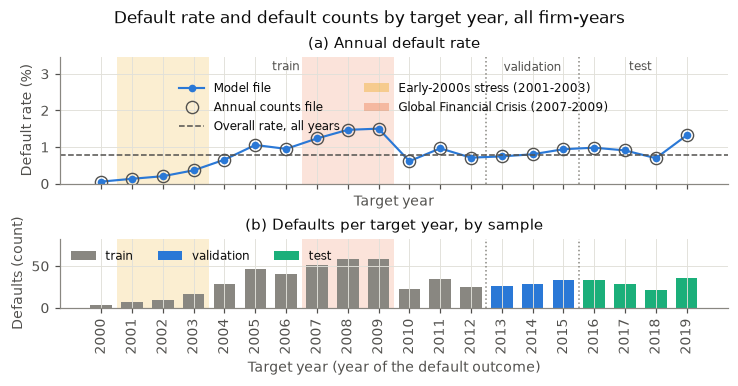

In [11]:
# Annual default rate by target year, all years, with stress periods shaded
years = data_annual.index.to_numpy()
rate_pct = data_annual["rate"].to_numpy() * 100
file_pct = file_annual.loc[years, "default_rate"].to_numpy() * 100
overall_pct = R["s1"]["overall_rate"] * 100
split_color = {"train": "#898781", "validation": "#2a78d6", "test": "#1baf7a"}
split_of_year = {int(y): ("train" if y <= R["s1"]["split"]["train"]["ty_max"] else
                          ("validation" if y <= R["s1"]["split"]["validation"]["ty_max"] else "test")) for y in years}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.6, 3.4), sharex=True, layout="constrained",
                               height_ratios=[2.2, 1.2])
for ax in (ax1, ax2):
    ax.axvspan(STRESS["dotcom"][0] - 0.5, STRESS["dotcom"][-1] + 0.5, color=PERIOD_COLORS["dotcom"], alpha=0.18, lw=0)
    ax.axvspan(STRESS["gfc"][0] - 0.5, STRESS["gfc"][-1] + 0.5, color=PERIOD_COLORS["gfc"], alpha=0.18, lw=0)
    for edge in (R["s1"]["split"]["train"]["ty_max"] + 0.5, R["s1"]["split"]["validation"]["ty_max"] + 0.5):
        ax.axvline(edge, color=MUTED, ls=":", lw=1)
ax1.plot(years, rate_pct, color="#2a78d6", marker="o", ms=4, lw=1.4, label="Model file")
ax1.plot(years, file_pct, ls="none", marker="o", ms=8, mfc="none", mec=INK2, mew=0.9, label="Annual counts file")
ax1.axhline(overall_pct, color=INK2, ls="--", lw=1, label="Overall rate, all years")
ax1.set_ylim(0, rate_pct.max() * 2.3)
ax1.set_ylabel("Default rate (%)")
ax1.set_xlabel("Target year")
ax1.set_title("(a) Annual default rate")
trans = ax1.get_xaxis_transform()
for lo_x, hi_x, name in [(years.min() - 0.5, R["s1"]["split"]["train"]["ty_max"] + 0.5, "train"),
                         (R["s1"]["split"]["train"]["ty_max"] + 0.5, R["s1"]["split"]["validation"]["ty_max"] + 0.5, "validation"),
                         (R["s1"]["split"]["validation"]["ty_max"] + 0.5, years.max() + 0.5, "test")]:
    ax1.text((lo_x + hi_x) / 2, 0.97, name, transform=trans, ha="center", va="top", fontsize=8, color=INK2)
handles, labels = ax1.get_legend_handles_labels()
handles += [Patch(facecolor=PERIOD_COLORS["dotcom"], alpha=0.35, label="Early-2000s stress (2001-2003)"),
            Patch(facecolor=PERIOD_COLORS["gfc"], alpha=0.35, label="Global Financial Crisis (2007-2009)")]
ax1.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.89), ncol=2, frameon=False, fontsize=8)
ax2.bar(years, data_annual["defaults"].to_numpy(), color=[split_color[split_of_year[int(y)]] for y in years], width=0.7)
ax2.set_xlabel("Target year (year of the default outcome)")
ax2.set_ylabel("Defaults (count)")
ax2.set_title("(b) Defaults per target year, by sample")
ax2.set_ylim(0, data_annual["defaults"].max() * 1.4)
ax2.legend(handles=[Patch(facecolor=split_color[k], label=k) for k in split_color], loc="upper left", ncol=3, frameon=False)
ax2.set_xticks(years[::1])
ax2.tick_params(axis="x", labelrotation=90)
fig.suptitle("Default rate and default counts by target year, all firm-years")
print("Figure: annual default rate by target year with stress periods shaded.")
save_fig(fig, "annual_default_rate")



**Audit.** The model file matches its documented description: 78,682 firm-years, 8,262 firms, fiscal years 1999-2018 and 609 defaults. There are no missing or infinite values, no duplicate firm-years, and no firm defaults twice. The annual counts computed from the data equal the annual counts file in every target year, and the raw file agrees with the model file on identifiers, split and default flag.

**Default is rare.** The overall default rate is 0.77%. It is 0.72% in training (403 defaults in 55,927 firm-years), 0.83% in validation (87 in 10,473) and 0.97% in test (119 in 12,282), so the rate rises a little from each sample to the next.

**Why accuracy misleads.** A rule that predicts "no default" for every firm-year is right 99.28% of the time in training, 99.17% in validation and 99.03% in test while detecting no default at all. Accuracy therefore cannot separate a useful model from a useless one; the models below are judged on how they rank the few defaults and on the quality of their probabilities.

**Why a chronological split.** The default rate is far from constant over time: it ranges from 0.06% in target year 2000 to 1.50% in target year 2009. A random split would put firm-years from the same years in both training and test, so a model would be tested on conditions it had already seen. Training on earlier years and testing on later ones mimics how a lender would use the model.

**Annual pattern (figure above).**

- *Early-2000s stress (target years 2001-2003).* The default rate is 0.23% (34 defaults in 14,774 firm-years), below the overall rate of 0.77%. This dataset therefore shows no default spike in these years; the rate rises each year from 0.06% in 2000 to 0.37% in 2003 and first exceeds the overall rate in 2005 (1.06%).
- *Global Financial Crisis (target years 2007-2009).* The rate is 1.40% (168 defaults in 11,994 firm-years), above the overall rate, with the peak of 1.50% in 2009; it falls to 0.61% in 2010.
- *Validation and test years.* Rates for target years 2013-2015 lie between 0.75% and 0.94%, and for 2016-2019 between 0.70% (2018) and 1.32% (2019), the highest of the four test years.

**Panel caveat.** The data are a panel: firms recur across years. All 4,169 validation firms and all 3,712 test firms also appear in the training sample, and 4,636 firms appear in more than one sample. Results below therefore describe later years of firms the model has already seen, not entirely new firms.


### Predictor groups

The 21 continuous predictors fall into five economic groups (liquidity, leverage / capital structure, profitability, operating efficiency and market information), plus the categorical industry code. The table gives each variable's definition and unit from the data dictionary.

In [12]:
# Predictor groups with definitions and units from the data dictionary
dict_model = dictionary.loc[dictionary["dataset"] == "model_ready"].set_index("variable")
group_rows = []
for g, vs in GROUPS.items():
    for v in vs:
        group_rows.append({"Group": GROUP_NAMES[g], "Predictor": VAR_LABELS[v], "Column": v,
                           "Definition": dict_model.loc[v, "definition"], "Unit": dict_model.loc[v, "units_or_type"]})
group_rows.append({"Group": "Industry", "Predictor": "Industry code", "Column": "industry_code",
                   "Definition": dict_model.loc["industry_code", "definition"],
                   "Unit": "category (one-hot encoded)"})
show(pd.DataFrame(group_rows), "Predictor groups, definitions and units")
print(f"{len(CONT)} continuous predictors in {len(GROUPS)} groups, plus the industry code with {len(INDUSTRY_LEVELS)} levels.")


Predictor groups, definitions and units


Group,Predictor,Column,Definition,Unit
Liquidity,Current ratio,current_ratio,current_assets / current_liabilities,ratio
Liquidity,Quick ratio,quick_ratio,(current_assets - inventory) / current_liabilities,ratio
Leverage / capital structure,Debt / assets,debt_to_assets,total_liabilities / total_assets,ratio
Leverage / capital structure,Long-term debt / assets,longterm_debt_to_assets,long_term_debt / total_assets,ratio
Leverage / capital structure,Current liabilities / assets,current_liabilities_to_assets,current_liabilities / total_assets,ratio
Leverage / capital structure,Equity / assets,equity_to_assets,(total_assets - total_liabilities) / total_assets,ratio
Profitability,Net income / assets,net_income_to_assets,net_income / total_assets,ratio
Profitability,EBITDA / assets,ebitda_to_assets,ebitda / total_assets,ratio
Profitability,EBIT / assets,ebit_to_assets,ebit / total_assets,ratio
Profitability,Retained earnings / assets,retained_earnings_to_assets,retained_earnings / total_assets,ratio


21 continuous predictors in 5 groups, plus the industry code with 10 levels.


### Training-sample exploration

From here on, every statistic and plot that uses the default flag is computed on training firm-years only.

In [13]:
# Descriptive statistics of the 21 continuous predictors, training sample
desc_src = X_train[CONT]
q = desc_src.quantile([0.01, 0.25, 0.5, 0.75, 0.99])
desc = pd.DataFrame({"Count": desc_src.count(), "Mean": desc_src.mean(), "SD": desc_src.std(), "Min": desc_src.min(),
                     "P01": q.loc[0.01], "P25": q.loc[0.25], "Median": q.loc[0.5], "P75": q.loc[0.75],
                     "P99": q.loc[0.99], "Max": desc_src.max(), "Skew": desc_src.skew()})
R["s1"]["train_desc"] = {v: {"mean": float(desc.loc[v, "Mean"]), "sd": float(desc.loc[v, "SD"]), "min": float(desc.loc[v, "Min"]),
                             "p01": float(desc.loc[v, "P01"]), "p25": float(desc.loc[v, "P25"]),
                             "median": float(desc.loc[v, "Median"]), "p75": float(desc.loc[v, "P75"]),
                             "p99": float(desc.loc[v, "P99"]), "max": float(desc.loc[v, "Max"]),
                             "skew": float(desc.loc[v, "Skew"])} for v in CONT}
desc_show = desc.copy()
desc_show.insert(0, "Group", [GROUP_NAMES[VAR_GROUPS[v]] for v in desc_show.index])
desc_show.index = [VAR_LABELS[v] for v in desc_show.index]
desc_show.index.name = "Predictor"
desc_show = desc_show.reset_index()
show(desc_show, f"Descriptive statistics, training sample ({len(X_train):,} firm-years)", formats={"Count": "int"})
print(f"Training sample: {len(X_train):,} firm-years, {int(y_train.sum()):,} defaults, "
      f"{int(desc['Count'].min()):,} non-missing values for every predictor.")


Descriptive statistics, training sample (55,927 firm-years)


Predictor,Group,Count,Mean,SD,Min,P01,P25,Median,P75,P99,Max,Skew
Current ratio,Liquidity,"55,927",0.927,0.384,0.197,0.351,0.649,0.848,1.122,2.083,4.000,1.175
Quick ratio,Liquidity,"55,927",0.732,0.307,0.152,0.274,0.509,0.669,0.886,1.689,3.151,1.185
Debt / assets,Leverage / capital structure,"55,927",0.411,0.189,0.030,0.044,0.265,0.401,0.550,0.829,0.970,0.176
Long-term debt / assets,Leverage / capital structure,"55,927",0.201,0.097,0.011,0.021,0.127,0.194,0.268,0.438,0.574,0.353
Current liabilities / assets,Leverage / capital structure,"55,927",0.148,0.070,0.024,0.030,0.094,0.143,0.197,0.317,0.423,0.350
Equity / assets,Leverage / capital structure,"55,927",0.589,0.189,0.030,0.171,0.450,0.599,0.735,0.956,0.970,-0.176
Net income / assets,Profitability,"55,927",0.067,0.058,-0.195,-0.080,0.030,0.068,0.106,0.196,0.285,-0.212
EBITDA / assets,Profitability,"55,927",0.132,0.069,-0.157,-0.030,0.086,0.133,0.179,0.290,0.402,-0.054
EBIT / assets,Profitability,"55,927",0.097,0.070,-0.187,-0.067,0.050,0.098,0.145,0.257,0.382,-0.055
Retained earnings / assets,Profitability,"55,927",0.140,0.138,-0.452,-0.179,0.047,0.141,0.234,0.459,0.686,-0.012


Training sample: 55,927 firm-years, 403 defaults, 55,927 non-missing values for every predictor.



**Ranges.** The 21 predictors (accounting ratios plus log market value, annual return, return volatility and market beta) take finite values; none has a missing or infinite value. Debt / assets runs from 0.030 to 0.970, Gross margin from 0.030 to 0.679 and Current ratio up to 4.000. Annual return has a floor at -0.950, which is also its 1st percentile (-0.950), so at least 1% of training firm-years sit at that floor.

**Skew.** Most ratios are roughly symmetric or moderately skewed. The exceptions are Receivables / sales (skew 2.406) and Inventory / sales (skew 2.631), whose maxima (0.508 and 0.504) lie far above their 99th percentiles (0.160 and 0.117). The variables are on very different scales (the mean of Log market value is 9.263, that of Annual return -0.086), which is why the linear models standardize them.

**Transformations.** No imputation is needed because nothing is missing. No winsorizing is applied: every ratio has a finite, bounded range (see the minimum and maximum in the table above), and clipping would be one more choice to fit on training data. The two skewed ratios above remain a possible influence on the linear fits. Tree-based models are unaffected by monotone rescaling.


In [14]:
# Default versus non-default firm-years, training sample
is_def = y_train == 1
R["s1"]["compare"] = {"n_default": int(is_def.sum()), "n_nondefault": int((~is_def).sum()), "vars": {}}
cmp_rows = []
for v in COMPARE_VARS:
    a, b = X_train.loc[is_def, v].to_numpy(dtype=float), X_train.loc[~is_def, v].to_numpy(dtype=float)
    entry = {"mean_default": float(a.mean()), "mean_nondefault": float(b.mean()),
             "median_default": float(np.median(a)), "median_nondefault": float(np.median(b)), "smd": smd(a, b)}
    R["s1"]["compare"]["vars"][v] = entry
    cmp_rows.append({"Predictor": var_label(v), "Mean, default": entry["mean_default"],
                     "Mean, non-default": entry["mean_nondefault"], "Median, default": entry["median_default"],
                     "Median, non-default": entry["median_nondefault"], "SMD (default minus non-default)": entry["smd"]})
print(f"Training firm-years: {R['s1']['compare']['n_default']:,} defaults and {R['s1']['compare']['n_nondefault']:,} non-defaults.")
show(pd.DataFrame(cmp_rows), "Default versus non-default firm-years, training sample",
     formats={"SMD (default minus non-default)": "sf2"})


Training firm-years: 403 defaults and 55,524 non-defaults.
Default versus non-default firm-years, training sample


Predictor,"Mean, default","Mean, non-default","Median, default","Median, non-default",SMD (default minus non-default)
Current ratio (ratio),0.838,0.927,0.774,0.849,-0.25
Debt / assets (ratio),0.527,0.410,0.537,0.400,+0.64
Net income / assets (ratio),0.049,0.067,0.048,0.068,-0.30
Retained earnings / assets (ratio),0.078,0.141,0.081,0.141,-0.46
Sales / assets (ratio),1.009,1.005,0.968,0.956,+0.01
Log market value (log $ millions),8.876,9.266,8.957,9.272,-0.32
Annual return (decimal return),-0.223,-0.085,-0.176,-0.064,-0.41
Return volatility (decimal volatility),0.321,0.287,0.310,0.281,+0.32


Figure: box plots of six predictors, default versus non-default, training sample.


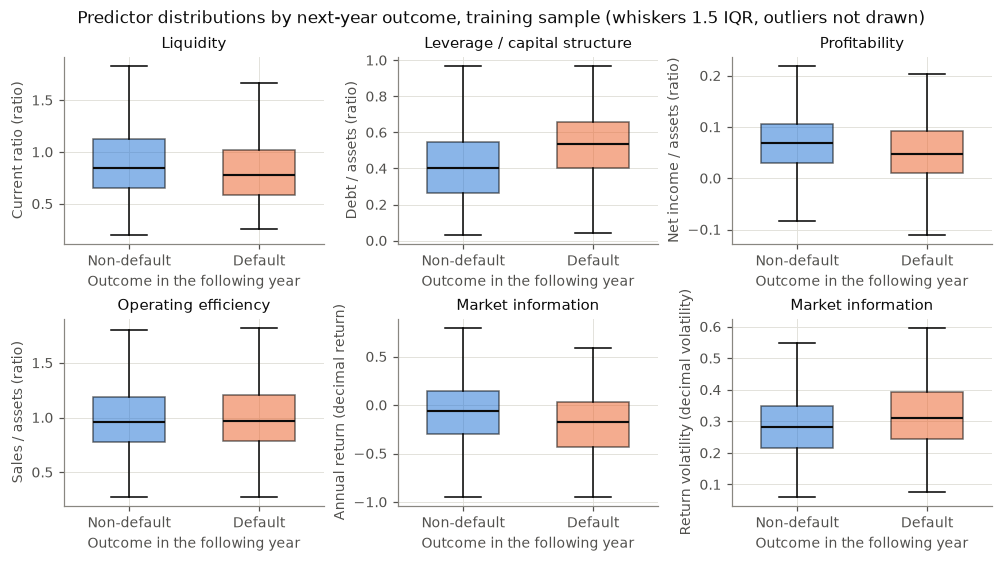

In [15]:
# Distributions of six predictors from five groups, default versus non-default, training sample
fig, axes = plt.subplots(2, 3, figsize=(9.0, 5.0), layout="constrained")
for ax, v in zip(axes.ravel(), DIST_VARS):
    data_nd = X_train.loc[y_train == 0, v].to_numpy(dtype=float)
    data_d = X_train.loc[y_train == 1, v].to_numpy(dtype=float)
    bp = ax.boxplot([data_nd, data_d], tick_labels=["Non-default", "Default"], showfliers=False, patch_artist=True,
                    widths=0.55, medianprops={"color": INK, "lw": 1.4})
    for patch, key in zip(bp["boxes"], ["nondefault", "default"]):
        patch.set_facecolor(CLASS_COLORS[key])
        patch.set_alpha(0.55)
    ax.set_title(GROUP_NAMES[VAR_GROUPS[v]])
    ax.set_xlabel("Outcome in the following year")
    ax.set_ylabel(var_label(v))
fig.suptitle("Predictor distributions by next-year outcome, training sample (whiskers 1.5 IQR, outliers not drawn)")
print("Figure: box plots of six predictors, default versus non-default, training sample.")
save_fig(fig, "train_distributions")



Training sample only: 403 default and 55,524 non-default firm-years. The standardized mean difference (SMD) is the default mean minus the non-default mean in units of the pooled standard deviation; an absolute SMD of at least 0.2 is called notable and below 0.1 little difference. These are descriptive contrasts, not tests.

**Direction against the expected signs.** All seven variables with a clear prior move the expected way, in both mean and median:

- Debt / assets: mean 0.527 for defaults against 0.410 (median 0.537 against 0.400), SMD +0.64, the largest of the eight.
- Retained earnings / assets: 0.078 against 0.141, SMD -0.46.
- Annual return: -0.223 against -0.085, SMD -0.41.
- Log market value (smaller firms): 8.876 against 9.266, SMD -0.32.
- Return volatility: 0.321 against 0.287, SMD +0.32.
- Net income / assets: 0.049 against 0.067, SMD -0.30.
- Current ratio: 0.838 against 0.927, SMD -0.25.

All seven SMDs are notable (absolute value at least 0.2). Sales / assets, which has no clear prior, shows little difference (SMD +0.01).

**Overlap.** The box plots show the same pattern, but the default and non-default boxes overlap in every panel. No single variable separates the two groups: the largest absolute SMD is +0.64, and the others are below that. Models therefore have to combine several moderate signals.


Figure: correlation heatmap of the Model 1 predictors, training sample.


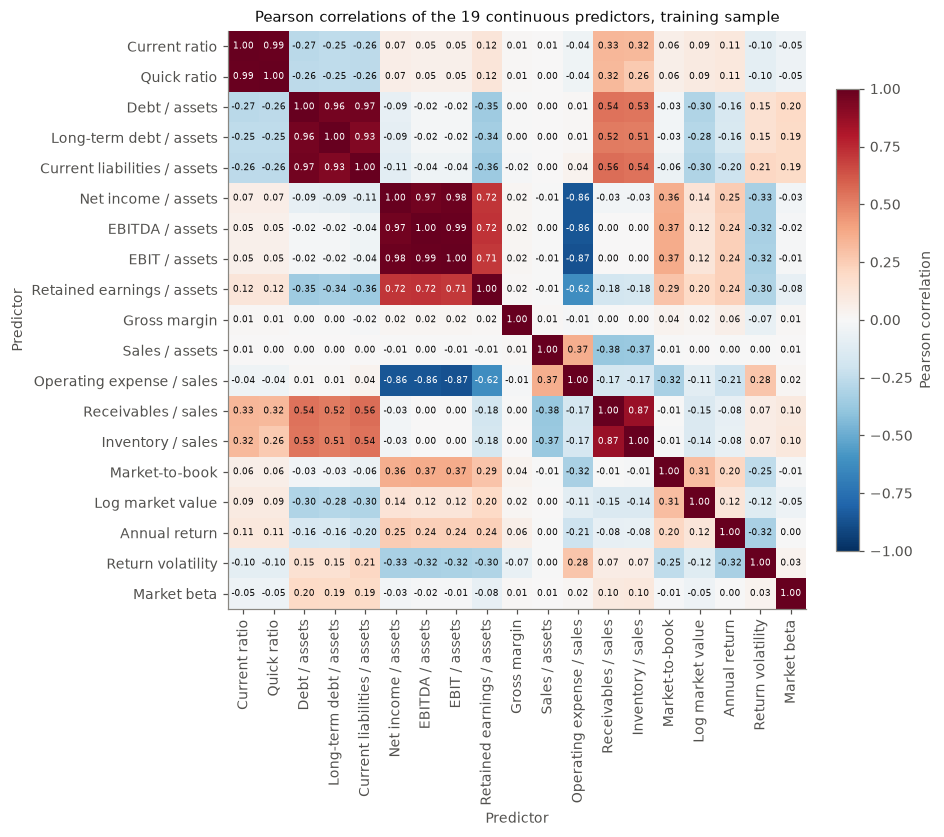

Pairs among the 19 predictors with |r| >= 0.7: 14 (7 with |r| >= 0.9).
Strongly correlated pairs, training sample (sorted by |r|)


Predictor A,Predictor B,Pearson r
Current ratio,Quick ratio,+0.99
EBITDA / assets,EBIT / assets,+0.99
Net income / assets,EBIT / assets,+0.98
Debt / assets,Current liabilities / assets,+0.97
Net income / assets,EBITDA / assets,+0.97
Debt / assets,Long-term debt / assets,+0.96
Long-term debt / assets,Current liabilities / assets,+0.93
EBIT / assets,Operating expense / sales,-0.87
Receivables / sales,Inventory / sales,+0.87
EBITDA / assets,Operating expense / sales,-0.86


Exact complement pairs, training sample (all 21 predictors)


Pair,Pearson r
Equity / assets and Debt / assets,-1.00
COGS / sales and Gross margin,-1.00


In [16]:
# Pearson correlations of the 19 Model 1 predictors, training sample
corr = X_train[CORR_VARS].corr(method="pearson")
corr_vals = corr.to_numpy()
fig, ax = plt.subplots(figsize=(8.5, 7.5), layout="constrained")
im = ax.imshow(corr_vals, cmap="RdBu_r", vmin=-1, vmax=1)
ticks = np.arange(len(CORR_VARS))
ax.set_xticks(ticks, labels=[VAR_LABELS[v] for v in CORR_VARS], rotation=90)
ax.set_yticks(ticks, labels=[VAR_LABELS[v] for v in CORR_VARS])
ax.grid(False)
for i in range(len(CORR_VARS)):
    for j in range(len(CORR_VARS)):
        val = corr_vals[i, j]
        ax.text(j, i, f"{round(val, 2) + 0.0:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(val) > 0.6 else INK)
ax.set_xlabel("Predictor")
ax.set_ylabel("Predictor")
ax.set_title("Pearson correlations of the 19 continuous predictors, training sample")
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Pearson correlation")
print("Figure: correlation heatmap of the Model 1 predictors, training sample.")
save_fig(fig, "train_correlation_heatmap")

pairs = []
for i in range(len(CORR_VARS)):
    for j in range(i + 1, len(CORR_VARS)):
        if abs(corr_vals[i, j]) >= CORR_STRONG:
            pairs.append((CORR_VARS[i], CORR_VARS[j], float(corr_vals[i, j])))
pairs.sort(key=lambda t: -abs(t[2]))
corr_all = X_train[CONT].corr(method="pearson")
R["s1"]["corr"] = {
    "vars": list(CORR_VARS),
    "strong_pairs": [{"a": a, "b": b, "r": r} for a, b, r in pairs],
    "n_strong": len(pairs),
    "n_very_strong": int(sum(abs(r) >= CORR_VERY_STRONG for _, _, r in pairs)),
    "complements": {"equity_debt": float(corr_all.loc["equity_to_assets", "debt_to_assets"]),
                    "cogs_gm": float(corr_all.loc["cogs_to_sales", "gross_margin"])},
}
sys.stdout.flush()
print(f"Pairs among the 19 predictors with |r| >= {CORR_STRONG}: {R['s1']['corr']['n_strong']} "
      f"({R['s1']['corr']['n_very_strong']} with |r| >= {CORR_VERY_STRONG}).")
pair_table = pd.DataFrame([{"Predictor A": VAR_LABELS[a], "Predictor B": VAR_LABELS[b], "Pearson r": r} for a, b, r in pairs])
if len(pair_table):
    show(pair_table, "Strongly correlated pairs, training sample (sorted by |r|)", formats={"Pearson r": "sf2"})
comp_table = pd.DataFrame([
    {"Pair": "Equity / assets and Debt / assets", "Pearson r": R["s1"]["corr"]["complements"]["equity_debt"]},
    {"Pair": "COGS / sales and Gross margin", "Pearson r": R["s1"]["corr"]["complements"]["cogs_gm"]},
])
show(comp_table, "Exact complement pairs, training sample (all 21 predictors)", formats={"Pearson r": "sf2"})



Among the 19 predictors of Model 1 (training sample), 14 pairs have an absolute Pearson correlation of at least 0.7 and 7 of at least 0.9.

- **Liquidity pair.** Current ratio and Quick ratio: r = +0.99.
- **Leverage trio.** Debt / assets, Long-term debt / assets and Current liabilities / assets: r = +0.97 (Debt and Current liabilities), +0.96 (Debt and Long-term debt) and +0.93 (Long-term debt and Current liabilities).
- **Profitability trio.** EBITDA / assets, EBIT / assets and Net income / assets: r = +0.99 (EBITDA and EBIT), +0.98 (Net income and EBIT) and +0.97 (Net income and EBITDA).
- **Other pairs, below 0.9.** Operating expense / sales is negatively correlated with the profitability trio (r = -0.87 with EBIT, -0.86 with EBITDA, -0.86 with Net income); Receivables / sales and Inventory / sales have r = +0.87; Retained earnings / assets has r between +0.71 and +0.72 with the profitability trio.

**Exact complements.** Equity / assets and Debt / assets have r = -1.00, and COGS / sales and Gross margin have r = -1.00, because each pair sums to one in every firm-year. This is why Model 1 omits Equity / assets and COGS / sales.

**Consequence for interpretation.** Predictors that move together carry largely the same information, so a model can split their effect between them in many ways. Individual coefficients of such predictors (Section 2) and the importance of any one member of a group (Section 6) should be read for the group, not variable by variable.


### Expected direction of default risk

The table states, before any model is fitted, the direction in which each predictor is expected to move default risk, with the economic reason. "+" means a higher value is expected to raise next-year default risk; "−" means a higher value is expected to lower it. The last three rows have no clear prior, and the reason is given.

| Predictor | Expected sign | Economic reason |
|---|---|---|
| Debt / assets (`debt_to_assets`) | + | More leverage means larger fixed claims on the firm's assets and less room to absorb losses. |
| Current ratio (`current_ratio`) | − | More current assets per unit of current liabilities means more liquid resources to meet short-term obligations. |
| Net income / assets (`net_income_to_assets`) | − | More profitable firms generate cash internally and are less likely to fail. |
| Retained earnings / assets (`retained_earnings_to_assets`) | − | Accumulated earnings are a cushion built over time; young or loss-making firms have little. |
| Log market value (`log_market_value`) | − | Larger firms are more diversified and have better access to financing. |
| Annual return (`annual_return`) | − | Poor past equity returns signal deteriorating prospects. |
| Return volatility (`return_volatility`) | + | Volatile equity reflects greater uncertainty about the firm's value and a higher chance of falling below its debt. |
| Market-to-book (`market_to_book`) | ambiguous | A high ratio can signal growth prospects (lower risk) but also an inflated valuation or a small equity base (higher risk). |
| Market beta (`market_beta`) | ambiguous | High beta means more exposure to the market, but it measures systematic risk, not default risk directly. |
| Sales / assets (`sales_to_assets`) | ambiguous | Asset turnover can reflect efficient use of assets (lower risk) or an aggressive, low-margin business model (higher risk). |

Sections 2 and 6 compare these expectations with the fitted models.

### Transformations

- **Imputation.** None is applied. The audit above checks for missing and infinite values.
- **Winsorizing.** None is applied. No extreme values are clipped or removed; the descriptive table lets the reader check the range of every ratio.
- **Standardization.** Variables are standardized only inside the linear-model pipelines, with the mean and standard deviation fitted on training rows alone.
- **Trees.** The tree-based models use the unscaled values, so split thresholds stay in natural units.
- **Industry.** The industry code is one-hot encoded with the fixed list of its ten categories.

## 2. Linear Benchmark Models

This section fits three logistic-regression models on the training sample (fiscal years 1999-2011) and tunes the two penalized ones on the validation sample (fiscal years 2012-2014). The test sample is not touched.

### Predictors and encoding

- The 21 continuous ratios are standardized with a scaler fitted on training rows only, inside each model pipeline, so validation (and later test) rows are scaled with training means and standard deviations.
- `industry_code` is one-hot encoded with the fixed list of ten categories from the data dictionary. Models 2 and 3 keep all ten industry dummies. Model 1 uses industry 1 as the reference level (the lowest code), so it carries nine dummies.

### Why Model 1 uses 19 ratios instead of 21

`equity_to_assets` equals 1 − `debt_to_assets` and `cogs_to_sales` equals 1 − `gross_margin` for every firm-year (Section 1 shows the largest deviation). With an intercept, keeping both members of each pair means infinitely many coefficient combinations give exactly the same predictions, so an unpenalized logistic regression has no unique solution. Model 1 therefore drops `equity_to_assets` and `cogs_to_sales`; this removes no information and does not change any prediction. Ridge and LASSO keep all 21 because a penalty makes the fit well defined. Ridge's L2 penalty is strictly convex, so its coefficients are unique. LASSO's fitted probabilities are unique too, but for an exact-complement pair with a nonzero combined effect (Debt / assets and Equity / assets) the L1 penalty leaves the split of that effect between the two coefficients arbitrary, so only the pair's combined effect (the Debt / assets coefficient minus the Equity / assets coefficient) is interpreted. The first table below documents this with the numerical rank of each training design matrix.

### Models

- **Model 1: logistic regression** without a penalty (`C=np.inf`). It uses a Newton-type solver with a tight tolerance so that the fit reaches the unpenalized optimum on this strongly correlated design.
- **Model 2: LASSO logistic regression** (L1 penalty). It uses the coordinate-descent `liblinear` solver with a large intercept scaling so that the intercept is effectively not penalized. A standardized coefficient that is zero up to a tiny tolerance (listed in the settings table) counts as zero.
- **Model 3: Ridge logistic regression** (L2 penalty) with the same Newton-type solver as Model 1.

### Tuning and selection

The inverse penalty strength `C` is searched over the small grid 0.01, 0.1, 1 and 10 (a smaller `C` is a stronger penalty). For each penalty type the value with the highest validation ROC-AUC is selected. Candidates within 0.0001 of the best validation ROC-AUC are treated as tied, and the tie goes to the stronger penalty (the smaller `C`). Validation ROC-AUC is threshold-free and more stable than PR-AUC when validation defaults are few; PR-AUC and KS (the maximum of true-positive rate minus false-positive rate) are reported alongside.

The coefficient tables report standardized coefficients: the change in log-odds of default for a one training-standard-deviation increase in a ratio. They describe predictive associations, not causal effects.

In [17]:
# ---- design evidence on the training sample -------------------------------------------------
def design_matrix(cont, drop_reference):
    """Fitted preprocessor and the training design matrix with an intercept column."""
    prep = make_linear(cont, drop_reference, LogisticRegression(C=np.inf)).named_steps["prep"].fit(X_train)
    return prep, np.column_stack([np.ones(len(X_train)), prep.transform(X_train)])


def rank_and_condition(design):
    sing = np.linalg.svd(design, compute_uv=False)
    return int(np.linalg.matrix_rank(design)), float(sing[0] / max(sing[-1], np.finfo(float).tiny))


prep_all21, design_all21 = design_matrix(CONT, True)
prep_m1, design_m1 = design_matrix(M1_CONT, True)
rank_all21, cond_all21 = rank_and_condition(design_all21)
rank_m1, cond_m1 = rank_and_condition(design_m1)
R["s2"]["design"] = {"cols_all21": int(design_all21.shape[1]), "rank_all21": rank_all21, "cond_all21": cond_all21,
                     "cols_m1": int(design_m1.shape[1]), "rank_m1": rank_m1, "cond_m1": cond_m1}
show(pd.DataFrame({
    "Design (training sample)": ["Intercept + all 21 standardized ratios + 9 industry dummies",
                                 "Intercept + 19 standardized ratios (Model 1 set) + 9 industry dummies"],
    "Columns": [design_all21.shape[1], design_m1.shape[1]],
    "Numerical rank": [rank_all21, rank_m1],
    "Condition number": [format(c, ".2f" if c < 1e6 else ".2e") for c in (cond_all21, cond_m1)],
    "Unique unpenalized solution": ["no" if rank_all21 < design_all21.shape[1] else "yes",
                                    "no" if rank_m1 < design_m1.shape[1] else "yes"]}),
     "Design evidence: rank of the training design matrix (the industry reference level is dropped in both rows)")

industry_counts = X_train["industry_code"].value_counts().sort_index()
R["s2"]["reference_industry"] = int(REF_INDUSTRY)
R["s2"]["reference_is_modal"] = bool(industry_counts.idxmax() == REF_INDUSTRY)
print("Training firm-years by industry: " + ", ".join(f"{k}: {v:,}" for k, v in industry_counts.items()))
print(f"Reference industry {REF_INDUSTRY} has {industry_counts[REF_INDUSTRY]:,} training firm-years; "
      f"most frequent industry: {industry_counts.idxmax()}.")

scaler_m1 = prep_m1.named_transformers_["num"]
train_means = X_train[M1_CONT].to_numpy(dtype=float).mean(axis=0)
train_sds = X_train[M1_CONT].to_numpy(dtype=float).std(axis=0)
scaler_gap = float(max(np.abs(scaler_m1.mean_ - train_means).max(), np.abs(scaler_m1.scale_ - train_sds).max()))
print(f"Largest gap between the scaler's means and standard deviations and the training values: {scaler_gap:.1e}")
record_check("model1_design_full_rank", rank_m1 == design_m1.shape[1],
             "the Model 1 design matrix has full column rank, so the unpenalized fit is unique")
record_check("all21_design_rank_deficient", rank_all21 < design_all21.shape[1],
             "the design with all 21 ratios is rank deficient, which is why Model 1 drops the two complements")
record_check("scaler_fit_on_train", scaler_gap <= 1e-12,
             "the scaler's means and standard deviations equal the training-sample values")


Design evidence: rank of the training design matrix (the industry reference level is dropped in both rows)


Design (training sample),Columns,Numerical rank,Condition number,Unique unpenalized solution
Intercept + all 21 standardized ratios + 9 industry dummies,31,29,2.30e+16,no
Intercept + 19 standardized ratios (Model 1 set) + 9 industry dummies,29,29,26.90,yes


Training firm-years by industry: 1: 5,987, 2: 5,671, 3: 5,792, 4: 5,907, 5: 5,445, 6: 5,363, 7: 4,970, 8: 5,449, 9: 5,611, 10: 5,732
Reference industry 1 has 5,987 training firm-years; most frequent industry: 1.
Largest gap between the scaler's means and standard deviations and the training values: 0.0e+00
  passed: the Model 1 design matrix has full column rank, so the unpenalized fit is unique
  passed: the design with all 21 ratios is rank deficient, which is why Model 1 drops the two complements
  passed: the scaler's means and standard deviations equal the training-sample values


In [18]:
# ---- Model 1: logistic regression without a penalty ------------------------------------------
pipe_m1 = make_linear(M1_CONT, True,
                      LogisticRegression(C=np.inf, solver="newton-cholesky", tol=1e-8, max_iter=1000)
                      ).fit(X_train, y_train)
print(f"Model 1 fitted on {len(y_train):,} training firm-years "
      f"({int(y_train.sum()):,} defaults); solver iterations: {int(np.ravel(pipe_m1.named_steps['clf'].n_iter_)[0])}.")


Model 1 fitted on 55,927 training firm-years (403 defaults); solver iterations: 8.


In [19]:
# ---- LASSO and Ridge: tune C on validation ROC-AUC -----------------------------------------------
def make_penalized(kind, c):
    if kind == "lasso":
        clf = LogisticRegression(C=c, l1_ratio=1.0, solver="liblinear", intercept_scaling=100.0, tol=1e-6,
                                 max_iter=1000, random_state=SEED)
    else:
        clf = LogisticRegression(C=c, l1_ratio=0.0, solver="newton-cholesky", tol=1e-8, max_iter=1000)
    return make_linear(CONT, False, clf)


s2_fits = {"lasso": [], "ridge": []}
s2_tuning = {"lasso": [], "ridge": []}
s2_selected_idx = {}
for kind in ("lasso", "ridge"):
    for c in C_GRID:
        pipe = make_penalized(kind, c).fit(X_train, y_train)
        coefs = pipe.named_steps["clf"].coef_.ravel()
        p_train, p_valid = predict(pipe, X_train), predict(pipe, X_valid)
        s2_fits[kind].append({"pipe": pipe, "train_prob": p_train, "val_prob": p_valid})
        s2_tuning[kind].append({"C": float(c), "train_roc_auc": roc_auc(y_train, p_train),
                                "val_roc_auc": roc_auc(y_valid, p_valid), "val_pr_auc": pr_auc(y_valid, p_valid),
                                "val_ks": ks_stat(y_valid, p_valid),
                                "n_zero": int(np.sum(np.abs(coefs) <= LASSO_ZERO_TOL))})
    s2_selected_idx[kind] = select_first_best([r["val_roc_auc"] for r in s2_tuning[kind]])
    R["s2"].setdefault("tuning", {})[kind] = s2_tuning[kind]
R["s2"]["selected"] = {"m2": s2_tuning["lasso"][s2_selected_idx["lasso"]]["C"],
                       "m3": s2_tuning["ridge"][s2_selected_idx["ridge"]]["C"]}

rows = []
for kind, label in (("lasso", "LASSO (L1)"), ("ridge", "Ridge (L2)")):
    for i, r in enumerate(s2_tuning[kind]):
        rows.append({"Penalty": label, "C": f"{r['C']:g}", "Train ROC-AUC": r["train_roc_auc"],
                     "Validation ROC-AUC": r["val_roc_auc"], "Validation PR-AUC": r["val_pr_auc"],
                     "Validation KS": r["val_ks"], "Zero coefficients (of 31)": r["n_zero"],
                     "Selected": "selected" if i == s2_selected_idx[kind] else ""})
show(pd.DataFrame(rows), "Tuning grid: C chosen by validation ROC-AUC (ties go to the stronger penalty)")
print(f"Selected C: LASSO {R['s2']['selected']['m2']:g}, Ridge {R['s2']['selected']['m3']:g}.")


Tuning grid: C chosen by validation ROC-AUC (ties go to the stronger penalty)


Penalty,C,Train ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation KS,Zero coefficients (of 31),Selected
LASSO (L1),0.01,0.697,0.672,0.022,0.246,25,
LASSO (L1),0.1,0.705,0.696,0.026,0.301,18,selected
LASSO (L1),1,0.708,0.691,0.025,0.306,6,
LASSO (L1),10,0.708,0.691,0.025,0.300,1,
Ridge (L2),0.01,0.707,0.697,0.026,0.311,0,selected
Ridge (L2),0.1,0.708,0.692,0.025,0.311,0,
Ridge (L2),1,0.708,0.691,0.025,0.303,0,
Ridge (L2),10,0.708,0.691,0.025,0.303,0,


Selected C: LASSO 0.1, Ridge 0.01.


In [20]:
# ---- selected linear models and their validation metrics ---------------------------------------
sel_lasso = s2_fits["lasso"][s2_selected_idx["lasso"]]
sel_ridge = s2_fits["ridge"][s2_selected_idx["ridge"]]
LINEAR = {
    "m1": {"pipe": pipe_m1, "params": {}, "setting": "no penalty; 19 continuous predictors + industry (reference: industry 1)",
           "cont": list(M1_CONT), "val_prob": predict(pipe_m1, X_valid), "train_prob": predict(pipe_m1, X_train)},
    "m2": {"pipe": sel_lasso["pipe"], "params": {"C": float(R["s2"]["selected"]["m2"])},
           "setting": f"C = {R['s2']['selected']['m2']}", "cont": list(CONT),
           "val_prob": sel_lasso["val_prob"], "train_prob": sel_lasso["train_prob"]},
    "m3": {"pipe": sel_ridge["pipe"], "params": {"C": float(R["s2"]["selected"]["m3"])},
           "setting": f"C = {R['s2']['selected']['m3']}", "cont": list(CONT),
           "val_prob": sel_ridge["val_prob"], "train_prob": sel_ridge["train_prob"]},
}
for m, spec in LINEAR.items():
    scaler = spec["pipe"].named_steps["prep"].named_transformers_["num"]
    assert np.allclose(scaler.mean_, X_train[spec["cont"]].to_numpy(dtype=float).mean(axis=0), atol=1e-12, rtol=0)

R["s2"]["val"] = {m: {"roc_auc": roc_auc(y_valid, s["val_prob"]), "pr_auc": pr_auc(y_valid, s["val_prob"]),
                      "ks": ks_stat(y_valid, s["val_prob"])} for m, s in LINEAR.items()}
R["s2"]["train_roc_auc"] = {m: roc_auc(y_train, s["train_prob"]) for m, s in LINEAR.items()}
show(pd.DataFrame([{"Model": MODEL_NAMES[m], "Setting": s["setting"], "Train ROC-AUC": R["s2"]["train_roc_auc"][m],
                    "Validation ROC-AUC": R["s2"]["val"][m]["roc_auc"], "Validation PR-AUC": R["s2"]["val"][m]["pr_auc"],
                    "Validation KS": R["s2"]["val"][m]["ks"]} for m, s in LINEAR.items()]),
     "Selected linear models: ranking metrics (validation sample, fiscal years 2012-2014)")


Selected linear models: ranking metrics (validation sample, fiscal years 2012-2014)


Model,Setting,Train ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation KS
Model 1: Logistic regression,no penalty; 19 continuous predictors + industry (reference: industry 1),0.708,0.690,0.025,0.303
Model 2: LASSO logistic (L1),C = 0.1,0.705,0.696,0.026,0.301
Model 3: Ridge logistic (L2),C = 0.01,0.707,0.697,0.026,0.311



**Comparison rule.** Comparisons in this notebook resample whole firms 2,000 times; a difference is labelled higher (lower) only if the middle 95% of the resampled differences lies entirely above (below) zero, and similar otherwise. This is a descriptive check of firm sampling noise, not a significance test.

**Tuning the penalty.** C was chosen by validation ROC-AUC; ties within 0.0001 go to the stronger penalty.

- *LASSO:* C = 0.1 (validation ROC-AUC 0.696). The strongest penalty, C = 0.01, zeroes 25 of 31 coefficients and has the lowest validation ROC-AUC (0.672); C = 1 and C = 10 give 0.691 and 0.691, both within 0.01 of the selected value.
- *Ridge:* C = 0.01 (validation ROC-AUC 0.697). The grid is flat: the four values range from 0.691 to 0.697, a spread of less than 0.01, so the choice of C matters little for ranking.

**Validation performance of the three linear models.**

| Model | ROC-AUC | PR-AUC | KS |
|---|---|---|---|
| Model 1: Logistic regression | 0.690 | 0.025 | 0.303 |
| Model 2: LASSO logistic (L1) | 0.696 | 0.026 | 0.301 |
| Model 3: Ridge logistic (L2) | 0.697 | 0.026 | 0.311 |

The three models are similar on validation ROC-AUC: Model 1 minus Model 2 is -0.006 [-0.020, +0.008], Model 1 minus Model 3 is -0.006 [-0.017, +0.004] and Model 2 minus Model 3 is -0.001 [-0.006, +0.005], all labelled similar. By validation ROC-AUC the best linear model is Model 3: Ridge logistic (L2), but only by a small margin. Regularization does not change validation ranking in a way these data can detect. PR-AUC is 0.025 to 0.026, above the validation default rate of 0.008 that a random ranking would roughly achieve, but low in absolute terms for a rare event.

**Fit on training versus validation.** Training ROC-AUC is 0.708, 0.705 and 0.707, a little above the validation values, so the linear models show only a small gap and little overfitting.

**Why Model 1 drops two ratios.** Equity / assets and COGS / sales are exact complements of Debt / assets and Gross margin: neither identity deviates from one in any firm-year. The training design with all 21 ratios has 31 columns but numerical rank 29, so an unpenalized fit would have no unique solution. Model 1's design has 29 columns and rank 29 (condition number 26.90), so its coefficients are unique. The dropped ratios add no information, so predictions are unchanged.


In [21]:
# ---- coefficient tables ---------------------------------------------------------------------
s2_coef, s2_industry, s2_intercept = {}, {}, {}
for m, spec in LINEAR.items():
    clf = spec["pipe"].named_steps["clf"]
    names = list(spec["pipe"].named_steps["prep"].get_feature_names_out())
    beta = dict(zip(names, clf.coef_.ravel().tolist()))
    s2_coef[m] = {v: float(beta[v]) for v in spec["cont"]}
    s2_industry[m] = {int(k.split("_")[-1]): float(b) for k, b in beta.items() if k.startswith("industry_code_")}
    s2_intercept[m] = float(clf.intercept_[0])
s2_rank = {m: pd.Series(c).abs().rank(ascending=False, method="min").astype(int).to_dict() for m, c in s2_coef.items()}
s2_top10 = {m: sorted(c, key=lambda v: (-abs(c[v]), CONT.index(v)))[:N_TOP] for m, c in s2_coef.items()}
shared = [v for v in CONT if v in s2_coef["m1"]]
R["s2"]["coef"] = s2_coef
R["s2"]["industry_coef"] = {m: {str(k): v for k, v in d.items()} for m, d in s2_industry.items()}
R["s2"]["intercept"] = s2_intercept
R["s2"]["top10"] = s2_top10
R["s2"]["top10_overlap"] = {f"{a}_{b}": int(len(set(s2_top10[a]) & set(s2_top10[b])))
                            for a, b in (("m1", "m2"), ("m1", "m3"), ("m2", "m3"))}
R["s2"]["abs_rank_corr"] = {f"m1_{b}": spearman([abs(s2_coef["m1"][v]) for v in shared],
                                                [abs(s2_coef[b][v]) for v in shared]) for b in ("m2", "m3")}

rows = []
for v in CONT:
    row = {"Variable": VAR_LABELS[v], "Group": GROUP_NAMES[VAR_GROUPS[v]]}
    for m in LINEAR_MODELS:
        short = MODEL_SHORT[m]
        if v in s2_coef[m]:
            row[f"{short} coefficient"] = fmt_num(s2_coef[m][v], "f3")
            row[f"{short} rank"] = str(s2_rank[m][v])
        else:
            row[f"{short} coefficient"] = "dropped (exact complement)"
            row[f"{short} rank"] = ""
    rows.append(row)
show(pd.DataFrame(rows), "Standardized coefficients (log-odds per 1 training SD); rank 1 = largest absolute coefficient")
rows = [{"Industry": lvl, **{f"{MODEL_SHORT[m]} coefficient": (fmt_num(s2_industry[m][lvl], "f3") if lvl in s2_industry[m]
                                                                  else "reference level") for m in LINEAR_MODELS}}
        for lvl in INDUSTRY_LEVELS]
rows.append({"Industry": "Intercept", **{f"{MODEL_SHORT[m]} coefficient": fmt_num(s2_intercept[m], "f3")
                                        for m in LINEAR_MODELS}})
show(pd.DataFrame(rows), "Industry dummies and intercept (Model 1 uses industry 1 as the reference level)")
print("Overlap of the ten largest continuous coefficients: "
      + ", ".join(f"{k.replace('m', 'M').replace('_', ' and ')}: {v}" for k, v in R["s2"]["top10_overlap"].items()) + ".")
print("Spearman correlation of absolute coefficients over the 19 shared ratios: "
      + ", ".join(f"Model 1 with Model {k[-1]}: {fmt_num(v, 'f2')}" for k, v in R["s2"]["abs_rank_corr"].items()) + ".")


Standardized coefficients (log-odds per 1 training SD); rank 1 = largest absolute coefficient


Variable,Group,M1 Logit coefficient,M1 Logit rank,M2 LASSO coefficient,M2 LASSO rank,M3 Ridge coefficient,M3 Ridge rank
Current ratio,Liquidity,0.086,12,0.000,13,-0.039,14
Quick ratio,Liquidity,-0.164,6,-0.079,7,-0.058,11
Debt / assets,Leverage / capital structure,0.446,2,0.098,5,0.133,2
Long-term debt / assets,Leverage / capital structure,0.135,9,0.132,4,0.132,4
Current liabilities / assets,Leverage / capital structure,-0.058,17,0.000,13,0.084,7
Equity / assets,Leverage / capital structure,dropped (exact complement),,-0.259,1,-0.133,3
Net income / assets,Profitability,-0.062,15,0.000,13,-0.016,16
EBITDA / assets,Profitability,-0.315,3,-0.023,11,-0.036,15
EBIT / assets,Profitability,0.449,1,0.000,13,-0.001,21
Retained earnings / assets,Profitability,-0.140,8,-0.143,3,-0.112,5


Industry dummies and intercept (Model 1 uses industry 1 as the reference level)


Industry,M1 Logit coefficient,M2 LASSO coefficient,M3 Ridge coefficient
1,reference level,0.000,0.009
2,0.075,0.000,0.031
3,-0.173,0.000,-0.041
4,0.217,0.035,0.079
5,-0.298,0.000,-0.067
6,-0.216,0.000,-0.048
7,0.000,0.000,0.008
8,0.158,0.000,0.054
9,-0.031,0.000,-0.001
10,-0.118,0.000,-0.025


Overlap of the ten largest continuous coefficients: M1 and M2: 7, M1 and M3: 6, M2 and M3: 8.
Spearman correlation of absolute coefficients over the 19 shared ratios: Model 1 with Model 2: 0.52, Model 1 with Model 3: 0.29.


In [22]:
# ---- expected-sign comparison ---------------------------------------------------------------
def coef_sign(m, v):
    b = s2_coef[m][v]
    if m == "m2" and abs(b) <= LASSO_ZERO_TOL:
        return "0"
    return "+" if b > 0 else "-"


R["s2"]["signs"] = {v: {"expected": exp, **{m: coef_sign(m, v) for m in LINEAR_MODELS}}
                    for v, exp in EXPECTED_SIGNS.items()}
R["s2"]["sign_agree"] = {m: int(sum(R["s2"]["signs"][v][m] == EXPECTED_SIGNS[v] for v in EXPECTED_SIGNS))
                         for m in LINEAR_MODELS}
rows = []
for v, exp in EXPECTED_SIGNS.items():
    row = {"Variable": VAR_LABELS[v], "Expected sign": exp}
    for m in LINEAR_MODELS:
        s = R["s2"]["signs"][v][m]
        row[f"{MODEL_SHORT[m]} sign"] = s
        row[f"{MODEL_SHORT[m]} agrees"] = "yes" if s == exp else "no"
    rows.append(row)
show(pd.DataFrame(rows), "Fitted coefficient signs against the expected direction of default risk ('0' = removed by LASSO)")
print("Signs in agreement with expectation (of " + str(len(EXPECTED_SIGNS)) + "): "
      + ", ".join(f"{MODEL_SHORT[m]}: {R['s2']['sign_agree'][m]}" for m in LINEAR_MODELS) + ".")


Fitted coefficient signs against the expected direction of default risk ('0' = removed by LASSO)


Variable,Expected sign,M1 Logit sign,M1 Logit agrees,M2 LASSO sign,M2 LASSO agrees,M3 Ridge sign,M3 Ridge agrees
Debt / assets,+,+,yes,+,yes,+,yes
Current ratio,-,+,no,0,no,-,yes
Net income / assets,-,-,yes,0,no,-,yes
Retained earnings / assets,-,-,yes,-,yes,-,yes
Log market value,-,-,yes,-,yes,-,yes
Annual return,-,-,yes,-,yes,-,yes
Return volatility,+,+,yes,+,yes,+,yes


Signs in agreement with expectation (of 7): M1 Logit: 6, M2 LASSO: 5, M3 Ridge: 7.


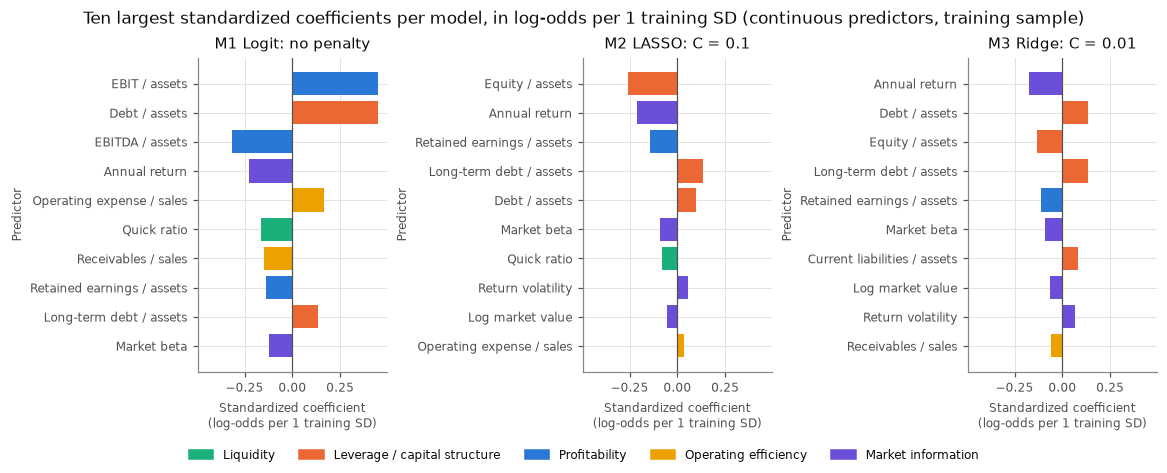

Note on the LASSO panel: Debt / assets and Equity / assets are exact complements, so LASSO's split between them is arbitrary (the L1 penalty does not fix it); only their combined effect, +0.357 log-odds per training SD of Debt / assets, is determined. Ridge's coefficients are unique.


In [23]:
# ---- Figure: largest standardized coefficients ----------------------------------------------
from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(1, 3, figsize=(10.5, 4.2), sharex=True, layout="constrained")
x_lim = 1.1 * max(abs(s2_coef[m][v]) for m in LINEAR_MODELS for v in s2_top10[m])
panel_setting = {"m1": "no penalty", "m2": f"C = {R['s2']['selected']['m2']:g}", "m3": f"C = {R['s2']['selected']['m3']:g}"}
used_groups = []
for ax, m in zip(axes, LINEAR_MODELS):
    top = s2_top10[m]
    ypos = np.arange(len(top))
    ax.barh(ypos, [s2_coef[m][v] for v in top], color=[GROUP_COLORS[VAR_GROUPS[v]] for v in top])
    used_groups += [VAR_GROUPS[v] for v in top]
    ax.set_yticks(ypos, [var_label(v, unit=False) for v in top])
    ax.invert_yaxis()
    ax.set_axisbelow(True)
    ax.axvline(0, color=INK2, linewidth=0.8)
    ax.set_xlim(-x_lim, x_lim)
    ax.set_title(f"{MODEL_SHORT[m]}: {panel_setting[m]}")
    ax.set_xlabel("Standardized coefficient\n(log-odds per 1 training SD)", fontsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.set_ylabel("Predictor", fontsize=8)
    ax.tick_params(labelsize=8)
group_order = [g for g in GROUPS if g in set(used_groups)]
fig.legend(handles=[Patch(color=GROUP_COLORS[g], label=GROUP_NAMES[g]) for g in group_order],
           loc="outside lower center", ncol=len(group_order), frameon=False)
fig.suptitle("Ten largest standardized coefficients per model, in log-odds per 1 training SD (continuous predictors, training sample)")
save_fig(fig, "linear_coefficients")
lasso_pair_effect = s2_coef["m2"]["debt_to_assets"] - s2_coef["m2"]["equity_to_assets"]
print(f"Note on the LASSO panel: Debt / assets and Equity / assets are exact complements, so LASSO's split between them is arbitrary "
      f"(the L1 penalty does not fix it); only their combined effect, {fmt_num(lasso_pair_effect, 'sf3')} log-odds per training SD of "
      f"Debt / assets, is determined. Ridge's coefficients are unique.")


In [24]:
# ---- LASSO zero summary ---------------------------------------------------------------------
lasso_names = list(LINEAR["m2"]["pipe"].named_steps["prep"].get_feature_names_out())
lasso_beta = LINEAR["m2"]["pipe"].named_steps["clf"].coef_.ravel()
zero_names = [n for n, b in zip(lasso_names, lasso_beta) if abs(b) <= LASSO_ZERO_TOL]
zero_cont = [n for n in zero_names if n in CONT]
zero_ind = [n for n in zero_names if n.startswith("industry_code_")]
R["s2"]["lasso_zero"] = {"n_zero": len(zero_names), "n_coef": int(len(lasso_beta)), "n_zero_continuous": len(zero_cont),
                         "n_zero_industry": len(zero_ind),
                         "zero_vars": [VAR_LABELS[n] for n in zero_cont] + [f"Industry {n.split('_')[-1]}" for n in zero_ind]}
pair_idx = [lasso_names.index("debt_to_assets"), lasso_names.index("equity_to_assets")]
combined = float(lasso_beta[pair_idx[0]] - lasso_beta[pair_idx[1]])
alt_beta = lasso_beta.copy()
alt_beta[pair_idx[0]], alt_beta[pair_idx[1]] = combined, 0.0          # equally good split: whole pair effect on Debt / assets
R["s2"]["lasso_pair"] = {"debt_equity": {"debt_coef": float(lasso_beta[pair_idx[0]]),
                                         "equity_coef": float(lasso_beta[pair_idx[1]]), "combined": combined}}
R["s2"]["lasso_zero"]["n_zero_alt"] = int(np.sum(np.abs(alt_beta) <= LASSO_ZERO_TOL))
show(pd.DataFrame([{"Split of the Debt / Equity effect": "Fitted LASSO", "Debt / assets": fmt_num(lasso_beta[pair_idx[0]], "f3"),
                    "Equity / assets": fmt_num(lasso_beta[pair_idx[1]], "f3"),
                    "Combined effect (debt minus equity)": fmt_num(combined, "f3"),
                    "Zero coefficients (of 31)": R["s2"]["lasso_zero"]["n_zero"]},
                   {"Split of the Debt / Equity effect": "Equally good split: whole effect on Debt / assets",
                    "Debt / assets": fmt_num(alt_beta[pair_idx[0]], "f3"), "Equity / assets": fmt_num(alt_beta[pair_idx[1]], "f3"),
                    "Combined effect (debt minus equity)": fmt_num(combined, "f3"),
                    "Zero coefficients (of 31)": R["s2"]["lasso_zero"]["n_zero_alt"]}]),
     "LASSO: the split between the exact complements Debt / assets and Equity / assets is arbitrary; only the combined effect is determined")
print(f"LASSO (C = {R['s2']['selected']['m2']:g}) sets {len(zero_names)} of {len(lasso_beta)} coefficients to zero: "
      f"{len(zero_cont)} of {len(CONT)} continuous ratios and {len(zero_ind)} of {len(INDUSTRY_LEVELS)} industry dummies.")
if zero_names:
    print("Zeroed predictors: " + "; ".join(R["s2"]["lasso_zero"]["zero_vars"]) + ".")
    print("A zero coefficient means the variable adds little given the others that remain (often a correlated "
          "substitute is kept); it does not show that the variable is unrelated to default.")
else:
    print("No coefficient is zero at the selected penalty strength.")


LASSO: the split between the exact complements Debt / assets and Equity / assets is arbitrary; only the combined effect is determined


Split of the Debt / Equity effect,Debt / assets,Equity / assets,Combined effect (debt minus equity),Zero coefficients (of 31)
Fitted LASSO,0.098,-0.259,0.357,18
Equally good split: whole effect on Debt / assets,0.357,0.000,0.357,19


LASSO (C = 0.1) sets 18 of 31 coefficients to zero: 9 of 21 continuous ratios and 9 of 10 industry dummies.
Zeroed predictors: Current ratio; Current liabilities / assets; Net income / assets; EBIT / assets; Gross margin; Sales / assets; COGS / sales; Inventory / sales; Market-to-book; Industry 1; Industry 2; Industry 3; Industry 5; Industry 6; Industry 7; Industry 8; Industry 9; Industry 10.
A zero coefficient means the variable adds little given the others that remain (often a correlated substitute is kept); it does not show that the variable is unrelated to default.



Coefficients are standardized (log-odds of default per one training standard deviation). They are predictive associations in this sample, not causal effects.

**Signs against expectations (seven variables with a clear prior).** Model 1 agrees on 6 of 7, LASSO on 5 of 7 and Ridge on 7 of 7. (The LASSO count credits Debt / assets, whose individual LASSO coefficient is arbitrary; see below.) Five have the expected sign in Model 1 and Ridge, each read as a predictive association and not a causal effect: Debt / assets (+0.133 in Ridge; more leverage leaves less room to absorb losses), Retained earnings / assets (-0.112; accumulated earnings are a cushion), Log market value (-0.066; larger firms are more diversified and have easier access to financing), Annual return (-0.176; weak prior returns signal deteriorating prospects) and Return volatility (+0.064; volatile equity is closer to falling below the firm's debt). In LASSO, Retained earnings, Log market value, Annual return and Return volatility have the expected sign individually, and leverage has it through the combined Debt / assets and Equity / assets effect (+0.357, positive as expected), because L1 can split that one effect between the two variables in different ways (they sum to one), so no claim is made about either coefficient alone. The exceptions need care:

- *Current ratio* has the opposite sign in Model 1 (+0.086), where Quick ratio is -0.164; the two have r = +0.99, so the pair splits one signal into opposite-signed pieces. LASSO sets Current ratio to zero and Ridge gives -0.039.
- *Net income / assets* is zero in LASSO, which counts as a disagreement in the table although no kept variable has a wrong sign. Net income, EBITDA and EBIT have pairwise correlations of at least 0.97, and in Model 1 EBIT / assets is the largest coefficient (+0.449) with EBITDA / assets at -0.315. Opposite-signed neighbours like these are typical of near-duplicate predictors, and their individual signs should not be given an economic reading.

**Do the same variables stay important after regularization?** Partly. The ten largest continuous coefficients (for LASSO, including the arbitrary Debt / assets and Equity / assets split) overlap in 7 of 10 variables for Models 1 and 2, 6 of 10 for Models 1 and 3 and 8 of 10 for Models 2 and 3. The Spearman correlation of absolute coefficients over the 19 shared ratios (again including that split for LASSO) is 0.52 (Models 1 and 2) and 0.29 (Models 1 and 3), so the order of importance changes more than the membership of the top ten. Annual return is in the top four in every model (4th, 2nd and 1st), Debt / assets is second in Models 1 and 3, and Retained earnings / assets and Long-term debt / assets are in the top ten of every model. Coefficient size shrinks with regularization: the largest in Model 1 is +0.449, against -0.176 in Ridge, whose coefficients are unique. In LASSO the Debt / assets and Equity / assets coefficients are one leverage effect split arbitrarily between two variables, so only their combined effect (+0.357) is read.

**LASSO zeros.** At C = 0.1, LASSO sets 18 of 31 coefficients to zero (an alternative solution with the same fit has 19, because the split between Debt / assets and Equity / assets is arbitrary): 9 continuous ratios (Current ratio, Current liabilities / assets, Net income / assets, EBIT / assets, Gross margin, Sales / assets, COGS / sales, Inventory / sales and Market-to-book) and 9 of the 10 industry dummies. Given the other predictors they add little predictive information, so a zero does not show that a variable is unrelated to default.

A substitute can be named only where the correlations above show one and the partner keeps a nonzero coefficient:

- EBIT / assets is zero while EBITDA / assets is kept (r = +0.99), and Net income / assets is zero while EBITDA / assets is kept (r = +0.97).
- Current ratio is zero while Quick ratio is kept (r = +0.99).
- Inventory / sales is zero while Receivables / sales is kept (r = +0.87).

The other zeros are not explained by a kept substitute. The industry dummies are zeroed because they add little given the rest, not because a substitute is kept. Gross margin and COGS / sales are both zero (they are exact complements, r = -1.00), so neither stands in for the other. Sales / assets is a weak predictor: its standardized mean difference between default and non-default training firm-years is only +0.01. Nothing in these results explains why Market-to-book is zeroed beyond the general reason above.


## 3. Trees, Bagging, and Boosting

This section fits the three tree-based models: Model 4 (a single decision tree), Model 5 (a random forest) and Model 6 (XGBoost, a gradient-boosted tree ensemble).

**Inputs.** The trees use the 21 continuous predictors in their original units (no scaling, because splits depend only on the ordering of a variable) plus the 10 industry categories as one-hot dummies. All models are fitted on the training sample only and are unweighted. Hyperparameters are chosen on the validation sample only, by validation ROC-AUC; when several candidates are within `TIE_TOL` of the best, the first one in the order listed below is taken (shallower, larger leaves and fewer rounds first, in the order of the grid). The test sample is not touched in this section.

**Grids (kept small on purpose).**

- *Decision tree:* maximum depth 2 to 6 crossed with two minimum leaf sizes (`min_samples_leaf`), shallower trees and the larger leaf size first. A second set of fits shows how training and validation ROC-AUC move with depth, with and without a leaf-size constraint, including an unconstrained tree.
- *Random forest:* a fixed number of trees; maximum depth, minimum leaf size and the number of predictors considered at each split (`max_features`) vary.
- *XGBoost:* subsampling of rows and columns, a minimum child weight and an L2 penalty are held fixed; maximum depth, learning rate and number of boosting rounds vary.

**How the three model types differ.**

- A **single tree** partitions firm-years with a sequence of threshold rules and predicts the default rate of the training firm-years in each leaf. It is easy to read, but it has high variance: a small change in the data can move the splits, and a deep tree can memorize the training sample.
- **Bagging and random forests** average many deep-ish trees, each grown on a bootstrap sample of the training rows. A random forest also considers only a random subset of predictors at each split (`max_features`), so the trees are less correlated with one another and their average is more stable than any single tree. Bagging proper is the special case in which every predictor is considered at every split.
- **Boosting** builds shallow trees one after another. Each new tree is fitted to the errors (the gradient of the log-loss) of the current ensemble and is added with a small learning rate, so the ensemble reduces bias step by step instead of averaging independent trees.

**Reading the tables.** Each tuning table lists the training and validation ROC-AUC of every candidate together with validation PR-AUC and KS; the selected candidate is marked. A large gap between training and validation ROC-AUC signals overfitting. Probabilities from trees are default rates in leaves (single tree) or averages and sums of tree scores (forest, boosting), so validation PR-AUC and KS are reported next to ROC-AUC.


In [25]:
# ---- Model 4: decision tree grid (training fits, validation selection) ------------------------
DT_FITS = []
for _d, _l in DT_GRID:
    _pipe = make_tree(DecisionTreeClassifier(max_depth=_d, min_samples_leaf=_l, random_state=SEED)).fit(X_train, y_train)
    _pv, _pt = predict(_pipe, X_valid), predict(_pipe, X_train)
    DT_FITS.append({"pipe": _pipe, "val_prob": _pv, "train_prob": _pt})
    R["s3"].setdefault("dt_grid", []).append({
        "max_depth": _d, "min_samples_leaf": _l, "train_roc_auc": roc_auc(y_train, _pt),
        "val_roc_auc": roc_auc(y_valid, _pv), "val_pr_auc": pr_auc(y_valid, _pv), "val_ks": ks_stat(y_valid, _pv),
        "n_leaves": int(_pipe.named_steps["clf"].get_n_leaves())})
DT_SEL = select_first_best([r["val_roc_auc"] for r in R["s3"]["dt_grid"]])
DT_BEST = R["s3"]["dt_grid"][DT_SEL]
R["s3"].setdefault("selected", {})["m4"] = {"max_depth": DT_BEST["max_depth"], "min_samples_leaf": DT_BEST["min_samples_leaf"]}

_tab = pd.DataFrame(R["s3"]["dt_grid"])
_tab["selected"] = ["selected" if i == DT_SEL else "" for i in range(len(_tab))]
_tab = _tab.rename(columns={"max_depth": "Max depth", "min_samples_leaf": "Min leaf size", "train_roc_auc": "Train ROC-AUC",
                            "val_roc_auc": "Validation ROC-AUC", "val_pr_auc": "Validation PR-AUC",
                            "val_ks": "Validation KS", "n_leaves": "Leaves", "selected": "Selection"})
show(_tab, "Decision tree grid (fitted on training, scored on validation)", formats={"Leaves": "int"})
print(f"Selected tree: maximum depth {DT_BEST['max_depth']}, minimum leaf size {DT_BEST['min_samples_leaf']} "
      f"(validation ROC-AUC {fmt_num(DT_BEST['val_roc_auc'], 'f3')}).")


Decision tree grid (fitted on training, scored on validation)


Max depth,Min leaf size,Train ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation KS,Leaves,Selection
2,200,0.671,0.617,0.012,0.227,4,
2,50,0.671,0.617,0.012,0.227,4,
3,200,0.702,0.627,0.014,0.227,8,
3,50,0.699,0.629,0.015,0.227,8,
4,200,0.724,0.607,0.015,0.203,16,
4,50,0.713,0.632,0.016,0.227,15,selected
5,200,0.750,0.601,0.016,0.203,25,
5,50,0.739,0.606,0.014,0.208,25,
6,200,0.781,0.611,0.018,0.217,39,
6,50,0.772,0.616,0.013,0.189,40,


Selected tree: maximum depth 4, minimum leaf size 50 (validation ROC-AUC 0.632).


Tree depth curves: minimum leaf size 1 and the selected minimum leaf size (50)


Max depth,Leaf 1: levels,Leaf 1: leaves,Leaf 1: train ROC-AUC,Leaf 1: validation ROC-AUC,Leaf 50: leaves,Leaf 50: train ROC-AUC,Leaf 50: validation ROC-AUC
1,1,2,0.644,0.611,2,0.644,0.611
2,2,4,0.646,0.611,4,0.671,0.617
3,3,6,0.648,0.611,8,0.699,0.629
4,4,10,0.668,0.617,15,0.713,0.632
5,5,14,0.696,0.622,25,0.739,0.606
6,6,21,0.706,0.626,40,0.772,0.616
7,7,30,0.716,0.622,58,0.801,0.595
8,8,41,0.738,0.638,79,0.828,0.591
10,10,78,0.769,0.613,131,0.887,0.513
12,12,140,0.819,0.590,176,0.927,0.489


Unconstrained tree (no depth limit, minimum leaf size 1)


Levels,Leaves,Train ROC-AUC,Validation ROC-AUC,Mean training rows per leaf,Median training rows per leaf,Leaves with at most 5 training rows,Leaves with no training default
39,725,1.000,0.503,77.14,1.00,64.7%,50.3%


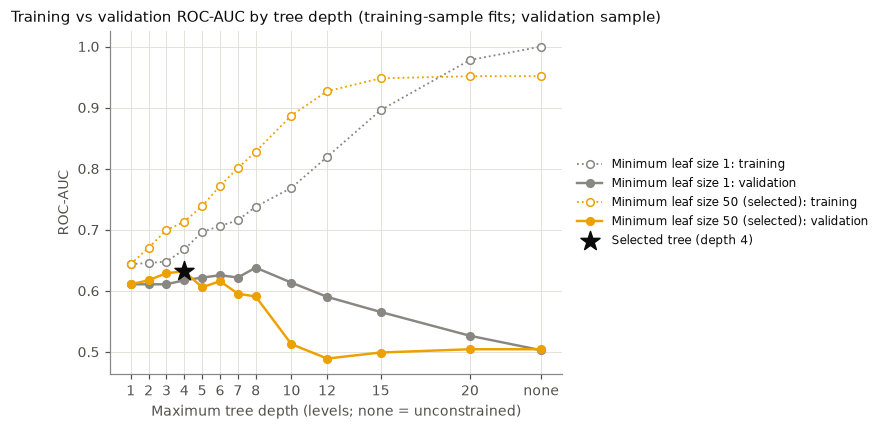

In [26]:
# ---- depth curves and the unconstrained tree --------------------------------------------------
SEL_LEAF = DT_BEST["min_samples_leaf"]
CURVE_LEAVES = {"leaf1": 1, "leafsel": SEL_LEAF}
DEPTH_CURVE = {}
for _key, _leaf in CURVE_LEAVES.items():
    _rows = []
    for _d in CURVE_DEPTHS:
        _pipe = make_tree(DecisionTreeClassifier(max_depth=_d, min_samples_leaf=_leaf, random_state=SEED)).fit(X_train, y_train)
        _clf = _pipe.named_steps["clf"]
        _rows.append({"max_depth": _d, "depth": int(_clf.get_depth()), "n_leaves": int(_clf.get_n_leaves()),
                      "train_roc_auc": roc_auc(y_train, predict(_pipe, X_train)),
                      "val_roc_auc": roc_auc(y_valid, predict(_pipe, X_valid))})
        if _key == "leaf1" and _d is None:
            _tree = _clf.tree_
            _leaf_mask = _tree.children_left == -1
            _share_default = _tree.value[_leaf_mask, 0, 1]
            R["s3"]["unconstrained"] = {
                "depth": int(_clf.get_depth()), "n_leaves": int(_clf.get_n_leaves()),
                "train_roc_auc": _rows[-1]["train_roc_auc"], "val_roc_auc": _rows[-1]["val_roc_auc"],
                "mean_rows_per_leaf": float(len(y_train) / _clf.get_n_leaves()),
                "median_rows_per_leaf": float(np.median(_tree.n_node_samples[_leaf_mask])),
                "share_leaves_le5_rows": float(np.mean(_tree.n_node_samples[_leaf_mask] <= 5)),
                "share_leaves_no_default": float(np.mean(_share_default == 0.0))}
    DEPTH_CURVE[_key] = _rows
R["s3"]["depth_curve"] = DEPTH_CURVE
R["s3"]["depth_curve_leafsel_value"] = SEL_LEAF
_leaf1_vals = [r["val_roc_auc"] for r in DEPTH_CURVE["leaf1"]]
_best_i = select_first_best(_leaf1_vals)
R["s3"]["leaf1_best_val_depth"] = DEPTH_CURVE["leaf1"][_best_i]["max_depth"]

_curve_tab = pd.DataFrame({"Max depth": [("none" if r["max_depth"] is None else r["max_depth"]) for r in DEPTH_CURVE["leaf1"]],
                           "Leaf 1: levels": [r["depth"] for r in DEPTH_CURVE["leaf1"]],
                           "Leaf 1: leaves": [r["n_leaves"] for r in DEPTH_CURVE["leaf1"]],
                           "Leaf 1: train ROC-AUC": [r["train_roc_auc"] for r in DEPTH_CURVE["leaf1"]],
                           "Leaf 1: validation ROC-AUC": [r["val_roc_auc"] for r in DEPTH_CURVE["leaf1"]],
                           f"Leaf {SEL_LEAF}: leaves": [r["n_leaves"] for r in DEPTH_CURVE["leafsel"]],
                           f"Leaf {SEL_LEAF}: train ROC-AUC": [r["train_roc_auc"] for r in DEPTH_CURVE["leafsel"]],
                           f"Leaf {SEL_LEAF}: validation ROC-AUC": [r["val_roc_auc"] for r in DEPTH_CURVE["leafsel"]]})
show(_curve_tab, f"Tree depth curves: minimum leaf size 1 and the selected minimum leaf size ({SEL_LEAF})",
     formats={"Leaf 1: leaves": "int", f"Leaf {SEL_LEAF}: leaves": "int"})

UNC = R["s3"]["unconstrained"]
show(pd.DataFrame([{"Levels": UNC["depth"], "Leaves": UNC["n_leaves"], "Train ROC-AUC": UNC["train_roc_auc"],
                    "Validation ROC-AUC": UNC["val_roc_auc"], "Mean training rows per leaf": UNC["mean_rows_per_leaf"],
                    "Median training rows per leaf": UNC["median_rows_per_leaf"],
                    "Leaves with at most 5 training rows": UNC["share_leaves_le5_rows"],
                    "Leaves with no training default": UNC["share_leaves_no_default"]}]),
     "Unconstrained tree (no depth limit, minimum leaf size 1)",
     formats={"Leaves": "int", "Mean training rows per leaf": "f2", "Median training rows per leaf": "f2",
              "Leaves with at most 5 training rows": "pct1", "Leaves with no training default": "pct1"})

# ---- Figure: training and validation ROC-AUC against depth --------------------------------------
X_NONE = 24
fig, ax = plt.subplots(figsize=(7.5, 3.8), layout="constrained")
_xt = [X_NONE if d is None else d for d in CURVE_DEPTHS]
_styles = {"leaf1": ("#898781", "Minimum leaf size 1"), "leafsel": (MODEL_COLORS["m4"], f"Minimum leaf size {SEL_LEAF} (selected)")}
for _key, (_col, _lab) in _styles.items():
    _r = DEPTH_CURVE[_key]
    ax.plot(_xt, [r["train_roc_auc"] for r in _r], color=_col, linestyle=":", linewidth=1.2, marker="o", markersize=5,
            markerfacecolor="white", label=f"{_lab}: training")
    ax.plot(_xt, [r["val_roc_auc"] for r in _r], color=_col, linestyle="-", linewidth=1.6, marker="o", markersize=5,
            label=f"{_lab}: validation")
ax.scatter([DT_BEST["max_depth"]], [DT_BEST["val_roc_auc"]], marker="*", s=170, color="#0b0b0b", zorder=5,
           label=f"Selected tree (depth {DT_BEST['max_depth']})")
ax.set_xticks(_xt)
ax.set_xticklabels([("none" if d is None else str(d)) for d in CURVE_DEPTHS])
ax.set_xlabel("Maximum tree depth (levels; none = unconstrained)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Training vs validation ROC-AUC by tree depth (training-sample fits; validation sample)")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
save_fig(fig, "tree_depth_curve")


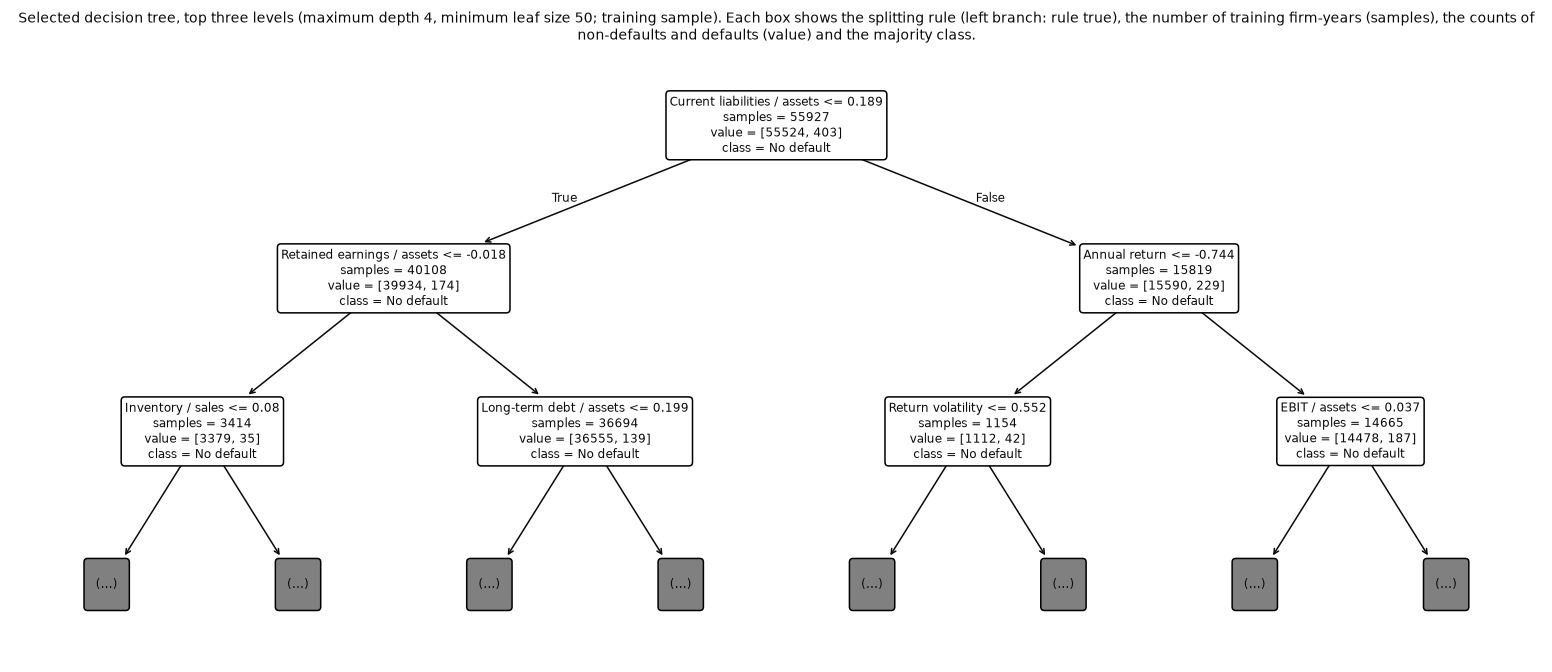

Splits in the top levels of the selected tree (training sample; level 0 = root)


Node,Level,Split on,Threshold (natural units),Firm-years,Defaults,Default rate,Left (<= threshold) firm-years,Left default rate,Right (> threshold) firm-years,Right default rate
0,0,Current liabilities / assets,0.189,"55,927",403,0.72%,"40,108",0.43%,"15,819",1.45%
1,1,Retained earnings / assets,-0.018,"40,108",174,0.43%,"3,414",1.03%,"36,694",0.38%
2,2,Inventory / sales,0.080,"3,414",35,1.03%,"3,364",0.95%,50,6.00%
7,2,Long-term debt / assets,0.199,"36,694",139,0.38%,"26,846",0.29%,"9,848",0.63%
14,1,Annual return,-0.744,"15,819",229,1.45%,"1,154",3.64%,"14,665",1.28%
15,2,Return volatility,0.552,"1,154",42,3.64%,"1,026",3.02%,128,8.59%
22,2,EBIT / assets,0.037,"14,665",187,1.28%,"2,783",1.98%,"11,882",1.11%


In [27]:
# ---- Tree plot and node table: upper levels of the selected tree -----------------------------------
DT_PIPE = DT_FITS[DT_SEL]["pipe"]
DT_CLF = DT_PIPE.named_steps["clf"]
TREE_FEATURES = list(CONT) + [f"industry_code_{k}" for k in INDUSTRY_LEVELS]
TREE_LABELS = [VAR_LABELS[v] for v in CONT] + [f"Industry {k}" for k in INDUSTRY_LEVELS]
assert list(DT_PIPE.named_steps["prep"].get_feature_names_out()) == TREE_FEATURES, "feature order must match the labels"

_t = DT_CLF.tree_
_frac = _t.value[:, 0, 1]
assert np.allclose(_t.value[:, 0, :].sum(axis=1), 1.0), "tree value must hold class fractions"
assert abs(_frac[0] - y_train.mean()) < 1e-12, "root default fraction must equal the training default rate"


def _node_depths(tree):
    depth = np.zeros(tree.node_count, dtype=int)
    for i in range(tree.node_count):
        if tree.children_left[i] != -1:
            depth[tree.children_left[i]] = depth[i] + 1
            depth[tree.children_right[i]] = depth[i] + 1
    return depth


_depth = _node_depths(_t)
_nodes = []
for _i in range(_t.node_count):
    if _t.children_left[_i] == -1 or _depth[_i] > 2:
        continue
    _lc, _rc = int(_t.children_left[_i]), int(_t.children_right[_i])
    _n = int(_t.n_node_samples[_i])
    _nodes.append({"node": _i, "depth": int(_depth[_i]), "feature": TREE_FEATURES[int(_t.feature[_i])],
                   "feature_label": TREE_LABELS[int(_t.feature[_i])], "threshold": float(_t.threshold[_i]),
                   "n": _n, "defaults": int(round(_frac[_i] * _n)), "rate": float(_frac[_i]),
                   "left_n": int(_t.n_node_samples[_lc]), "left_rate": float(_frac[_lc]),
                   "right_n": int(_t.n_node_samples[_rc]), "right_rate": float(_frac[_rc])})
R["s3"]["dt_nodes"] = _nodes

fig, ax = plt.subplots(figsize=(14.0, 6.0), layout="constrained")
plot_tree(DT_CLF, max_depth=2, proportion=False, impurity=False, filled=False, rounded=True, precision=3, fontsize=8,
          class_names=["No default", "Default"], feature_names=TREE_LABELS, ax=ax)
ax.set_title(f"Selected decision tree, top three levels (maximum depth {DT_BEST['max_depth']}, minimum leaf size "
             f"{DT_BEST['min_samples_leaf']}; training sample). Each box shows the splitting rule (left branch: rule true), "
             "the number of training firm-years (samples), the counts of non-defaults and defaults (value) and the majority class.")
ax.title.set_fontsize(9)
ax.title.set_wrap(True)
import re as _re
for _txt in ax.texts:  # show node counts as integers (plot_tree prints some as e.g. 174.0)
    _txt.set_text(_re.sub(r"value = \[([\d.]+), ([\d.]+)\]",
                         lambda m: f"value = [{int(round(float(m.group(1))))}, {int(round(float(m.group(2))))}]", _txt.get_text()))
save_fig(fig, "decision_tree_top")

_nt = pd.DataFrame([{"Node": r["node"], "Level": r["depth"], "Split on": r["feature_label"], "Threshold (natural units)": r["threshold"],
                     "Firm-years": r["n"], "Defaults": r["defaults"], "Default rate": r["rate"],
                     "Left (<= threshold) firm-years": r["left_n"], "Left default rate": r["left_rate"],
                     "Right (> threshold) firm-years": r["right_n"], "Right default rate": r["right_rate"]} for r in _nodes])
show(_nt, "Splits in the top levels of the selected tree (training sample; level 0 = root)",
     formats={"Firm-years": "int", "Defaults": "int", "Left (<= threshold) firm-years": "int",
              "Right (> threshold) firm-years": "int", "Default rate": "pct2", "Left default rate": "pct2",
              "Right default rate": "pct2"})



**Depth curve (figure above).** For a tree with no leaf-size limit (leaf size 1), training ROC-AUC rises steadily with depth, from 0.644 at depth 1 to 1.000 for the unconstrained tree. Validation ROC-AUC moves very little at first, peaks at depth 8 (0.638) and then falls to 0.503, which is close to a coin-flip ranking. With a minimum leaf size of 50 the same pattern appears earlier: validation ROC-AUC is highest at depth 4 and falls to 0.513 by depth 10 while training ROC-AUC keeps rising. The selected tree (depth 4, minimum leaf 50) has training ROC-AUC 0.713 and validation ROC-AUC 0.632. The depth curve is a diagnostic: the tuning grid was restricted to shallow trees (depth 2 to 6) by design, so the curve's peak (0.638 at depth 8) is not a candidate, and its gap to the selected tree (0.632) is not labelled by the resampling rule, so it should not be read as a difference. Across the ten grid settings validation ROC-AUC runs only from 0.601 to 0.632, so differences between nearby settings are small.

**Why a deep unconstrained tree overfits.** Left to grow, the tree reaches 39 levels and 725 leaves, with a median leaf holding 1 training firm-year; 64.7% of its leaves hold 5 rows or fewer and 50.3% contain no training default. Each leaf predicts the default rate of very few rows, so the tree memorizes training outcomes (training ROC-AUC 1.000) while its validation ROC-AUC (0.503) shows no ranking skill. With few defaults, many deep splits fit chance patterns, which is why unconstrained trees have high variance.

**Splits at the top of the selected tree (training sample).**

- *Current liabilities / assets at 0.189.* Firm-years above the threshold (15,819) have a default rate of 1.45%, against 0.43% below it (40,108); the node as a whole is 0.72%. Heavy short-term obligations relative to assets mark riskier firms, in line with the expected leverage and liquidity-pressure story.
- *Annual return at -0.744 among the high-liability firms.* Firm-years with a prior return at or below that cut (1,154) default at 3.64%, against 1.28% for the rest (14,665). A steep fall in the share price is the expected distress signal.
- A split lower in the tree, Retained earnings / assets at -0.018 among low-liability firms, separates a 1.03% default rate (negative accumulated earnings, 3,414 firm-years) from 0.38%.

These are rates of training firm-years in each branch, descriptive and not causal. Small branches, such as the 128 firm-years with a default rate of 8.59% under the Return volatility split, rest on few defaults.


In [28]:
# ---- Model 5: random forest grid ----------------------------------------------------------------
RF_FITS = []
for _d, _l, _mf in RF_GRID:
    _pipe = make_tree(RandomForestClassifier(n_estimators=RF_N_ESTIMATORS, max_depth=_d, min_samples_leaf=_l, max_features=_mf,
                                             random_state=SEED, n_jobs=N_JOBS)).fit(X_train, y_train)
    _pipe.named_steps["clf"].set_params(n_jobs=1)   # single-threaded prediction: fixed summation order of tree probabilities
    _pv, _pt = predict(_pipe, X_valid), predict(_pipe, X_train)
    RF_FITS.append({"pipe": _pipe, "val_prob": _pv, "train_prob": _pt})
    R["s3"].setdefault("rf_grid", []).append({
        "max_depth": _d, "min_samples_leaf": _l, "max_features": str(_mf), "train_roc_auc": roc_auc(y_train, _pt),
        "val_roc_auc": roc_auc(y_valid, _pv), "val_pr_auc": pr_auc(y_valid, _pv), "val_ks": ks_stat(y_valid, _pv)})
RF_SEL = select_first_best([r["val_roc_auc"] for r in R["s3"]["rf_grid"]])
RF_BEST = R["s3"]["rf_grid"][RF_SEL]
R["s3"]["selected"]["m5"] = {"max_depth": RF_BEST["max_depth"], "min_samples_leaf": RF_BEST["min_samples_leaf"],
                             "max_features": RF_BEST["max_features"]}

_tab = pd.DataFrame(R["s3"]["rf_grid"])
_tab["selected"] = ["selected" if i == RF_SEL else "" for i in range(len(_tab))]
_tab = _tab.rename(columns={"max_depth": "Max depth", "min_samples_leaf": "Min leaf size", "max_features": "Predictors per split",
                            "train_roc_auc": "Train ROC-AUC", "val_roc_auc": "Validation ROC-AUC",
                            "val_pr_auc": "Validation PR-AUC", "val_ks": "Validation KS", "selected": "Selection"})
show(_tab, f"Random forest grid ({RF_N_ESTIMATORS} trees per forest; fitted on training, scored on validation)")
print(f"Selected forest: maximum depth {RF_BEST['max_depth']}, minimum leaf size {RF_BEST['min_samples_leaf']}, "
      f"predictors per split {RF_BEST['max_features']} (validation ROC-AUC {fmt_num(RF_BEST['val_roc_auc'], 'f3')}).")


Random forest grid (200 trees per forest; fitted on training, scored on validation)


Max depth,Min leaf size,Predictors per split,Train ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation KS,Selection
6,100,sqrt,0.848,0.677,0.022,0.257,selected
6,100,0.33,0.859,0.664,0.023,0.262,
6,20,sqrt,0.876,0.676,0.020,0.259,
6,20,0.33,0.884,0.669,0.023,0.274,
12,100,sqrt,0.956,0.660,0.023,0.237,
12,100,0.33,0.961,0.655,0.023,0.260,
12,20,sqrt,0.995,0.662,0.017,0.264,
12,20,0.33,0.994,0.646,0.018,0.243,


Selected forest: maximum depth 6, minimum leaf size 100, predictors per split sqrt (validation ROC-AUC 0.677).


In [29]:
# ---- Model 6: XGBoost grid ------------------------------------------------------------------------
XGB_FITS = []
for _d, _lr, _n in XGB_GRID:
    _pipe = make_tree(XGBClassifier(n_estimators=_n, learning_rate=_lr, max_depth=_d, random_state=SEED, n_jobs=N_JOBS,
                                    **XGB_FIXED)).fit(X_train, y_train)
    _pv, _pt = predict(_pipe, X_valid), predict(_pipe, X_train)
    XGB_FITS.append({"pipe": _pipe, "val_prob": _pv, "train_prob": _pt})
    R["s3"].setdefault("xgb_grid", []).append({
        "max_depth": _d, "learning_rate": _lr, "n_estimators": _n, "train_roc_auc": roc_auc(y_train, _pt),
        "val_roc_auc": roc_auc(y_valid, _pv), "val_pr_auc": pr_auc(y_valid, _pv), "val_ks": ks_stat(y_valid, _pv)})
XGB_SEL = select_first_best([r["val_roc_auc"] for r in R["s3"]["xgb_grid"]])
XGB_BEST = R["s3"]["xgb_grid"][XGB_SEL]
R["s3"]["selected"]["m6"] = {"max_depth": XGB_BEST["max_depth"], "learning_rate": XGB_BEST["learning_rate"],
                             "n_estimators": XGB_BEST["n_estimators"]}

_tab = pd.DataFrame(R["s3"]["xgb_grid"])
_tab["selected"] = ["selected" if i == XGB_SEL else "" for i in range(len(_tab))]
_tab = _tab.rename(columns={"max_depth": "Max depth", "learning_rate": "Learning rate", "n_estimators": "Boosting rounds",
                            "train_roc_auc": "Train ROC-AUC", "val_roc_auc": "Validation ROC-AUC",
                            "val_pr_auc": "Validation PR-AUC", "val_ks": "Validation KS", "selected": "Selection"})
show(_tab, "XGBoost grid (fitted on training, scored on validation)", formats={"Learning rate": "f2"})
print(f"Selected XGBoost: {XGB_BEST['n_estimators']} rounds, learning rate {XGB_BEST['learning_rate']}, "
      f"maximum depth {XGB_BEST['max_depth']} (validation ROC-AUC {fmt_num(XGB_BEST['val_roc_auc'], 'f3')}).")


XGBoost grid (fitted on training, scored on validation)


Max depth,Learning rate,Boosting rounds,Train ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation KS,Selection
2,0.03,200,0.767,0.682,0.023,0.282,selected
2,0.03,500,0.818,0.673,0.021,0.274,
2,0.10,200,0.835,0.663,0.019,0.283,
2,0.10,500,0.906,0.652,0.020,0.238,
4,0.03,200,0.881,0.670,0.019,0.267,
4,0.03,500,0.958,0.645,0.019,0.237,
4,0.10,200,0.970,0.618,0.017,0.219,
4,0.10,500,0.999,0.576,0.019,0.142,


Selected XGBoost: 200 rounds, learning rate 0.03, maximum depth 2 (validation ROC-AUC 0.682).


In [30]:
# ---- the three selected tree models ---------------------------------------------------------------
_rf_mf = RF_GRID[RF_SEL][2]
TREES = {
    "m4": {"pipe": DT_FITS[DT_SEL]["pipe"], "params": dict(R["s3"]["selected"]["m4"]),
           "setting": f"depth {DT_BEST['max_depth']}, min leaf {DT_BEST['min_samples_leaf']}",
           "cont": list(CONT), "val_prob": DT_FITS[DT_SEL]["val_prob"], "train_prob": DT_FITS[DT_SEL]["train_prob"]},
    "m5": {"pipe": RF_FITS[RF_SEL]["pipe"],
           "params": {"max_depth": RF_BEST["max_depth"], "min_samples_leaf": RF_BEST["min_samples_leaf"], "max_features": _rf_mf},
           "setting": f"{RF_N_ESTIMATORS} trees, depth {RF_BEST['max_depth']}, min leaf {RF_BEST['min_samples_leaf']}, "
                      f"max features {_rf_mf}",
           "cont": list(CONT), "val_prob": RF_FITS[RF_SEL]["val_prob"], "train_prob": RF_FITS[RF_SEL]["train_prob"]},
    "m6": {"pipe": XGB_FITS[XGB_SEL]["pipe"], "params": dict(R["s3"]["selected"]["m6"]),
           "setting": f"{XGB_BEST['n_estimators']} rounds, learning rate {XGB_BEST['learning_rate']}, "
                      f"depth {XGB_BEST['max_depth']}",
           "cont": list(CONT), "val_prob": XGB_FITS[XGB_SEL]["val_prob"], "train_prob": XGB_FITS[XGB_SEL]["train_prob"]},
}
R["s3"]["val"] = {}
R["s3"]["train_roc_auc"] = {}
for _m, _t in TREES.items():
    assert _t["val_prob"].dtype == np.float64 and _t["train_prob"].dtype == np.float64
    R["s3"]["val"][_m] = {"roc_auc": roc_auc(y_valid, _t["val_prob"]), "pr_auc": pr_auc(y_valid, _t["val_prob"]),
                          "ks": ks_stat(y_valid, _t["val_prob"])}
    R["s3"]["train_roc_auc"][_m] = roc_auc(y_train, _t["train_prob"])

_tab = pd.DataFrame([{"Model": MODEL_NAMES[m], "Setting": TREES[m]["setting"],
                      "Train ROC-AUC": R["s3"]["train_roc_auc"][m], "Validation ROC-AUC": R["s3"]["val"][m]["roc_auc"],
                      "Validation PR-AUC": R["s3"]["val"][m]["pr_auc"], "Validation KS": R["s3"]["val"][m]["ks"]}
                     for m in TREE_MODELS])
show(_tab, "Selected tree-based models (validation sample)")


Selected tree-based models (validation sample)


Model,Setting,Train ROC-AUC,Validation ROC-AUC,Validation PR-AUC,Validation KS
Model 4: Decision tree,"depth 4, min leaf 50",0.713,0.632,0.016,0.227
Model 5: Random forest,"200 trees, depth 6, min leaf 100, max features sqrt",0.848,0.677,0.022,0.257
Model 6: XGBoost (boosted trees),"200 rounds, learning rate 0.03, depth 2",0.767,0.682,0.023,0.282



**Rule reminder.** A difference is called higher or lower only if the 95% firm-resampling interval excludes zero; otherwise similar.

**Random forest.** The selected forest has 200 trees, depth 6, minimum leaf 100 and sqrt predictors per split, with validation ROC-AUC 0.677 (training 0.848). It was selected by validation ROC-AUC by a small margin: the next forest setting (depth 6, minimum leaf 20, sqrt predictors per split) has 0.676, within 0.002. Validation ROC-AUC across the eight forests runs from 0.646 to 0.677. The deepest, smallest-leaf forests reach training ROC-AUC of 0.995 but validation ROC-AUC of only 0.662, so extra flexibility did not help on validation.

**XGBoost.** The selected model uses 200 rounds, learning rate 0.03 and depth 2, with validation ROC-AUC 0.682 (training 0.767). It was selected by validation ROC-AUC by a small margin: the next XGBoost setting (500 rounds, otherwise the same) has 0.673, within 0.01. The most flexible setting (depth 4, learning rate 0.1, 500 rounds) has training ROC-AUC 0.999 and validation ROC-AUC 0.576, a clear case of overfitting; the best settings are the shallow, slowly learning ones. With few defaults and a weak signal, closer fits to the training data mostly capture noise.

**Single tree, forest and boosting on validation.** ROC-AUC is 0.632 for the tree, 0.677 for the forest and 0.682 for XGBoost (PR-AUC 0.016, 0.022 and 0.023).

- The tree is lower than the forest (tree minus forest -0.045 [-0.072, -0.021]) and lower than XGBoost (-0.050 [-0.089, -0.012]). Averaging many trees (forest) mainly reduces the variance of a single tree, while boosting shallow trees mainly reduces bias, with the small learning rate (shrinkage) limiting variance.
- The forest and XGBoost are similar (forest minus XGBoost -0.005 [-0.029, +0.023]); these data do not show that boosting beats bagging.
- Compared with the best linear model by validation ROC-AUC, both ensembles are similar on validation: Ridge minus forest +0.020 [-0.010, +0.050] and Ridge minus XGBoost +0.015 [-0.004, +0.034]. The extra flexibility of the nonlinear ensembles brings no detectable validation gain here.

By validation ROC-AUC the best tree-based model is Model 6: XGBoost (boosted trees), by a small margin over the forest.


## 4. Class Imbalance Experiment

Defaults are rare: with a low base rate, fitted probabilities are small, so a 0.50 cutoff flags almost nothing. This section compares three ways of training one model family, the Model 1 specification (unpenalized logistic regression with 19 standardized ratios and nine industry dummies). Using one unpenalized specification means there is no penalty parameter to re-tune, so the comparison isolates the effect of the treatment.

### Treatments

- **Unweighted:** every training firm-year has weight one.
- **Class-weighted:** `class_weight="balanced"`. Each default gets weight n / (2 × number of defaults) and each non-default gets weight n / (2 × number of non-defaults), where n is the number of training firm-years, so the two classes carry equal total weight.
- **Random undersampling:** every training default is kept together with an equal-sized random sample of training non-defaults (1:1, random seed 42, drawn without replacement). Undersampling is applied to the training sample only. Validation and test samples are never rebalanced, so every metric below describes the natural class mix.

### Metrics and operating points

Threshold-free metrics are validation ROC-AUC, PR-AUC (average precision) and top-decile capture (the share of validation defaults that fall in the highest-risk decile, the tenth of firm-years with the highest predicted probability). Precision, recall and F1 need a cut-off, so they are shown at two operating points: the fixed 0.50 cutoff, which shows how rebalancing moves predicted probabilities, and each treatment's own validation F1-maximizing threshold, which shows what remains once a threshold is tuned. The F1-maximizing threshold is found on validation data only.

### Selection rule (fixed before looking at results)

Each rebalanced treatment is compared with the unweighted fit using a paired firm-cluster bootstrap on the validation sample: whole firms are resampled with replacement 2,000 times, all of a firm's firm-years together, and the same resamples are used for every treatment. A rebalanced treatment qualifies only if its validation PR-AUC is higher than the unweighted PR-AUC (the middle 95% of the resampled differences lies entirely above zero) and its validation ROC-AUC is not lower (the interval does not lie entirely below zero). Among qualifying treatments the one with the higher PR-AUC is chosen (a tie goes to class weighting). If no treatment qualifies, the unweighted fit is kept.

Rebalancing is adopted only for a clear gain in ranking defaults, which is what it is meant to improve; predicted probabilities are inflated by rebalancing and thresholds are tuned separately anyway.

### Propagation

The selected treatment applies to the final Model 1 only. Models 2 to 6 keep unweighted training: re-weighting the LASSO and Ridge fits would change the balance between likelihood and penalty for which their `C` was tuned, and keeping the imbalance comparison within one model family compares the treatments like for like.

A final display repeats the undersampling with 20 different random draws (consecutive seeds starting at 42) to show how much the validation metrics depend on which non-defaults are drawn. It is a robustness display only and plays no part in the selection.

In [31]:
# ---- fit the three treatments on the Model 1 specification --------------------------------------
def make_m1(**kw):
    return make_linear(M1_CONT, True, LogisticRegression(C=np.inf, solver="newton-cholesky", tol=1e-8,
                                                          max_iter=1000, **kw))


S4_IDX = undersample_index(y_train, SEED)            # positions within the training arrays only
S4_FIT = {
    "unweighted": {"pipe": make_m1().fit(X_train, y_train), "n": len(y_train), "d": int(y_train.sum())},
    "weighted": {"pipe": make_m1(class_weight="balanced").fit(X_train, y_train), "n": len(y_train),
                 "d": int(y_train.sum())},
    "undersampled": {"pipe": make_m1().fit(X_train.iloc[S4_IDX], y_train[S4_IDX]), "n": len(S4_IDX),
                     "d": int(y_train[S4_IDX].sum())},
}
S4_PROB = {t: predict(f["pipe"], X_valid) for t, f in S4_FIT.items()}
assert np.allclose(S4_PROB["unweighted"], LINEAR["m1"]["val_prob"], atol=1e-10, rtol=0), "unweighted fit differs from Model 1"
print("The unweighted treatment reproduces the Model 1 fit of Section 2.")

R["s4"]["spec"] = "m1"
R["s4"]["val_rate"] = float(y_valid.mean())
R["s4"]["treatments"] = {}
rank_rows, op_rows = [], []
for t in TREATMENTS:
    p, f = S4_PROB[t], S4_FIT[t]
    thr_f1, _ = max_f1_threshold(y_valid, p)
    points = {"at_050": threshold_metrics(y_valid, p, CUTOFF), "at_f1": threshold_metrics(y_valid, p, thr_f1)}
    entry = {"n_train": f["n"], "n_train_defaults": f["d"], "roc_auc": roc_auc(y_valid, p), "pr_auc": pr_auc(y_valid, p),
             "top_decile": top_decile_capture(y_valid, p), "mean_pred": float(p.mean()),
             "intercept": float(f["pipe"].named_steps["clf"].intercept_[0])}
    for key, pt in points.items():
        entry[key] = {k: pt[k] for k in ("threshold", "flagged", "tp", "fp", "precision", "recall", "f1")}
        if pt["flagged"] == 0:
            del entry[key]["precision"]          # undefined when nothing is flagged
    R["s4"]["treatments"][t] = entry
    rank_rows.append({"Treatment": TREATMENT_NAMES[t], "Training firm-years": fmt_num(f["n"], "int"), "Training defaults": fmt_num(f["d"], "int"),
                      "ROC-AUC": entry["roc_auc"], "PR-AUC": entry["pr_auc"],
                      "Top-decile capture": fmt_num(entry["top_decile"], "pct1"),
                      "Mean predicted PD": fmt_num(entry["mean_pred"], "pct2"), "Intercept": entry["intercept"]})
    for key, label in (("at_050", "0.50 cutoff"), ("at_f1", "Own max-F1 threshold")):
        pt = points[key]
        op_rows.append({"Treatment": TREATMENT_NAMES[t], "Operating point": label, "Threshold": fmt_num(pt["threshold"], "f4"),
                        "Flagged": fmt_num(pt["flagged"], "int"), "True positives": fmt_num(pt["tp"], "int"), "False positives": fmt_num(pt["fp"], "int"),
                        "Precision": fmt_num(pt["precision"], "pct1") if pt["flagged"] else "n/a, none flagged",
                        "Recall": fmt_num(pt["recall"], "pct1"), "F1": fmt_num(pt["f1"], "f3")})
print(f"Validation sample: {len(y_valid):,} firm-years, {int(y_valid.sum())} defaults "
      f"(default rate {fmt_num(R['s4']['val_rate'], 'pct2')}).")
show(pd.DataFrame(rank_rows), "Model 1 specification under three treatments: ranking metrics (validation sample)")
show(pd.DataFrame(op_rows), "Precision, recall and F1 at two operating points (validation sample)")


The unweighted treatment reproduces the Model 1 fit of Section 2.
Validation sample: 10,473 firm-years, 87 defaults (default rate 0.83%).
Model 1 specification under three treatments: ranking metrics (validation sample)


Treatment,Training firm-years,Training defaults,ROC-AUC,PR-AUC,Top-decile capture,Mean predicted PD,Intercept
Unweighted,"55,927",403,0.690,0.025,29.9%,0.51%,-5.175
Class-weighted (balanced),"55,927",403,0.687,0.025,31.0%,36.65%,-0.237
Random undersampling (1:1),806,403,0.662,0.021,28.7%,37.41%,0.142


Precision, recall and F1 at two operating points (validation sample)


Treatment,Operating point,Threshold,Flagged,True positives,False positives,Precision,Recall,F1
Unweighted,0.50 cutoff,0.5000,0,0,0,"n/a, none flagged",0.0%,0.000
Unweighted,Own max-F1 threshold,0.0203,105,7,98,6.7%,8.0%,0.073
Class-weighted (balanced),0.50 cutoff,0.5000,"2,127",39,"2,088",1.8%,44.8%,0.035
Class-weighted (balanced),Own max-F1 threshold,0.7690,86,7,79,8.1%,8.0%,0.081
Random undersampling (1:1),0.50 cutoff,0.5000,"2,493",37,"2,456",1.5%,42.5%,0.029
Random undersampling (1:1),Own max-F1 threshold,0.7599,183,11,172,6.0%,12.6%,0.081


In [32]:
# ---- paired bootstrap against the unweighted fit and the selection rule -------------------------
S4_BOOT = paired_bootstrap(y_valid, S4_PROB, g_valid)
S4_POINT = {t: {"roc_auc": R["s4"]["treatments"][t]["roc_auc"], "pr_auc": R["s4"]["treatments"][t]["pr_auc"],
                "top_decile": R["s4"]["treatments"][t]["top_decile"]} for t in TREATMENTS}
R["s4"]["diff"], R["s4"]["qualifies"] = {}, {}
rows = []
for t in ("weighted", "undersampled"):
    R["s4"]["diff"][t] = {m: pair_summary(S4_POINT[t][m], S4_POINT["unweighted"][m], S4_BOOT[t][m], S4_BOOT["unweighted"][m])
                          for m in ("roc_auc", "pr_auc", "top_decile")}
    d = R["s4"]["diff"][t]
    R["s4"]["qualifies"][t] = bool(d["pr_auc"]["label"] == "higher" and d["roc_auc"]["label"] != "lower")
    for m, name, spec, dspec in (("roc_auc", "ROC-AUC", "f3", "sf3"), ("pr_auc", "PR-AUC", "f3", "sf3"),
                                 ("top_decile", "Top-decile capture", "pct1", "pp1")):
        rows.append({"Treatment minus unweighted": TREATMENT_NAMES[t], "Metric": name,
                     "Treatment": fmt_num(d[m]["a"], spec), "Unweighted": fmt_num(d[m]["b"], spec),
                     "Difference": fmt_num(d[m]["d"], dspec),
                     "95% interval": f"[{fmt_num(d[m]['lo'], dspec)}, {fmt_num(d[m]['hi'], dspec)}]",
                     "Label": d[m]["label"]})
show(pd.DataFrame(rows), "Paired firm-cluster bootstrap on validation data (2,000 resamples): rebalanced treatment minus unweighted")

qualifiers = [t for t in ("weighted", "undersampled") if R["s4"]["qualifies"][t]]
if not qualifiers:
    TREATMENT = "unweighted"
    reason = ("neither rebalanced treatment has a validation PR-AUC that is higher than the unweighted fit with an "
              "interval above zero while keeping ROC-AUC from falling, so the unweighted fit is kept")
elif len(qualifiers) == 1:
    TREATMENT = qualifiers[0]
    reason = (f"{TREATMENT_NAMES[TREATMENT]} is the only treatment with a higher PR-AUC (interval above zero) "
              "and a ROC-AUC that is not lower")
else:
    pr_w, pr_u = S4_POINT["weighted"]["pr_auc"], S4_POINT["undersampled"]["pr_auc"]
    TREATMENT = "undersampled" if pr_u > pr_w else "weighted"
    reason = ("both rebalanced treatments qualify, and " + TREATMENT_NAMES[TREATMENT] + " has the higher validation PR-AUC ("
              + f"{fmt_num(S4_POINT[TREATMENT]['pr_auc'], 'f3')} against "
              + f"{fmt_num(S4_POINT['weighted' if TREATMENT == 'undersampled' else 'undersampled']['pr_auc'], 'f3')})")
R["s4"]["selected"] = TREATMENT
M1_FINAL = {"pipe": S4_FIT[TREATMENT]["pipe"], "treatment": TREATMENT, "val_prob": S4_PROB[TREATMENT].copy(),
            "n_train_rows": int(S4_FIT[TREATMENT]["n"]), "n_train_defaults": int(S4_FIT[TREATMENT]["d"])}
print(f"Qualifying treatments: {', '.join(TREATMENT_NAMES[t] for t in qualifiers) if qualifiers else 'none'}.")
print(f"Selected treatment for the final Model 1: {TREATMENT_NAMES[TREATMENT]}; {reason}.")
print("Models 2 to 6 keep unweighted training.")

neg_kept = int(np.sum(y_train[S4_IDX] == 0))
record_check("undersampling_train_only",
             bool(S4_IDX.max() < len(y_train) and len(np.unique(S4_IDX)) == len(S4_IDX)
                  and int(y_train[S4_IDX].sum()) == int(y_train.sum()) and neg_kept == int(y_train.sum())
                  and len(y_valid) == int(IS_VALID.sum()) and len(X_valid) == int(IS_VALID.sum())
                  and len(g_test) == int(IS_TEST.sum()) and len(y_train) == int(IS_TRAIN.sum())),
             "undersampling used training positions only, kept every training default, drew as many non-defaults, "
             "and left the validation and test samples at their full size")


Paired firm-cluster bootstrap on validation data (2,000 resamples): rebalanced treatment minus unweighted


Treatment minus unweighted,Metric,Treatment,Unweighted,Difference,95% interval,Label
Class-weighted (balanced),ROC-AUC,0.687,0.690,-0.003,"[-0.013, +0.006]",similar
Class-weighted (balanced),PR-AUC,0.025,0.025,-0.001,"[-0.004, +0.003]",similar
Class-weighted (balanced),Top-decile capture,31.0%,29.9%,+1.1 pp,"[-2.5 pp, +3.8 pp]",similar
Random undersampling (1:1),ROC-AUC,0.662,0.690,-0.029,"[-0.052, -0.005]",lower
Random undersampling (1:1),PR-AUC,0.021,0.025,-0.004,"[-0.017, +0.002]",similar
Random undersampling (1:1),Top-decile capture,28.7%,29.9%,-1.1 pp,"[-7.6 pp, +5.0 pp]",similar


Qualifying treatments: none.
Selected treatment for the final Model 1: Unweighted; neither rebalanced treatment has a validation PR-AUC that is higher than the unweighted fit with an interval above zero while keeping ROC-AUC from falling, so the unweighted fit is kept.
Models 2 to 6 keep unweighted training.
  passed: undersampling used training positions only, kept every training default, drew as many non-defaults, and left the validation and test samples at their full size


In [33]:
# ---- undersampling robustness: 20 random draws -------------------------------------------------
draw_rows = []
for k in range(UNDERSAMPLE_DRAWS):
    idx = undersample_index(y_train, SEED + k)
    p = predict(make_m1().fit(X_train.iloc[idx], y_train[idx]), X_valid)
    draw_rows.append({"seed": SEED + k, "roc_auc": roc_auc(y_valid, p), "pr_auc": pr_auc(y_valid, p),
                      "top_decile": top_decile_capture(y_valid, p)})
draws = pd.DataFrame(draw_rows)
assert abs(draws.loc[0, "roc_auc"] - R["s4"]["treatments"]["undersampled"]["roc_auc"]) < 1e-12, "adopted draw differs"
R["s4"]["under_draws"] = {"n": int(len(draws)), **{
    m: {"main": float(draws.loc[0, m]), "mean": float(draws[m].mean()), "min": float(draws[m].min()),
        "max": float(draws[m].max())} for m in ("roc_auc", "pr_auc", "top_decile")}}
rows = []
for m, name, spec in (("roc_auc", "ROC-AUC", "f3"), ("pr_auc", "PR-AUC", "f3"), ("top_decile", "Top-decile capture", "pct1")):
    u = R["s4"]["under_draws"][m]
    rows.append({"Metric (validation)": name, "Adopted draw (seed 42)": fmt_num(u["main"], spec),
                 "Mean of 20 draws": fmt_num(u["mean"], spec), "Minimum": fmt_num(u["min"], spec),
                 "Maximum": fmt_num(u["max"], spec)})
show(pd.DataFrame(rows), "Random undersampling repeated with 20 draws (consecutive seeds starting at 42): robustness display, not used for selection")
print(f"The unweighted fit has validation ROC-AUC {fmt_num(S4_POINT['unweighted']['roc_auc'], 'f3')} and "
      f"PR-AUC {fmt_num(S4_POINT['unweighted']['pr_auc'], 'f3')} for comparison.")


Random undersampling repeated with 20 draws (consecutive seeds starting at 42): robustness display, not used for selection


Metric (validation),Adopted draw (seed 42),Mean of 20 draws,Minimum,Maximum
ROC-AUC,0.662,0.677,0.659,0.697
PR-AUC,0.021,0.023,0.020,0.029
Top-decile capture,28.7%,28.2%,21.8%,32.2%


The unweighted fit has validation ROC-AUC 0.690 and PR-AUC 0.025 for comparison.


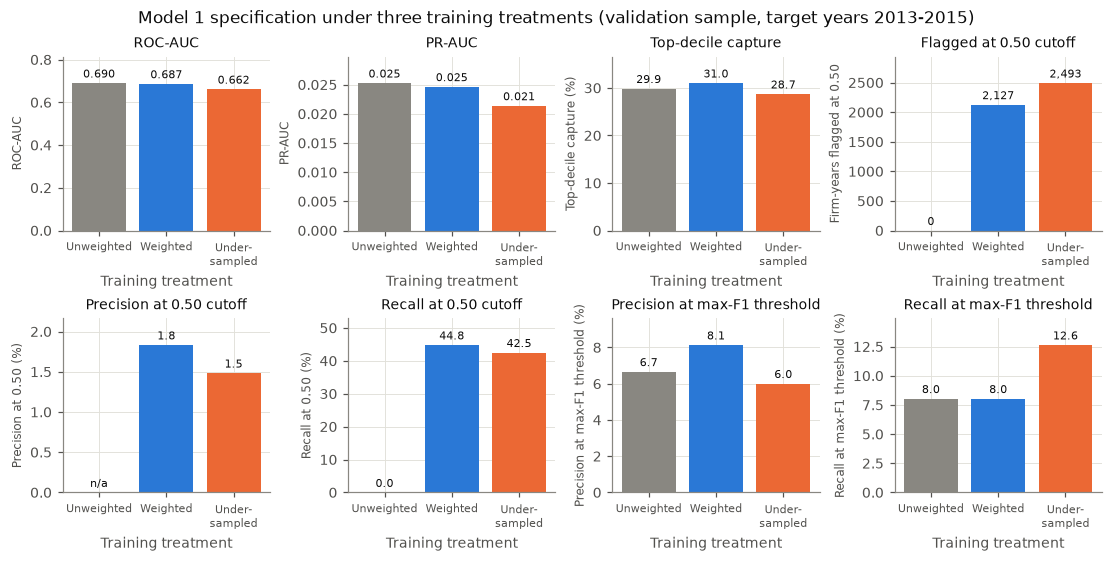

In [34]:
# ---- Figure: treatment comparison ---------------------------------------------------------------
def tv(t, key, field=None):
    e = R["s4"]["treatments"][t]
    return e[key] if field is None else e[key].get(field)


panels = [
    ("ROC-AUC", "ROC-AUC", lambda t: tv(t, "roc_auc"), 1.0, "f3", None),
    ("PR-AUC", "PR-AUC", lambda t: tv(t, "pr_auc"), 1.0, "f3", None),
    ("Top-decile capture", "Top-decile capture (%)", lambda t: tv(t, "top_decile"), 100.0, "f1", None),
    ("Flagged at 0.50 cutoff", "Firm-years flagged at 0.50", lambda t: tv(t, "at_050", "flagged"), 1.0, "int", None),
    ("Precision at 0.50 cutoff", "Precision at 0.50 (%)", lambda t: tv(t, "at_050", "precision"), 100.0, "f1", "at_050"),
    ("Recall at 0.50 cutoff", "Recall at 0.50 (%)", lambda t: tv(t, "at_050", "recall"), 100.0, "f1", None),
    ("Precision at max-F1 threshold", "Precision at max-F1 threshold (%)", lambda t: tv(t, "at_f1", "precision"), 100.0, "f1", "at_f1"),
    ("Recall at max-F1 threshold", "Recall at max-F1 threshold (%)", lambda t: tv(t, "at_f1", "recall"), 100.0, "f1", None),
]
tick_names = {"unweighted": "Unweighted", "weighted": "Weighted", "undersampled": "Under-\nsampled"}
fig, axes = plt.subplots(2, 4, figsize=(10.0, 5.0), layout="constrained")
for ax, (title, ylabel, getter, scale, spec, none_key) in zip(axes.ravel(), panels):
    vals = []
    for t in TREATMENTS:
        v = getter(t)
        vals.append(np.nan if v is None else float(v) * scale)
    heights = np.nan_to_num(vals, nan=0.0)
    bars = ax.bar(range(len(TREATMENTS)), heights, color=[TREATMENT_COLORS[t] for t in TREATMENTS])
    top = max(heights.max(), 1e-9)
    for bar, v in zip(bars, vals):
        label = "n/a" if np.isnan(v) else (f"{int(round(v)):,}" if spec == "int" else f"{v:.3f}" if spec == "f3" else f"{v:.1f}")
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02 * top, label, ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, top * 1.18)
    ax.set_axisbelow(True)
    ax.set_xticks(range(len(TREATMENTS)), [tick_names[t] for t in TREATMENTS], fontsize=7)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Training treatment")
    ax.set_ylabel(ylabel, fontsize=8)
fig.suptitle("Model 1 specification under three training treatments (validation sample, target years 2013-2015)")
save_fig(fig, "imbalance_comparison")



All figures are on the validation sample (87 defaults in 10,473 firm-years, default rate 0.83%). Rule for comparisons: a rebalanced fit is called higher or lower than the unweighted fit only if the 95% firm-resampling interval of the difference excludes zero; otherwise similar.

**Effect on ranking.**

- *Class weighting:* ROC-AUC 0.687 against 0.690 unweighted (difference -0.003 [-0.013, +0.006]), PR-AUC 0.025 against 0.025 (-0.001 [-0.004, +0.003]) and top-decile capture 31.0% against 29.9% (+1.1 percentage points [-2.5, +3.8]). All three are similar: weighting leaves ranking unchanged within noise.
- *Random undersampling (1:1, 806 training rows):* ROC-AUC 0.662 is lower than unweighted (-0.029 [-0.052, -0.005]); PR-AUC 0.021 (-0.004 [-0.017, +0.002]) and top-decile capture 28.7% (-1.1 percentage points [-7.6, +5.0]) are similar.

**Variability of undersampling.** Over 20 random draws, validation ROC-AUC ranges from 0.659 to 0.697 (mean 0.677) and top-decile capture from 21.8% to 32.2%. The adopted draw (0.662) is near the low end, and the best draw exceeds the unweighted ROC-AUC of 0.690, so the "lower" label for undersampling depends partly on which non-defaults were drawn. Fitting on only 806 rows makes the result sensitive to the draw.

**The 0.50 cutoff.** Rebalancing moves the operating point far more than the ranking. The unweighted model flags no validation firm-year at 0.50 (its mean predicted probability is 0.51%). The weighted and undersampled models have mean predicted probabilities of 36.65% and 37.41%, far above the observed 0.83%, so their probabilities are not calibrated. At 0.50 they flag 2,127 and 2,493 firm-years and recall jumps to 44.8% and 42.5%, but precision is only 1.8% and 1.5%.

**Trade-off between detection and false positives.** At 0.50 the weighted fit catches 39 defaults with 2,088 false positives, and the undersampled fit catches 37 with 2,456: more detection is bought with many more false alarms. Once each treatment gets its own max-F1 threshold the picture is much closer: the unweighted fit (threshold 0.0203) flags 105 with 7 defaults (precision 6.7%, recall 8.0%), the weighted fit (0.7690) flags 86 with 7 defaults (8.1%, 8.0%) and the undersampled fit (0.7599) flags 183 with 11 (6.0%, 12.6%). These counts rest on at most 11 detected defaults and carry no resampling interval, so differences between them should not be over-read. Thresholds are tuned on validation (in-sample there), and the right cut-off in practice depends on the relative cost of a missed default and a false alarm.

**Selection.** Under the pre-specified rule a rebalanced treatment must have higher PR-AUC without lower ROC-AUC. Neither does, so the selected treatment is Unweighted, and the final Model 1 is unweighted. Models 2 to 6 also stay unweighted.


## 5. Final Out-of-Sample Evaluation and Risk Deciles

This section fixes every modelling choice, then scores the frozen models once on the test years.

**Final specifications.** The final models are the training-fitted models selected in Sections 2 to 4: Model 1 (with the class-imbalance treatment chosen in Section 4), Models 2 and 3 with the penalty strength chosen on validation, and Models 4 to 6 with the tree, forest and boosting settings chosen on validation. Nothing is refitted on training plus validation rows, so every threshold and calibration map below is validated on the same fitted models that are later tested.

**Thresholds.** For each model, the classification threshold is the validation probability that maximizes F1 (the harmonic mean of precision and recall) on the precision-recall curve; ties go to the highest threshold, which flags fewer firm-years. A firm-year is flagged when its predicted probability is at least the threshold. The same threshold is applied to the test years. A fixed 0.50 cutoff is also reported to show what a conventional cutoff does when defaults are rare.

**Metrics.**
- ROC-AUC: probability that a randomly chosen default is ranked above a randomly chosen non-default.
- PR-AUC: average precision, the area under the precision-recall curve.
- KS: the largest gap between the true positive rate and the false positive rate over all cutoffs.
- Precision, recall and F1 at the validation threshold: precision = share of flagged firm-years that default; recall = share of defaults that are flagged.
- Top-decile capture: share of all defaults that fall in the 10% of firm-years with the highest predicted probability.
- Misclassification rate: share of firm-years whose flag disagrees with the outcome.

**Deciles.** Firm-years are sorted by predicted probability from highest to lowest, ties are broken with a fixed random key, and the sorted list is cut into 10 groups of equal size (sizes differ by at most one). Decile 1 = highest predicted risk and Decile 10 = lowest. The cumulative capture at Decile k is the share of all defaults in Deciles 1 to k.

**Best-model and deployment rules (validation only).** The best linear model, best tree-based model, best ensemble and best overall model are those with the highest validation ROC-AUC; models within 0.0001 are treated as tied and the lower model number wins. If the best overall model is linear, it is the deployment candidate and the best tree-based model is the challenger. Otherwise the best linear model is the deployment candidate unless its validation ROC-AUC is clearly lower than that of the best overall model (the interval rule below), in which case the best overall model is the deployment candidate and the best linear model is the challenger. The linear preference is deliberate: a transparent, auditable model is preferred unless a non-linear model is clearly better under the resampling rule, because a small and noisy margin does not justify the added complexity.

**Comparison rule.** Two models are compared by resampling whole firms (all of a firm's firm-years together) with replacement 2,000 times, using the same resampled firms for every model, and recomputing each metric. If the middle 95% of the differences lies entirely above zero, the first model is called higher; if it lies entirely below zero, lower; otherwise similar. This is a descriptive resampling check: it reflects firm sampling noise only and ignores year-to-year (regime) uncertainty. With few defaults, small gaps can be noise.

**Calibration maps.** For each model a Platt map (logistic regression on the log-odds of the predicted probability) is fitted on validation predictions; for the best overall model an isotonic regression is also fitted on validation predictions. Platt scaling is the primary calibration map and isotonic regression is a comparison only; both are recorded in the frozen choices and frozen before the test years are scored.

**Freeze and test lock.** Test outcomes stay locked until one cell has displayed every frozen choice and a digest (a cryptographic fingerprint) of all of them. That cell unlocks the test outcomes; the very next cell reads them once, checks that the digest is unchanged and produces all test predictions. Test outcomes enter only Section 1's aggregate counts and data-integrity checks (one default per firm, raw/model agreement); none is used for any model, setting, threshold or calibration before the freeze. No final model is fitted, tuned or selected after the unlock; the only later fits are the descriptive Section 7 sub-models on training rows. Test outcomes only score the frozen predictions and feed descriptive summaries.

### Final specifications, thresholds and calibration maps

The next cell assembles the six final models, computes their validation metrics, thresholds and Platt maps, compares them on validation, applies the best-model and deployment rules, and fits the isotonic map for the best overall model.

In [35]:
# ---- final specifications: selections of Sections 2-4, fitted on training rows only ------------------
FINAL = {}
for mk in MODELS:
    base = LINEAR[mk] if mk in LINEAR else TREES[mk]
    treat = M1_FINAL["treatment"] if mk == "m1" else "unweighted"
    setting = base["setting"] + ("" if treat == "unweighted" else "; " + TREATMENT_NAMES[treat].lower())
    FINAL[mk] = {"pipe": M1_FINAL["pipe"] if mk == "m1" else base["pipe"], "name": MODEL_NAMES[mk],
                 "short": MODEL_SHORT[mk], "setting": setting, "treatment": treat, "cont": list(base["cont"]),
                 "val_prob": M1_FINAL["val_prob"] if mk == "m1" else base["val_prob"]}
    assert len(FINAL[mk]["val_prob"]) == len(y_valid)
N_TRAIN_USED = {mk: (int(M1_FINAL["n_train_rows"]), int(M1_FINAL["n_train_defaults"])) if mk == "m1"
                else (int(len(y_train)), int(y_train.sum())) for mk in MODELS}

# ---- validation metrics, max-F1 thresholds and Platt maps ----------------------------------------------
VAL = {}
for mk in MODELS:
    vp = FINAL[mk]["val_prob"]
    thr, _ = max_f1_threshold(y_valid, vp)
    FINAL[mk]["threshold"] = thr
    FINAL[mk]["platt"] = fit_platt(vp, y_valid)
    tv = threshold_metrics(y_valid, vp, thr)
    VAL[mk] = {**rank_metrics(y_valid, vp), "recall": tv["recall"], "f1": tv["f1"]}
    if tv["flagged"] > 0:       # precision is undefined when nothing is flagged: the key is omitted
        VAL[mk]["precision"] = tv["precision"]
NA_TEXT = "n/a (none flagged)"

# ---- validation paired bootstrap (firm clusters): intervals and all 15 pairs ---------------------------
VAL_BOOT = paired_bootstrap(y_valid, {mk: FINAL[mk]["val_prob"] for mk in MODELS}, g_valid)
R["s5"]["final"] = {}
for mk in MODELS:
    v = dict(VAL[mk])
    for metric in ("roc_auc", "pr_auc"):
        v[metric + "_lo"], v[metric + "_hi"] = metric_interval(VAL_BOOT[mk][metric])
    R["s5"]["final"][mk] = {"name": MODEL_NAMES[mk], "setting": FINAL[mk]["setting"], "treatment": FINAL[mk]["treatment"],
                            "threshold": FINAL[mk]["threshold"], "val": v}
R["s5"]["compare_val"] = {}
for i, mi in enumerate(MODELS):
    for mj in MODELS[i + 1:]:
        R["s5"]["compare_val"][f"{mi}_vs_{mj}"] = {
            metric: pair_summary(VAL[mi][metric], VAL[mj][metric], VAL_BOOT[mi][metric], VAL_BOOT[mj][metric])
            for metric in ("roc_auc", "pr_auc")}
assert len(R["s5"]["compare_val"]) == 15

# ---- best models and the deployment rule (validation ROC-AUC only) ---------------------------------------
def best_of(keys):
    return keys[select_first_best([VAL[k]["roc_auc"] for k in keys])]


BEST = {"linear": best_of(LINEAR_MODELS), "tree": best_of(TREE_MODELS), "overall": best_of(MODELS),
        "ensemble": best_of(ENSEMBLE_MODELS)}
if BEST["overall"] in LINEAR_MODELS:
    BEST["deploy"], BEST["challenger"] = BEST["overall"], BEST["tree"]
    DEPLOY_LABEL = "not needed"
else:
    DEPLOY_LABEL = R["s5"]["compare_val"][f"{BEST['linear']}_vs_{BEST['overall']}"]["roc_auc"]["label"]
    if DEPLOY_LABEL == "lower":
        BEST["deploy"], BEST["challenger"] = BEST["overall"], BEST["linear"]
    else:
        BEST["deploy"], BEST["challenger"] = BEST["linear"], BEST["overall"]
R["s5"]["best"] = dict(BEST)
R["s5"]["deploy_rule_label"] = DEPLOY_LABEL

# ---- isotonic map for the best overall model (comparison to the Platt map) -----------------------------
ISO = fit_isotonic(FINAL[BEST["overall"]]["val_prob"], y_valid)


def ci_text(v, lo, hi, spec="f3"):
    return f"{fmt_num(v, spec)} [{fmt_num(lo, spec)}, {fmt_num(hi, spec)}]"


def pair_name(key):
    a, b = key.split("_vs_")
    return f"{MODEL_SHORT[a]} vs {MODEL_SHORT[b]}"


rows = []
for mk in MODELS:
    v = R["s5"]["final"][mk]["val"]
    rows.append({"Model": MODEL_NAMES[mk], "Setting": FINAL[mk]["setting"],
                 "Training firm-years": N_TRAIN_USED[mk][0], "Training defaults": N_TRAIN_USED[mk][1],
                 "Validation ROC-AUC [95% interval]": ci_text(v["roc_auc"], v["roc_auc_lo"], v["roc_auc_hi"]),
                 "PR-AUC [95% interval]": ci_text(v["pr_auc"], v["pr_auc_lo"], v["pr_auc_hi"]),
                 "KS": v["ks"], "Threshold": FINAL[mk]["threshold"], "Precision": v.get("precision", NA_TEXT),
                 "Recall": v["recall"], "F1": v["f1"]})
show(pd.DataFrame(rows), "Final specifications (validation sample; threshold = validation max-F1)",
     formats={"Training firm-years": "int", "Training defaults": "int", "KS": "f3", "Threshold": "f4",
              "Precision": "pct1", "Recall": "pct1", "F1": "f3"})

print("Validation ROC-AUC, pairwise (first model minus second model), label from the firm-resampling interval:")
rows = []
for key, comp in R["s5"]["compare_val"].items():
    c = comp["roc_auc"]
    rows.append({"Pair": pair_name(key), "Difference [95% interval]": ci_text(c["d"], c["lo"], c["hi"], "sf3"),
                 "Label": c["label"]})
show(pd.DataFrame(rows))
print("Note: a bound shown as 0 means the interval just reaches zero; such pairs are labelled similar.")
print("Best models by validation ROC-AUC: linear = " + MODEL_NAMES[BEST["linear"]] + "; tree-based = "
      + MODEL_NAMES[BEST["tree"]] + "; ensemble = " + MODEL_NAMES[BEST["ensemble"]] + "; overall = "
      + MODEL_NAMES[BEST["overall"]] + ".")
print("Deployment rule label (best linear vs best overall, validation ROC-AUC): " + DEPLOY_LABEL + ". Deployment "
      "candidate = " + MODEL_NAMES[BEST["deploy"]] + "; challenger = " + MODEL_NAMES[BEST["challenger"]] + ".")

# ---- checks: thresholds and calibration maps come from validation predictions only --------------------
thr_ok = all(max_f1_threshold(y_valid, FINAL[mk]["val_prob"])[0] == FINAL[mk]["threshold"] for mk in MODELS)
record_check("thresholds_from_validation", thr_ok,
             "every threshold equals the max-F1 threshold recomputed from validation predictions and validation outcomes")
cal_dev = 0.0
for mk in MODELS:
    refit = fit_platt(FINAL[mk]["val_prob"], y_valid)
    cal_dev = max(cal_dev, abs(float(refit.intercept_[0]) - float(FINAL[mk]["platt"].intercept_[0])),
                  abs(float(refit.coef_[0, 0]) - float(FINAL[mk]["platt"].coef_[0, 0])))
iso_refit = fit_isotonic(FINAL[BEST["overall"]]["val_prob"], y_valid)
cal_dev = max(cal_dev, float(np.max(np.abs(iso_refit.X_thresholds_ - ISO.X_thresholds_))),
              float(np.max(np.abs(iso_refit.y_thresholds_ - ISO.y_thresholds_))))
record_check("calibrators_fit_on_validation", cal_dev <= 1e-12 and len(iso_refit.X_thresholds_) == len(ISO.X_thresholds_),
             "refitting the Platt maps and the isotonic map on validation predictions reproduces the frozen maps "
             f"(largest deviation {cal_dev:.1e})")


Final specifications (validation sample; threshold = validation max-F1)


Model,Setting,Training firm-years,Training defaults,Validation ROC-AUC [95% interval],PR-AUC [95% interval],KS,Threshold,Precision,Recall,F1
Model 1: Logistic regression,no penalty; 19 continuous predictors + industry (reference: industry 1),"55,927",403,"0.690 [0.636, 0.748]","0.025 [0.016, 0.047]",0.303,0.0203,6.7%,8.0%,0.073
Model 2: LASSO logistic (L1),C = 0.1,"55,927",403,"0.696 [0.642, 0.752]","0.026 [0.017, 0.050]",0.301,0.0180,6.9%,10.3%,0.083
Model 3: Ridge logistic (L2),C = 0.01,"55,927",403,"0.697 [0.642, 0.754]","0.026 [0.017, 0.047]",0.311,0.0183,8.0%,10.3%,0.090
Model 4: Decision tree,"depth 4, min leaf 50","55,927",403,"0.632 [0.569, 0.691]","0.016 [0.011, 0.025]",0.227,0.0181,4.0%,12.6%,0.061
Model 5: Random forest,"200 trees, depth 6, min leaf 100, max features sqrt","55,927",403,"0.677 [0.618, 0.735]","0.022 [0.014, 0.039]",0.257,0.0176,7.2%,9.2%,0.081
Model 6: XGBoost (boosted trees),"200 rounds, learning rate 0.03, depth 2","55,927",403,"0.682 [0.626, 0.737]","0.023 [0.015, 0.040]",0.282,0.0181,6.9%,8.0%,0.074


Validation ROC-AUC, pairwise (first model minus second model), label from the firm-resampling interval:


Pair,Difference [95% interval],Label
M1 Logit vs M2 LASSO,"-0.006 [-0.020, +0.008]",similar
M1 Logit vs M3 Ridge,"-0.006 [-0.017, +0.004]",similar
M1 Logit vs M4 Tree,"+0.059 [+0.010, +0.111]",higher
M1 Logit vs M5 Forest,"+0.013 [-0.022, +0.050]",similar
M1 Logit vs M6 XGBoost,"+0.009 [-0.015, +0.032]",similar
M2 LASSO vs M3 Ridge,"-0.001 [-0.006, +0.005]",similar
M2 LASSO vs M4 Tree,"+0.064 [+0.023, +0.109]",higher
M2 LASSO vs M5 Forest,"+0.019 [-0.010, +0.050]",similar
M2 LASSO vs M6 XGBoost,"+0.014 [-0.002, +0.031]",similar
M3 Ridge vs M4 Tree,"+0.065 [+0.023, +0.111]",higher


Note: a bound shown as 0 means the interval just reaches zero; such pairs are labelled similar.
Best models by validation ROC-AUC: linear = Model 3: Ridge logistic (L2); tree-based = Model 6: XGBoost (boosted trees); ensemble = Model 6: XGBoost (boosted trees); overall = Model 3: Ridge logistic (L2).
Deployment rule label (best linear vs best overall, validation ROC-AUC): not needed. Deployment candidate = Model 3: Ridge logistic (L2); challenger = Model 6: XGBoost (boosted trees).
  passed: every threshold equals the max-F1 threshold recomputed from validation predictions and validation outcomes
  passed: refitting the Platt maps and the isotonic map on validation predictions reproduces the frozen maps (largest deviation 0.0e+00)


### Freeze and test scoring

Platt scaling is the primary calibration map and isotonic regression is a comparison only; both are part of the frozen choices. The first cell below displays every frozen choice and unlocks the test outcomes. The second cell reads them once and scores the frozen models.

In [36]:
# ---- FREEZE: every choice below is fixed before any test outcome is released ------------------------------
def build_frozen():
    return {"settings": {mk: FINAL[mk]["setting"] for mk in MODELS}, "treatment": TREATMENT,
            "treatments": {mk: FINAL[mk]["treatment"] for mk in MODELS},
            "thresholds": {mk: FINAL[mk]["threshold"] for mk in MODELS}, "best": dict(BEST),
            "deploy_rule_label": R["s5"]["deploy_rule_label"],
            "platt": {mk: {"intercept": float(FINAL[mk]["platt"].intercept_[0]),
                           "slope": float(FINAL[mk]["platt"].coef_[0, 0])} for mk in MODELS},
            "isotonic": {"model": BEST["overall"], "x_thresholds": ISO.X_thresholds_.tolist(),
                         "y_thresholds": ISO.y_thresholds_.tolist()},
            "primary_calibration_map": "platt", "comparison_calibration_map": "isotonic",
            "seed": SEED, "n_boot": N_BOOT}


def digest_of(frozen):
    return hashlib.sha256(json.dumps(to_py(frozen), sort_keys=True).encode("utf-8")).hexdigest()


FROZEN = build_frozen()
FROZEN_DIGEST = digest_of(FROZEN)

rows = []
for mk in MODELS:
    rows.append({"Model": MODEL_NAMES[mk], "Setting": FROZEN["settings"][mk],
                 "Imbalance treatment": TREATMENT_NAMES[FROZEN["treatments"][mk]],
                 "Threshold": FROZEN["thresholds"][mk], "Platt intercept": FROZEN["platt"][mk]["intercept"],
                 "Platt slope": FROZEN["platt"][mk]["slope"]})
show(pd.DataFrame(rows), "Frozen choices per model (fitted on training rows; thresholds and Platt maps from validation)",
     formats={"Threshold": "f4", "Platt intercept": "f3", "Platt slope": "f3"})
rows = [{"Choice": "Best linear model (validation ROC-AUC)", "Value": MODEL_NAMES[BEST["linear"]]},
        {"Choice": "Best tree-based model (validation ROC-AUC)", "Value": MODEL_NAMES[BEST["tree"]]},
        {"Choice": "Best ensemble (validation ROC-AUC)", "Value": MODEL_NAMES[BEST["ensemble"]]},
        {"Choice": "Best overall model (validation ROC-AUC)", "Value": MODEL_NAMES[BEST["overall"]]},
        {"Choice": "Deployment rule label", "Value": FROZEN["deploy_rule_label"]},
        {"Choice": "Deployment candidate", "Value": MODEL_NAMES[BEST["deploy"]]},
        {"Choice": "Challenger", "Value": MODEL_NAMES[BEST["challenger"]]},
        {"Choice": "Class-imbalance treatment carried into Model 1", "Value": TREATMENT_NAMES[FROZEN["treatment"]]},
        {"Choice": "Primary calibration map", "Value": "Platt scaling"},
        {"Choice": "Comparison calibration map (comparison only)", "Value": "Isotonic regression"},
        {"Choice": "Isotonic map: distinct calibrated values", "Value": f"{len(np.unique(ISO.y_thresholds_)):,}"},
        {"Choice": "Random seed", "Value": str(FROZEN["seed"])},
        {"Choice": "Bootstrap replicates", "Value": f"{FROZEN['n_boot']:,}"},
        {"Choice": "Digest of all frozen choices (SHA-256)", "Value": FROZEN_DIGEST}]
show(pd.DataFrame(rows), "Other frozen choices")

R["freeze"].update({"digest": FROZEN_DIGEST, "treatment": TREATMENT, "best": dict(BEST),
                    "thresholds": dict(FROZEN["thresholds"]), "platt": to_py(FROZEN["platt"]),
                    "isotonic_n_steps": int(len(np.unique(ISO.y_thresholds_))), "settings": dict(FROZEN["settings"]),
                    "primary_calibration_map": FROZEN["primary_calibration_map"],
                    "comparison_calibration_map": FROZEN["comparison_calibration_map"]})
record_check("test_locked_until_freeze", (not LOCK.unlocked) and LOCK.test_reads == 0,
             "no test outcome was used for any model, setting, threshold or calibration before the freeze; test outcomes entered only Section 1's aggregate counts and data-integrity checks")
print("Calibration: Platt scaling is the primary calibration map and isotonic regression is a comparison only; both are in the frozen choices above.")
unlock_test(FROZEN_DIGEST)
print("Test outcomes are now unlocked. No final model is fitted, tuned or selected after the unlock; the only later fits are the descriptive Section 7 sub-models on training rows.")


Frozen choices per model (fitted on training rows; thresholds and Platt maps from validation)


Model,Setting,Imbalance treatment,Threshold,Platt intercept,Platt slope
Model 1: Logistic regression,no penalty; 19 continuous predictors + industry (reference: industry 1),Unweighted,0.0203,0.775,1.055
Model 2: LASSO logistic (L1),C = 0.1,Unweighted,0.0180,1.402,1.186
Model 3: Ridge logistic (L2),C = 0.01,Unweighted,0.0183,1.547,1.215
Model 4: Decision tree,"depth 4, min leaf 50",Unweighted,0.0181,-1.067,0.711
Model 5: Random forest,"200 trees, depth 6, min leaf 100, max features sqrt",Unweighted,0.0176,0.460,1.015
Model 6: XGBoost (boosted trees),"200 rounds, learning rate 0.03, depth 2",Unweighted,0.0181,0.454,0.996


Other frozen choices


Choice,Value
Best linear model (validation ROC-AUC),Model 3: Ridge logistic (L2)
Best tree-based model (validation ROC-AUC),Model 6: XGBoost (boosted trees)
Best ensemble (validation ROC-AUC),Model 6: XGBoost (boosted trees)
Best overall model (validation ROC-AUC),Model 3: Ridge logistic (L2)
Deployment rule label,not needed
Deployment candidate,Model 3: Ridge logistic (L2)
Challenger,Model 6: XGBoost (boosted trees)
Class-imbalance treatment carried into Model 1,Unweighted
Primary calibration map,Platt scaling
Comparison calibration map (comparison only),Isotonic regression


  passed: no test outcome was used for any model, setting, threshold or calibration before the freeze; test outcomes entered only Section 1's aggregate counts and data-integrity checks
Calibration: Platt scaling is the primary calibration map and isotonic regression is a comparison only; both are in the frozen choices above.
Test outcomes are now unlocked. No final model is fitted, tuned or selected after the unlock; the only later fits are the descriptive Section 7 sub-models on training rows.


In [37]:
# ---- TEST: the only read of test outcomes and the only predictions on the test rows -------------------------
y_test = get_target("test")
assert len(y_test) == len(X_test) == int(IS_TEST.sum()) and y_test.dtype == np.int64
record_check("freeze_digest_unchanged",
             digest_of(build_frozen()) == FROZEN_DIGEST == LOCK.digest == R["freeze"]["digest"],
             "the digest of the frozen choices is unchanged when the test outcomes are read")
TEST_PROB = {mk: predict(FINAL[mk]["pipe"], X_test) for mk in MODELS}
TEST_PROB_PLATT = {mk: apply_platt(FINAL[mk]["platt"], TEST_PROB[mk]) for mk in MODELS}
TEST_PROB_ISO = ISO.predict(TEST_PROB[BEST["overall"]]).astype(np.float64)
assert all(len(p) == len(y_test) for p in TEST_PROB.values())

R["s5"].update({"test_n": int(len(y_test)), "test_defaults": int(y_test.sum()),
                "test_rate": float(y_test.mean()), "test_firms": int(pd.unique(g_test).size)})
print(f"Test sample: {R['s5']['test_n']:,} firm-years from {R['s5']['test_firms']:,} firms, "
      f"{R['s5']['test_defaults']:,} defaults (default rate {fmt_num(R['s5']['test_rate'], 'pct2')}).")
print("Predictions produced for " + ", ".join(MODEL_SHORT[mk] for mk in MODELS)
      + f"; Platt-mapped probabilities for each model; isotonic-mapped probabilities for {MODEL_SHORT[BEST['overall']]}.")


  passed: the digest of the frozen choices is unchanged when the test outcomes are read
Test sample: 12,282 firm-years from 3,712 firms, 119 defaults (default rate 0.97%).
Predictions produced for M1 Logit, M2 LASSO, M3 Ridge, M4 Tree, M5 Forest, M6 XGBoost; Platt-mapped probabilities for each model; isotonic-mapped probabilities for M3 Ridge.


### Test comparison

The table lists test metrics of the frozen models at their validation thresholds. The bootstrap tables give 95% intervals for each model and for every pairwise difference.

In [38]:
# ---- final comparison table (test, frozen models and thresholds) --------------------------------------------
TEST_M, DECILES = {}, {}
R["s5"]["test"] = {}
for mk in MODELS:
    p, thr = TEST_PROB[mk], FINAL[mk]["threshold"]
    rm, tm, t50 = rank_metrics(y_test, p), threshold_metrics(y_test, p, thr), threshold_metrics(y_test, p, CUTOFF)
    rows_d = decile_table(y_test, p, g_test)
    DECILES[mk] = rows_d
    d1 = rows_d[0]
    entry = {**rm, "threshold": thr, "flagged": tm["flagged"], "tp": tm["tp"], "fp": tm["fp"],
             "recall": tm["recall"], "f1": tm["f1"], "misclass": tm["misclass"],
             "top_decile_n": d1["n"], "top_decile_defaults": d1["defaults"], "decile1_rate": d1["rate"],
             "decile1_lift": d1["rate"] / R["s5"]["test_rate"], "n_unique_probs": int(len(np.unique(p))), "max_prob": float(p.max()),
             "val_test_roc_delta": rm["roc_auc"] - R["s5"]["final"][mk]["val"]["roc_auc"],
             "at_050": {k: t50[k] for k in ("flagged", "tp", "fp", "recall", "misclass")}}
    if tm["flagged"] > 0:
        entry["precision"] = tm["precision"]
    if t50["flagged"] > 0:
        entry["at_050"]["precision"] = t50["precision"]
    # tie-averaged top-decile capture: expectation over the random order of firm-years tied at the decile-1 boundary
    _t = float(p[decile_assign(p) == 1].min())
    _above, _tied = p > _t, p == _t
    _a, _b, _slots = int(_above.sum()), int(_tied.sum()), int(d1["n"] - _above.sum())
    entry.update({"top_decile_tie_avg": float((y_test[_above].sum() + _slots * y_test[_tied].sum() / _b) / y_test.sum()),
                  "top_decile_tie_block": _b, "top_decile_tie_slots": _slots})
    if d1["defaults"] > 0:
        entry["top_decile_fp_per_tp"] = (d1["n"] - d1["defaults"]) / d1["defaults"]
    TEST_M[mk] = entry
    R["s5"]["test"][mk] = entry

rows = []
for mk in MODELS:
    e = TEST_M[mk]
    rows.append({"Model": MODEL_NAMES[mk], "Setting": FINAL[mk]["setting"], "Training firm-years": N_TRAIN_USED[mk][0],
                 "ROC-AUC": e["roc_auc"], "PR-AUC": e["pr_auc"], "KS": e["ks"], "Threshold": e["threshold"],
                 "Flagged": e["flagged"], "Precision": e.get("precision", NA_TEXT), "Recall": e["recall"], "F1": e["f1"],
                 "Top-decile capture": e["top_decile"]})
show(pd.DataFrame(rows), "Final comparison (test sample, frozen models; threshold = validation max-F1)",
     formats={"Training firm-years": "int", "ROC-AUC": "f3", "PR-AUC": "f3", "KS": "f3", "Threshold": "f4",
              "Flagged": "int", "Precision": "pct1", "Recall": "pct1", "F1": "f3", "Top-decile capture": "pct1"})


Final comparison (test sample, frozen models; threshold = validation max-F1)


Model,Setting,Training firm-years,ROC-AUC,PR-AUC,KS,Threshold,Flagged,Precision,Recall,F1,Top-decile capture
Model 1: Logistic regression,no penalty; 19 continuous predictors + industry (reference: industry 1),"55,927",0.721,0.036,0.343,0.0203,199,6.5%,10.9%,0.082,36.1%
Model 2: LASSO logistic (L1),C = 0.1,"55,927",0.742,0.048,0.407,0.0180,242,7.0%,14.3%,0.094,38.7%
Model 3: Ridge logistic (L2),C = 0.01,"55,927",0.738,0.046,0.405,0.0183,203,7.9%,13.4%,0.099,38.7%
Model 4: Decision tree,"depth 4, min leaf 50","55,927",0.691,0.020,0.317,0.0181,348,3.2%,9.2%,0.047,24.4%
Model 5: Random forest,"200 trees, depth 6, min leaf 100, max features sqrt","55,927",0.734,0.048,0.377,0.0176,151,7.9%,10.1%,0.089,35.3%
Model 6: XGBoost (boosted trees),"200 rounds, learning rate 0.03, depth 2","55,927",0.735,0.038,0.382,0.0181,187,5.9%,9.2%,0.072,32.8%


In [39]:
# ---- paired firm-cluster bootstrap on the test sample ---------------------------------------------------------
TEST_BOOT = paired_bootstrap(y_test, TEST_PROB, g_test, thresholds={mk: FINAL[mk]["threshold"] for mk in MODELS})
BOOT_METRICS = ["roc_auc", "pr_auc", "ks", "precision", "recall", "f1", "top_decile"]
BOOT_NAMES = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "ks": "KS", "precision": "Precision", "recall": "Recall",
              "f1": "F1", "top_decile": "Top-decile capture"}
for mk in MODELS:
    for metric in ("roc_auc", "pr_auc"):
        TEST_M[mk][metric + "_lo"], TEST_M[mk][metric + "_hi"] = metric_interval(TEST_BOOT[mk][metric])
R["s5"]["compare_test"] = {}
for i, mi in enumerate(MODELS):
    for mj in MODELS[i + 1:]:
        R["s5"]["compare_test"][f"{mi}_vs_{mj}"] = {
            metric: pair_summary(TEST_M[mi][metric], TEST_M[mj][metric], TEST_BOOT[mi][metric], TEST_BOOT[mj][metric])
            for metric in BOOT_METRICS if metric in TEST_M[mi] and metric in TEST_M[mj]}   # precision needs flagged firm-years
R["s5"]["n_boot"] = N_BOOT


def rank_models(metric):
    return sorted(MODELS, key=lambda mk: (-TEST_M[mk][metric], MODELS.index(mk)))


R["s5"]["rank_test"] = {metric: rank_models(metric) for metric in ("roc_auc", "pr_auc", "top_decile")}
R["s5"]["top_roc_model"] = R["s5"]["rank_test"]["roc_auc"][0]
R["s5"]["top_pr_model"] = R["s5"]["rank_test"]["pr_auc"][0]
R["s5"]["top_roc_is_top_pr"] = bool(R["s5"]["top_roc_model"] == R["s5"]["top_pr_model"])

# ---- check: weighted bootstrap formulas with unit weights equal the sklearn-based metrics ----------------------
max_dev = 0.0
for mk in MODELS:
    p, thr = TEST_PROB[mk], FINAL[mk]["threshold"]
    order, block = _order_blocks(p)
    wm = weighted_metrics(y_test.astype(float), p, np.ones(len(p)), order, block, thr)
    ref = {**rank_metrics(y_test, p), **threshold_metrics(y_test, p, thr)}
    for metric in BOOT_METRICS:
        max_dev = max(max_dev, abs(float(wm[metric]) - float(ref[metric])))
record_check("bootstrap_metrics_match_sklearn", max_dev <= 1e-12,
             f"the bootstrap metric formulas with unit weights reproduce the direct metrics for all six models "
             f"(largest deviation {max_dev:.1e})")

rows = []
for mk in MODELS:
    e = TEST_M[mk]
    rows.append({"Model": MODEL_NAMES[mk], "ROC-AUC [95% interval]": ci_text(e["roc_auc"], e["roc_auc_lo"], e["roc_auc_hi"]),
                 "PR-AUC [95% interval]": ci_text(e["pr_auc"], e["pr_auc_lo"], e["pr_auc_hi"]),
                 "Validation ROC-AUC": R["s5"]["final"][mk]["val"]["roc_auc"], "Test minus validation ROC-AUC": e["val_test_roc_delta"]})
show(pd.DataFrame(rows), f"Test metrics with {N_BOOT:,} firm-resampling replicates (95% percentile intervals)",
     formats={"Validation ROC-AUC": "f3", "Test minus validation ROC-AUC": "sf3"})

rows = []
for key, comp in R["s5"]["compare_test"].items():
    row = {"Pair (first minus second)": pair_name(key)}
    for metric in ("roc_auc", "pr_auc", "top_decile"):
        c = comp[metric]
        spec = "pp1" if metric == "top_decile" else "sf3"
        txt = (f"{fmt_num(c['d'], spec)} [{fmt_num(c['lo'], spec)}, {fmt_num(c['hi'], spec)}]")
        row[BOOT_NAMES[metric] + " difference [95% interval]"] = txt + " " + c["label"]
    rows.append(row)
show(pd.DataFrame(rows), "Pairwise test comparison (compact): difference, interval and label")

rows = []
for key, comp in R["s5"]["compare_test"].items():
    for metric in BOOT_METRICS:
        if metric not in comp:
            rows.append({"Pair": pair_name(key), "Metric": BOOT_NAMES[metric], "First": NA_TEXT, "Second": NA_TEXT,
                         "Difference [95% interval]": NA_TEXT, "Label": ""})
            continue
        c = comp[metric]
        pct = metric in ("precision", "recall", "top_decile")
        spec_v, spec_d = ("pct1", "pp1") if pct else ("f3", "sf3")
        rows.append({"Pair": pair_name(key), "Metric": BOOT_NAMES[metric], "First": fmt_num(c["a"], spec_v),
                     "Second": fmt_num(c["b"], spec_v),
                     "Difference [95% interval]": f"{fmt_num(c['d'], spec_d)} [{fmt_num(c['lo'], spec_d)}, {fmt_num(c['hi'], spec_d)}]",
                     "Label": c["label"]})
show(pd.DataFrame(rows), "Pairwise test comparison (all metrics)")
print("Note: a bound shown as 0 means the interval just reaches zero; such pairs are labelled similar.")

rows = [{"Metric": BOOT_NAMES[metric], "Rank order (highest first)": " > ".join(MODEL_SHORT[mk] for mk in R["s5"]["rank_test"][metric])}
        for metric in ("roc_auc", "pr_auc", "top_decile")]
show(pd.DataFrame(rows), "Model ranks on the test sample")


  passed: the bootstrap metric formulas with unit weights reproduce the direct metrics for all six models (largest deviation 1.1e-16)
Test metrics with 2,000 firm-resampling replicates (95% percentile intervals)


Model,ROC-AUC [95% interval],PR-AUC [95% interval],Validation ROC-AUC,Test minus validation ROC-AUC
Model 1: Logistic regression,"0.721 [0.674, 0.767]","0.036 [0.024, 0.067]",0.690,+0.030
Model 2: LASSO logistic (L1),"0.742 [0.696, 0.787]","0.048 [0.030, 0.087]",0.696,+0.046
Model 3: Ridge logistic (L2),"0.738 [0.693, 0.783]","0.046 [0.029, 0.085]",0.697,+0.042
Model 4: Decision tree,"0.691 [0.644, 0.737]","0.020 [0.015, 0.032]",0.632,+0.059
Model 5: Random forest,"0.734 [0.689, 0.777]","0.048 [0.027, 0.088]",0.677,+0.057
Model 6: XGBoost (boosted trees),"0.735 [0.690, 0.778]","0.038 [0.025, 0.070]",0.682,+0.053


Pairwise test comparison (compact): difference, interval and label


Pair (first minus second),ROC-AUC difference [95% interval],PR-AUC difference [95% interval],Top-decile capture difference [95% interval]
M1 Logit vs M2 LASSO,"-0.022 [-0.034, -0.010] lower","-0.012 [-0.029, -0.002] lower","-2.5 pp [-7.0 pp, +0.9 pp] similar"
M1 Logit vs M3 Ridge,"-0.018 [-0.027, -0.009] lower","-0.009 [-0.024, -0.003] lower","-2.5 pp [-5.7 pp, +0.9 pp] similar"
M1 Logit vs M4 Tree,"+0.030 [-0.003, +0.062] similar","+0.017 [+0.003, +0.046] higher","+11.8 pp [+1.7 pp, +20.7 pp] higher"
M1 Logit vs M5 Forest,"-0.014 [-0.041, +0.013] similar","-0.012 [-0.039, +0.014] similar","+0.8 pp [-6.5 pp, +8.2 pp] similar"
M1 Logit vs M6 XGBoost,"-0.014 [-0.035, +0.005] similar","-0.001 [-0.023, +0.019] similar","+3.4 pp [-2.9 pp, +10.1 pp] similar"
M2 LASSO vs M3 Ridge,"+0.004 [-0.0002, +0.009] similar","+0.003 [-0.005, +0.011] similar","0.0 pp [-1.9 pp, +4.0 pp] similar"
M2 LASSO vs M4 Tree,"+0.051 [+0.022, +0.082] higher","+0.029 [+0.010, +0.064] higher","+14.3 pp [+4.7 pp, +23.4 pp] higher"
M2 LASSO vs M5 Forest,"+0.008 [-0.015, +0.030] similar","+0.0001 [-0.025, +0.030] similar","+3.4 pp [-3.9 pp, +12.2 pp] similar"
M2 LASSO vs M6 XGBoost,"+0.008 [-0.009, +0.025] similar","+0.011 [-0.011, +0.037] similar","+5.9 pp [0.0 pp, +12.8 pp] similar"
M3 Ridge vs M4 Tree,"+0.047 [+0.018, +0.077] higher","+0.026 [+0.008, +0.062] higher","+14.3 pp [+3.8 pp, +22.5 pp] higher"


Pairwise test comparison (all metrics)


Pair,Metric,First,Second,Difference [95% interval],Label
M1 Logit vs M2 LASSO,ROC-AUC,0.721,0.742,"-0.022 [-0.034, -0.010]",lower
M1 Logit vs M2 LASSO,PR-AUC,0.036,0.048,"-0.012 [-0.029, -0.002]",lower
M1 Logit vs M2 LASSO,KS,0.343,0.407,"-0.064 [-0.105, -0.016]",lower
M1 Logit vs M2 LASSO,Precision,6.5%,7.0%,"-0.5 pp [-2.6 pp, +1.5 pp]",similar
M1 Logit vs M2 LASSO,Recall,10.9%,14.3%,"-3.4 pp [-7.6 pp, 0.0 pp]",similar
M1 Logit vs M2 LASSO,F1,0.082,0.094,"-0.012 [-0.041, +0.014]",similar
M1 Logit vs M2 LASSO,Top-decile capture,36.1%,38.7%,"-2.5 pp [-7.0 pp, +0.9 pp]",similar
M1 Logit vs M3 Ridge,ROC-AUC,0.721,0.738,"-0.018 [-0.027, -0.009]",lower
M1 Logit vs M3 Ridge,PR-AUC,0.036,0.046,"-0.009 [-0.024, -0.003]",lower
M1 Logit vs M3 Ridge,KS,0.343,0.405,"-0.062 [-0.089, -0.012]",lower


Note: a bound shown as 0 means the interval just reaches zero; such pairs are labelled similar.
Model ranks on the test sample


Metric,Rank order (highest first)
ROC-AUC,M2 LASSO > M3 Ridge > M6 XGBoost > M5 Forest > M1 Logit > M4 Tree
PR-AUC,M2 LASSO > M5 Forest > M3 Ridge > M6 XGBoost > M1 Logit > M4 Tree
Top-decile capture,M2 LASSO > M3 Ridge > M1 Logit > M5 Forest > M6 XGBoost > M4 Tree



**Setting and caveats.** The six frozen models were scored once on the test years: 12,282 firm-years from 3,712 firms with 119 defaults (0.97%); the validation sample has 87. With so few defaults, small gaps between models can be noise, so comparisons use the firm-resampling rule (2,000 resamples of whole firms; higher or lower only if the middle 95% of differences excludes zero, otherwise similar). The check ignores year-to-year (regime) uncertainty. Precision, recall and F1 use each model's validation max-F1 threshold, which was tuned on validation outcomes; the right cut-off in practice depends on the relative cost of a missed default and a false alarm.

**ROC-AUC.** In order: M2 LASSO 0.742 [0.696, 0.787], M3 Ridge 0.738 [0.693, 0.783], M6 XGBoost 0.735 [0.690, 0.778], M5 Forest 0.734 [0.689, 0.777], M1 Logit 0.721 [0.674, 0.767] and M4 Tree 0.691 [0.644, 0.737]. The intervals overlap heavily.

- LASSO, Ridge, forest and XGBoost are similar under the resampling rule: all six pairwise differences are labelled similar (for example LASSO minus XGBoost +0.008 [-0.009, +0.025], LASSO minus Ridge +0.004 [-0.0002, +0.009], similar under the resampling rule, with the interval only just including zero).
- Model 1 is lower than LASSO (Model 1 minus LASSO -0.022 [-0.034, -0.010]) and lower than Ridge (-0.018 [-0.027, -0.009]), but similar to the forest, XGBoost and the tree.
- The decision tree is lower than the forest (tree minus forest -0.043 [-0.068, -0.019]) and than XGBoost (-0.044 [-0.068, -0.019]); LASSO and Ridge are higher than it by +0.051 [+0.022, +0.082] and +0.047 [+0.018, +0.077].

**PR-AUC.** LASSO 0.048, forest 0.048, Ridge 0.046, XGBoost 0.038, Model 1 0.036 and tree 0.020, against a test default rate of 0.97% (a random ranking would score about 0.010). The same four models are similar to each other; Model 1 is lower than LASSO (-0.012 [-0.029, -0.002]) and than Ridge (-0.009 [-0.024, -0.003]), and the tree is lower than LASSO, Ridge, Model 1, the forest and XGBoost.

**Top-decile capture and thresholded metrics.** Top-decile capture is 38.7% (LASSO), 38.7% (Ridge), 36.1% (Model 1), 35.3% (forest), 32.8% (XGBoost) and 24.4% (tree). The tree is lower than LASSO (LASSO minus tree +14.3 percentage points [+4.7, +23.4]), Ridge, Model 1 (Model 1 minus tree +11.8 percentage points [+1.7, +20.7]) and the forest; the other pairs are similar (including tree against XGBoost, -8.4 percentage points [-16.9, +0.9], for tree minus XGBoost).

**Tie sensitivity of the tree's figure.** The tree's top-decile capture depends on the random order inside a block of 2,504 firm-years that share one predicted probability at the Decile 1 boundary: 791 of them fill Decile 1, chosen by a fixed random order. Averaged over the possible orders the tree's capture is 23.6%, against the reported 24.4%. Every comparison involving the tree's top-decile capture is therefore sensitive to tie handling, including Model 1 against the tree (labelled higher as computed) and the tree against XGBoost; the other five models have no tie block at the boundary (block size 1).

**Thresholded metrics.** At the validation thresholds the models flag 151 to 348 firm-years with precision 3.2% to 7.9% and recall 9.2% to 14.3%. For Ridge, 203 firm-years are flagged, 16 defaulted and 187 did not (F1 0.099); F1 across models runs from 0.047 (tree) to 0.099 (Ridge). Most flagged firm-years are not defaults for every model.

**Validation to test.** Test ROC-AUC exceeds validation ROC-AUC for every model (point estimates on different samples; the intervals overlap): the change is +0.030 for Model 1, +0.046 for LASSO, +0.042 for Ridge, +0.059 for the tree, +0.057 for the forest and +0.053 for XGBoost. Ridge, for example, has validation ROC-AUC 0.697 [0.642, 0.754] and test ROC-AUC 0.738 [0.693, 0.783]. The models were frozen before the test years were scored, so this is a comparison of two different samples and not evidence that any model improved. A possible reason, not tested here, is that the test years' defaults are easier to distinguish from survivors.

**Link to validation selection.** The best model by validation ROC-AUC, Model 3: Ridge logistic (L2), has test ROC-AUC 0.738. LASSO has the highest test value, but LASSO and Ridge are similar on test, so the test years do not reverse the validation choice.


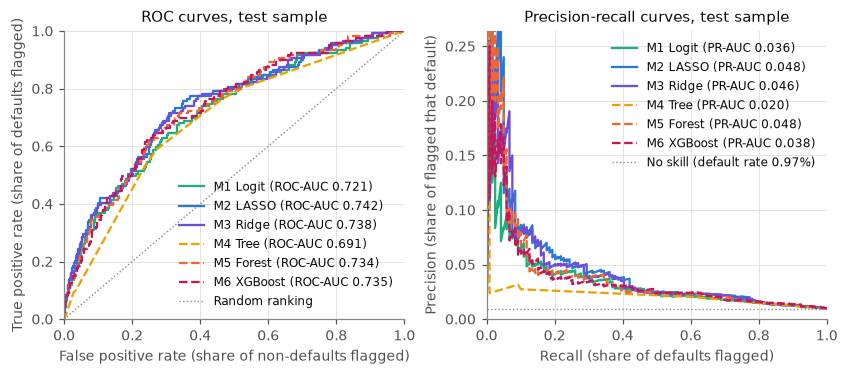

Curves use the frozen models' test probabilities; the legend lists each model's test ROC-AUC or PR-AUC.
Note: the precision-recall panel's vertical axis is cut off at the top, so precision at very low recall (where the curves are noisy) is off the scale.


In [40]:
# ---- ROC and precision-recall curves, test sample ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.3), layout="constrained")
ax = axes[0]
for mk in MODELS:
    fpr, tpr, _ = roc_curve(y_test, TEST_PROB[mk])
    ax.plot(fpr, tpr, color=MODEL_COLORS[mk], ls=MODEL_LINESTYLES[mk], lw=1.5,
            label=f"{MODEL_SHORT[mk]} (ROC-AUC {fmt_num(TEST_M[mk]['roc_auc'], 'f3')})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=0.9, ls=":", label="Random ranking")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.0)
ax.set_xlabel("False positive rate (share of non-defaults flagged)")
ax.set_ylabel("True positive rate (share of defaults flagged)")
ax.set_title("ROC curves, test sample")
ax.legend(loc="lower right", frameon=False)

ax = axes[1]
top_prec = 0.0
for mk in MODELS:
    prec, rec, _ = precision_recall_curve(y_test, TEST_PROB[mk])
    top_prec = max(top_prec, float(prec[rec >= 0.05].max()))
    ax.plot(rec, prec, color=MODEL_COLORS[mk], ls=MODEL_LINESTYLES[mk], lw=1.5,
            label=f"{MODEL_SHORT[mk]} (PR-AUC {fmt_num(TEST_M[mk]['pr_auc'], 'f3')})")
ax.axhline(R["s5"]["test_rate"], color=MUTED, lw=0.9, ls=":",
           label=f"No skill (default rate {fmt_num(R['s5']['test_rate'], 'pct2')})")
ax.set_xlim(0, 1); ax.set_ylim(0, min(1.0, 1.1 * top_prec))
ax.set_xlabel("Recall (share of defaults flagged)")
ax.set_ylabel("Precision (share of flagged that default)")
ax.set_title("Precision-recall curves, test sample")
ax.legend(loc="upper right", frameon=False)
save_fig(fig, "roc_pr_test")
print("Curves use the frozen models' test probabilities; the legend lists each model's test ROC-AUC or PR-AUC.")
print("Note: the precision-recall panel's vertical axis is cut off at the top, so precision at very low recall (where the curves are noisy) is off the scale.")


### Risk deciles

Each table cuts the test firm-years into 10 equal-sized groups by predicted probability, with Decile 1 = highest predicted risk.

In [41]:
# ---- risk-decile tables (test; Decile 1 = highest predicted risk) ----------------------------------------------
DEC_LABEL = {d: str(d) for d in range(1, N_DECILES + 1)}
DEC_LABEL[1], DEC_LABEL[N_DECILES] = "1 (highest risk)", f"{N_DECILES} (lowest risk)"
R["s5"]["deciles"] = {mk: [dict(r) for r in DECILES[mk]] for mk in MODELS}


def decile_frame(mk):
    rows = [{"Decile": DEC_LABEL[r["decile"]], "Firm-years": r["n"], "Firms": r["firms"], "Defaults": r["defaults"],
             "Default rate": r["rate"], "% of all defaults": r["share"], "Cumulative capture": r["cum_capture"],
             "Mean predicted PD": r["mean_pd"]} for r in DECILES[mk]]
    return pd.DataFrame(rows)


DEC_FORMATS = {"Firm-years": "int", "Firms": "int", "Defaults": "int", "Default rate": "pct2",
               "% of all defaults": "pct1", "Cumulative capture": "pct1", "Mean predicted PD": "pct2"}
show(decile_frame(BEST["linear"]), "Test deciles: " + MODEL_NAMES[BEST["linear"]] + " (best linear model by validation ROC-AUC)",
     formats=DEC_FORMATS)
show(decile_frame(BEST["tree"]), "Test deciles: " + MODEL_NAMES[BEST["tree"]] + " (best tree-based model by validation ROC-AUC)",
     formats=DEC_FORMATS)

# ---- check: deciles recomputed directly from the test probabilities ----------------------------------------------
dec_ok = True
for mk in MODELS:
    p = TEST_PROB[mk]
    dec = decile_assign(p)
    sizes = np.bincount(dec, minlength=N_DECILES + 1)[1:]
    defaults = np.bincount(dec, weights=y_test, minlength=N_DECILES + 1)[1:]
    lo_p = np.array([p[dec == d].min() for d in range(1, N_DECILES + 1)])
    hi_p = np.array([p[dec == d].max() for d in range(1, N_DECILES + 1)])
    rows_d = DECILES[mk]
    dec_ok &= bool(sizes.sum() == len(p) and sizes.max() - sizes.min() <= 1)
    dec_ok &= bool(int(defaults.sum()) == int(y_test.sum()))
    dec_ok &= bool(np.all(lo_p[:-1] >= hi_p[1:]))
    dec_ok &= bool(all(r["n"] == s and r["defaults"] == int(k) for r, s, k in zip(rows_d, sizes, defaults)))
    dec_ok &= bool(abs(rows_d[-1]["cum_capture"] - 1.0) <= 1e-12)
    dec_ok &= bool(abs(rows_d[0]["share"] - top_decile_capture(y_test, p)) <= 1e-12)
record_check("deciles_from_predictions", dec_ok,
             "deciles recomputed from the test probabilities have equal sizes (differing by at most one), ordered "
             "probabilities, and defaults that sum to the test total")


Test deciles: Model 3: Ridge logistic (L2) (best linear model by validation ROC-AUC)


Decile,Firm-years,Firms,Defaults,Default rate,% of all defaults,Cumulative capture,Mean predicted PD
1 (highest risk),"1,229",621,46,3.74%,38.7%,38.7%,1.48%
2,"1,228",857,14,1.14%,11.8%,50.4%,0.92%
3,"1,228",926,21,1.71%,17.6%,68.1%,0.72%
4,"1,228",956,11,0.90%,9.2%,77.3%,0.60%
5,"1,228",983,3,0.24%,2.5%,79.8%,0.51%
6,"1,229",973,5,0.41%,4.2%,84.0%,0.43%
7,"1,228",962,8,0.65%,6.7%,90.8%,0.36%
8,"1,228",930,5,0.41%,4.2%,95.0%,0.30%
9,"1,228",857,3,0.24%,2.5%,97.5%,0.24%
10 (lowest risk),"1,228",638,3,0.24%,2.5%,100.0%,0.16%


Test deciles: Model 6: XGBoost (boosted trees) (best tree-based model by validation ROC-AUC)


Decile,Firm-years,Firms,Defaults,Default rate,% of all defaults,Cumulative capture,Mean predicted PD
1 (highest risk),"1,229",697,39,3.17%,32.8%,32.8%,1.49%
2,"1,228",866,20,1.63%,16.8%,49.6%,1.01%
3,"1,228",903,19,1.55%,16.0%,65.5%,0.78%
4,"1,228",951,6,0.49%,5.0%,70.6%,0.60%
5,"1,228",972,12,0.98%,10.1%,80.7%,0.49%
6,"1,229",980,8,0.65%,6.7%,87.4%,0.41%
7,"1,228",965,6,0.49%,5.0%,92.4%,0.34%
8,"1,228",955,4,0.33%,3.4%,95.8%,0.28%
9,"1,228",899,3,0.24%,2.5%,98.3%,0.21%
10 (lowest risk),"1,228",750,2,0.16%,1.7%,100.0%,0.14%


  passed: deciles recomputed from the test probabilities have equal sizes (differing by at most one), ordered probabilities, and defaults that sum to the test total


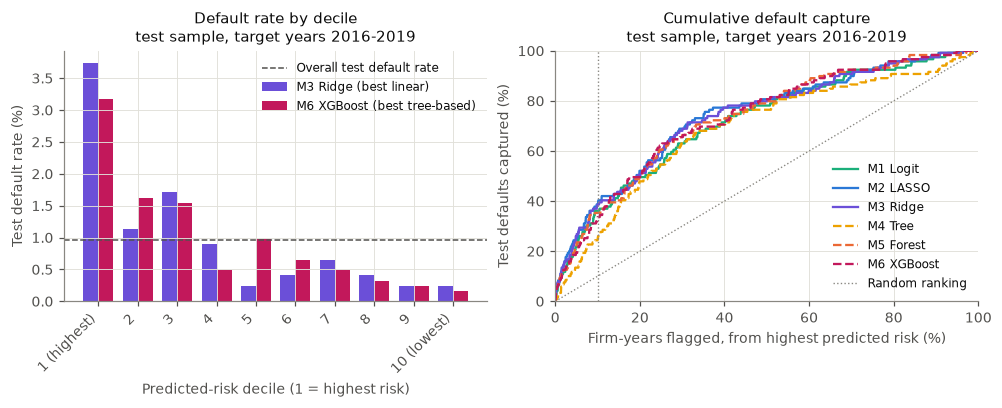

Left: default rate in each predicted-risk decile for the best linear and best tree-based models. Right: cumulative share of defaults captured for all six models; the dotted vertical line marks the top 10% of firm-years.


In [42]:
# ---- decile default rates and cumulative capture, test sample -----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.6), layout="constrained")
ax = axes[0]
x = np.arange(1, N_DECILES + 1)
width = 0.38
for off, mk in ((-width / 2, BEST["linear"]), (width / 2, BEST["tree"])):
    ax.bar(x + off, [r["rate"] * 100 for r in DECILES[mk]], width=width, color=MODEL_COLORS[mk],
           label=MODEL_SHORT[mk] + (" (best linear)" if mk == BEST["linear"] else " (best tree-based)"))
ax.axhline(R["s5"]["test_rate"] * 100, color=INK2, lw=1.0, ls="--", label="Overall test default rate")
ax.set_xticks(x, ["1 (highest)"] + [str(d) for d in range(2, N_DECILES)] + [f"{N_DECILES} (lowest)"], rotation=45, ha="right")
ax.set_xlabel("Predicted-risk decile (1 = highest risk)")
ax.set_ylabel("Test default rate (%)")
ax.set_title("Default rate by decile\ntest sample, target years 2016-2019")
ax.legend(frameon=False, loc="upper right")

ax = axes[1]
for mk in MODELS:
    share, capture = capture_curve(y_test, TEST_PROB[mk])
    ax.plot(np.r_[0.0, share] * 100, np.r_[0.0, capture] * 100, color=MODEL_COLORS[mk], ls=MODEL_LINESTYLES[mk], lw=1.5,
            label=MODEL_SHORT[mk])
ax.plot([0, 100], [0, 100], color=MUTED, lw=0.9, ls=":", label="Random ranking")
ax.axvline(TOP_FRAC * 100, color=MUTED, lw=0.9, ls=":")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("Firm-years flagged, from highest predicted risk (%)")
ax.set_ylabel("Test defaults captured (%)")
ax.set_title("Cumulative default capture\ntest sample, target years 2016-2019")
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "risk_deciles_test")
print("Left: default rate in each predicted-risk decile for the best linear and best tree-based models. "
      "Right: cumulative share of defaults captured for all six models; the dotted vertical line marks the top 10% of firm-years.")



Decile 1 holds the 1,229 test firm-years with the highest predicted risk. The tables and figure show the best linear model by validation ROC-AUC (Model 3: Ridge logistic (L2)) and the best tree-based model (Model 6: XGBoost (boosted trees)); all six models appear in the cumulative-capture panel.

**Best linear model by validation ROC-AUC (M3 Ridge).** Decile 1 has a default rate of 3.74%, 3.86 times the test rate of 0.97%, and holds 46 of the 119 test defaults (38.7%). Cumulative capture is 50.4% after two deciles, 68.1% after three and 77.3% after four. The two lowest-risk deciles each hold 3 defaults (default rate 0.24% in Decile 10).

**Best tree-based model by validation ROC-AUC (M6 XGBoost).** Decile 1 has a default rate of 3.17% (lift 3.28) and 39 defaults (32.8%); cumulative capture is 49.6% after two deciles, 65.5% after three and 70.6% after four. Decile 10 has a default rate of 0.16%.

**Reading the pattern.**

- Both models concentrate defaults at the top: the highest-risk decile's default rate is several times the rate in the lowest deciles and well above the overall 0.97%. The cumulative curves for all six models lie above the diagonal "random ranking" line.
- The pattern is not perfectly monotone, as expected with few defaults: for Ridge, Decile 3 (1.71%) is above Decile 2 (1.14%); for XGBoost, Decile 5 (0.98%) is above Decile 4 (0.49%). Each decile holds only a handful to a few dozen defaults.
- The top-decile capture of Ridge (38.7%) is above that of XGBoost (32.8%), but the difference is +5.9 percentage points [-0.8, +12.2], labelled similar. The two models are similar on top-decile capture, but their decile-by-decile point estimates differ (not resampling-tested; Decile 2: 1.14% for Ridge against 1.63% for XGBoost; Decile 4: 0.90% against 0.49%). The decision tree is lower than Ridge on top-decile capture (Ridge minus tree +14.3 percentage points [+3.8, +22.5]), but that comparison is sensitive to tie handling: the tree's capture of 24.4% depends on the random order within a block of 2,504 firm-years sharing one predicted probability (791 of them fill Decile 1), and its tie-averaged value is 23.6%. Ridge and XGBoost have no such block at the boundary.
- The decile-1 group has 621 distinct firms in 1,229 firm-years for Ridge, so the same firms recur in the high-risk group across the test years. Firm-years in one decile are therefore not independent, and the figures describe this test sample only.


### Evidence for the discussion

The tables below collect the evidence on misclassification, ROC-AUC versus PR-AUC, ranking at a failed 0.50 cutoff, and pairs of models with similar ROC-AUC.

In [43]:
# ---- evidence for the four discussion items --------------------------------------------------------------------------
R["s5"]["misclass_all_nondefault"] = R["s5"]["test_rate"]
rows = []
for mk in MODELS:
    e = TEST_M[mk]
    rows.append({"Model": MODEL_NAMES[mk], "Misclassification at 0.50": e["at_050"]["misclass"],
                 "Flagged at 0.50": e["at_050"]["flagged"], "Recall at 0.50": e["at_050"]["recall"],
                 "Misclassification at frozen threshold": e["misclass"], "Flagged at frozen threshold": e["flagged"],
                 "Top-decile capture": e["top_decile"], "Decile 1 lift": e["decile1_lift"]})
show(pd.DataFrame(rows),
     "(a) Misclassification and ranking. Reference: flagging no firm-year gives a misclassification rate equal to the test default rate, "
     + fmt_num(R["s5"]["misclass_all_nondefault"], "pct2"),
     formats={"Misclassification at 0.50": "pct2", "Flagged at 0.50": "int", "Recall at 0.50": "pct1",
              "Misclassification at frozen threshold": "pct2", "Flagged at frozen threshold": "int",
              "Top-decile capture": "pct1", "Decile 1 lift": "f2"})

rank_of = {metric: {mk: R["s5"]["rank_test"][metric].index(mk) + 1 for mk in MODELS} for metric in ("roc_auc", "pr_auc", "top_decile")}
rows = [{"Model": MODEL_NAMES[mk], "ROC-AUC": TEST_M[mk]["roc_auc"], "ROC-AUC rank": rank_of["roc_auc"][mk],
         "PR-AUC": TEST_M[mk]["pr_auc"], "PR-AUC rank": rank_of["pr_auc"][mk],
         "Top-decile capture": TEST_M[mk]["top_decile"], "Top-decile rank": rank_of["top_decile"][mk],
         "Distinct predicted probabilities": TEST_M[mk]["n_unique_probs"],
         "Max predicted probability": TEST_M[mk]["max_prob"]} for mk in MODELS]
show(pd.DataFrame(rows), "(b) ROC-AUC, PR-AUC and top-decile capture rank orders (1 = highest)",
     formats={"ROC-AUC": "f3", "PR-AUC": "f3", "Top-decile capture": "pct1", "Distinct predicted probabilities": "int",
              "Max predicted probability": "pct2"})
rows = [{"Model": MODEL_NAMES[mk], "Top-decile capture": TEST_M[mk]["top_decile"],
         "Tie-averaged top-decile capture": TEST_M[mk]["top_decile_tie_avg"],
         "Firm-years tied at the decile-1 boundary": TEST_M[mk]["top_decile_tie_block"],
         "Boundary slots filled at random": TEST_M[mk]["top_decile_tie_slots"],
         "Non-defaults per captured default, top decile": TEST_M[mk].get("top_decile_fp_per_tp", np.nan)} for mk in MODELS]
show(pd.DataFrame(rows), "(c) Top-decile capture under ties, and non-defaults per captured default in the top decile",
     formats={"Top-decile capture": "pct1", "Tie-averaged top-decile capture": "pct1",
              "Firm-years tied at the decile-1 boundary": "int", "Boundary slots filled at random": "int",
              "Non-defaults per captured default, top decile": "f2"})
print("Tie-averaged top-decile capture is the expected capture over the random order of the firm-years tied at the Decile 1 boundary; "
      "the fixed random order used for the deciles gives the plain top-decile capture.")
print("Highest test ROC-AUC: " + MODEL_NAMES[R["s5"]["top_roc_model"]] + "; highest test PR-AUC: "
      + MODEL_NAMES[R["s5"]["top_pr_model"]] + "; same model: " + ("yes" if R["s5"]["top_roc_is_top_pr"] else "no") + ".")

R["s5"]["similar_auc_pairs"] = []
for key, comp in R["s5"]["compare_test"].items():
    if comp["roc_auc"]["label"] != "similar":
        continue
    mi, mj = key.split("_vs_")
    gaps = np.abs(np.array([r["rate"] for r in DECILES[mi]]) - np.array([r["rate"] for r in DECILES[mj]]))
    td = comp["top_decile"]
    R["s5"]["similar_auc_pairs"].append({
        "pair": key, "a": mi, "b": mj, "roc_auc_d": comp["roc_auc"]["d"], "top_decile_d": td["d"],
        "top_decile_lo": td["lo"], "top_decile_hi": td["hi"], "top_decile_label": td["label"],
        "max_rate_gap": float(gaps.max()), "max_rate_gap_decile": int(gaps.argmax()) + 1,
        "max_rate_gap_signed": float(DECILES[mi][int(gaps.argmax())]["rate"] - DECILES[mj][int(gaps.argmax())]["rate"])})
R["s5"]["n_similar_auc_pairs"] = len(R["s5"]["similar_auc_pairs"])
R["s5"]["n_similar_auc_diff_decile"] = int(sum(r["top_decile_label"] != "similar" for r in R["s5"]["similar_auc_pairs"]))
if R["s5"]["similar_auc_pairs"]:
    rows = [{"Pair": pair_name(r["pair"]), "ROC-AUC difference": r["roc_auc_d"],
             "Top-decile capture difference [95% interval]": f"{fmt_num(r['top_decile_d'], 'pp1')} "
             f"[{fmt_num(r['top_decile_lo'], 'pp1')}, {fmt_num(r['top_decile_hi'], 'pp1')}]",
             "Label": r["top_decile_label"], "Decile default-rate gap, first minus second model": r["max_rate_gap_signed"],
             "At the decile with the largest absolute gap": DEC_LABEL[r["max_rate_gap_decile"]]} for r in R["s5"]["similar_auc_pairs"]]
    show(pd.DataFrame(rows), "(d) Pairs whose test ROC-AUC difference is labelled similar (the decile default-rate gaps are point estimates, not resampling-tested)",
         formats={"ROC-AUC difference": "sf3", "Decile default-rate gap, first minus second model": "pp1"})
else:
    print("(d) No pair has a test ROC-AUC difference labelled similar.")
print(f"Pairs with similar test ROC-AUC: {R['s5']['n_similar_auc_pairs']}; of these, top-decile capture labelled "
      f"higher or lower: {R['s5']['n_similar_auc_diff_decile']}.")


(a) Misclassification and ranking. Reference: flagging no firm-year gives a misclassification rate equal to the test default rate, 0.97%


Model,Misclassification at 0.50,Flagged at 0.50,Recall at 0.50,Misclassification at frozen threshold,Flagged at frozen threshold,Top-decile capture,Decile 1 lift
Model 1: Logistic regression,0.97%,0,0.0%,2.38%,199,36.1%,3.61
Model 2: LASSO logistic (L1),0.97%,0,0.0%,2.66%,242,38.7%,3.86
Model 3: Ridge logistic (L2),0.97%,0,0.0%,2.36%,203,38.7%,3.86
Model 4: Decision tree,0.97%,0,0.0%,3.62%,348,24.4%,2.44
Model 5: Random forest,0.97%,0,0.0%,2.00%,151,35.3%,3.53
Model 6: XGBoost (boosted trees),0.97%,0,0.0%,2.31%,187,32.8%,3.28


(b) ROC-AUC, PR-AUC and top-decile capture rank orders (1 = highest)


Model,ROC-AUC,ROC-AUC rank,PR-AUC,PR-AUC rank,Top-decile capture,Top-decile rank,Distinct predicted probabilities,Max predicted probability
Model 1: Logistic regression,0.721,5,0.036,5,36.1%,3,"12,282",7.04%
Model 2: LASSO logistic (L1),0.742,1,0.048,1,38.7%,1,"12,282",5.70%
Model 3: Ridge logistic (L2),0.738,2,0.046,3,38.7%,2,"12,282",5.26%
Model 4: Decision tree,0.691,6,0.020,6,24.4%,6,13,7.69%
Model 5: Random forest,0.734,4,0.048,2,35.3%,4,"12,282",2.82%
Model 6: XGBoost (boosted trees),0.735,3,0.038,4,32.8%,5,"12,268",4.84%


(c) Top-decile capture under ties, and non-defaults per captured default in the top decile


Model,Top-decile capture,Tie-averaged top-decile capture,Firm-years tied at the decile-1 boundary,Boundary slots filled at random,"Non-defaults per captured default, top decile"
Model 1: Logistic regression,36.1%,36.1%,1,1,27.58
Model 2: LASSO logistic (L1),38.7%,38.7%,1,1,25.72
Model 3: Ridge logistic (L2),38.7%,38.7%,1,1,25.72
Model 4: Decision tree,24.4%,23.6%,"2,504",791,41.38
Model 5: Random forest,35.3%,35.3%,1,1,28.26
Model 6: XGBoost (boosted trees),32.8%,32.8%,1,1,30.51


Tie-averaged top-decile capture is the expected capture over the random order of the firm-years tied at the Decile 1 boundary; the fixed random order used for the deciles gives the plain top-decile capture.
Highest test ROC-AUC: Model 2: LASSO logistic (L1); highest test PR-AUC: Model 2: LASSO logistic (L1); same model: yes.
(d) Pairs whose test ROC-AUC difference is labelled similar (the decile default-rate gaps are point estimates, not resampling-tested)


Pair,ROC-AUC difference,Top-decile capture difference [95% interval],Label,"Decile default-rate gap, first minus second model",At the decile with the largest absolute gap
M1 Logit vs M4 Tree,+0.030,"+11.8 pp [+1.7 pp, +20.7 pp]",higher,+1.1 pp,1 (highest risk)
M1 Logit vs M5 Forest,-0.014,"+0.8 pp [-6.5 pp, +8.2 pp]",similar,-0.3 pp,3
M1 Logit vs M6 XGBoost,-0.014,"+3.4 pp [-2.9 pp, +10.1 pp]",similar,+0.3 pp,4
M2 LASSO vs M3 Ridge,+0.004,"0.0 pp [-1.9 pp, +4.0 pp]",similar,+0.2 pp,2
M2 LASSO vs M5 Forest,+0.008,"+3.4 pp [-3.9 pp, +12.2 pp]",similar,+0.4 pp,8
M2 LASSO vs M6 XGBoost,+0.008,"+5.9 pp [0.0 pp, +12.8 pp]",similar,-0.7 pp,5
M3 Ridge vs M5 Forest,+0.004,"+3.4 pp [-4.3 pp, +10.4 pp]",similar,-0.4 pp,6
M3 Ridge vs M6 XGBoost,+0.004,"+5.9 pp [-0.8 pp, +12.2 pp]",similar,-0.7 pp,5
M5 Forest vs M6 XGBoost,-0.0004,"+2.5 pp [-5.4 pp, +10.0 pp]",similar,-0.4 pp,5


Pairs with similar test ROC-AUC: 9; of these, top-decile capture labelled higher or lower: 1.



**1. Why the model with the highest ROC-AUC need not have the highest PR-AUC.** On point estimates the same model, Model 2: LASSO logistic (L1), has both the highest test ROC-AUC (0.742) and the highest test PR-AUC (0.048), but its PR-AUC margin over the random forest is negligible (LASSO minus forest +0.0001 [-0.025, +0.030], similar). The orderings differ below the top: the forest is 4th on ROC-AUC (0.734) but 2nd on PR-AUC (0.048), while Ridge is 2nd on ROC-AUC and 3rd on PR-AUC (0.046). These reorderings are within noise (LASSO minus forest: ROC-AUC +0.008 [-0.015, +0.030], similar). The general reason is that ROC-AUC averages over the whole ranking and is dominated by the many non-defaults, while PR-AUC depends on how many non-defaults sit above each default and so mostly reflects the very top of the ranking; with a default rate of 0.97% a few firm-years at the top can reorder PR-AUC without changing ROC-AUC much. The forest and XGBoost values are for one random seed and can move somewhat across seeds, which was not assessed, so the forest's reordering is specific to this seed.

**2. Why a low overall misclassification rate can be misleading.** Flagging no firm-year at all misclassifies exactly the defaults, a rate of 0.97% on test (accuracy of 99.03%). At the 0.50 cutoff every one of the six models flags 0 firm-years, so each has that same misclassification rate and recall of 0.0%. The models whose thresholds actually flag firm-years have a higher misclassification rate, from 2.00% (forest) to 3.62% (tree), yet they are the ones that detect defaults (Ridge: 2.36% misclassification, recall 13.4%). Minimizing the misclassification rate would therefore choose a model that finds nothing.

**3. Why risk ranking can be useful when the 0.50 cutoff fails.** At the 0.50 cutoff every model flags 0 test firm-years: the largest predicted probability on test is 0.070 for Model 1, 0.057 for LASSO, 0.053 for Ridge, 0.077 for the tree, 0.028 for the forest and 0.048 for XGBoost, all far below 0.50. A general reason is that defaults are rare in the training years the models were fitted on (0.72%), so predicted probabilities stay small. The ranking is still informative: Ridge's top decile has a default rate of 3.74% and holds 38.7% of all defaults (lift 3.86), and every model captures more than 10% of defaults in its top decile, from 24.4% (tree; 23.6% averaged over tie orders) to 38.7% (LASSO). A lender can therefore review or price the highest-risk decile (or choose a cut-off from validation, as here), but it pays for it: in Ridge's top decile there are 25.72 non-defaults for every default captured.

**4. Why similar headline AUC values can hide different decile behaviour.** In concept, AUC averages over the whole ranking, whereas deciles weight specific regions (here the top tenth), so two models can have similar averages and different behaviour in one region. In these data, among the 9 model pairs with similar test ROC-AUC, a top-decile capture difference is detected (labelled higher) in 1 pair: Model 1 against the tree (ROC-AUC difference +0.030 [-0.003, +0.062], similar; top-decile difference +11.8 percentage points [+1.7, +20.7], higher). That pair is tie-sensitive: the tree produces only 13 distinct predicted probabilities on test, against 12,282 for Model 1, so a block of 2,504 firm-years shares the probability at the Decile 1 boundary, 791 of them fill Decile 1, and the tree's tie-averaged capture is 23.6% against the reported 24.4%. Its "higher" label is kept as computed under the fixed random tie order, but it should be read with care.

The remaining pairs are labelled similar on top-decile capture; for LASSO against XGBoost the difference is +5.9 percentage points [0.0, +12.8], similar under the resampling rule (the interval only just includes zero). Beyond the top decile, decile default rates were not resampling-tested. Point-estimate gaps exist (the largest among the other pairs is Ridge minus XGBoost -0.7 percentage points at Decile 5), but they are suggestive only: with many possible decile comparisons, some gaps arise by chance. The data therefore neither establish nor rule out different decile behaviour for the other pairs.


## 6. Calibration and Model Interpretation

**Ranking is not calibration.** ROC-AUC, PR-AUC, KS and decile capture only use the order of the predicted probabilities. A model can rank firm-years well and still report probabilities that are too high or too low on average, and probabilities fitted on earlier years can drift when the default rate changes. Credit decisions that use the probability itself (pricing, provisioning, cut-offs) need calibrated probabilities, so this section checks them directly.

### Calibration method

- **Model.** The model with the strongest validation ROC-AUC among the six (the best overall model of Section 5). Its probabilities on the test sample are the *raw* probabilities.
- **Two calibration maps, fitted on validation data only and frozen before the test sample was scored.** *Platt scaling* fits a logistic regression of the validation outcome on the log-odds of the raw probability (two parameters: an intercept and a slope), so it is a strictly increasing map and leaves the ranking unchanged. *Isotonic regression* fits a non-decreasing step function of the raw probability; it needs no functional form but can merge different raw probabilities into the same value, which can change the ranking through ties. Platt scaling on the log-odds was fixed as the primary calibration map before any test result was seen, and it is recorded as the primary map in the frozen choices of the previous section before the test outcomes were unlocked: two parameters suit the small number of defaults in the validation sample, and the map keeps the model's ranking. Isotonic regression is shown only as a comparison. Both maps are fitted on the validation sample and frozen before the test sample is used, and nothing in this section is refitted on test outcomes.
- **Brier score.** The mean of (predicted probability − outcome)² over firm-years; lower is better. The *constant-forecast reference* is the Brier score obtained by giving every test firm-year the same probability, equal to the validation default rate; a model that does not beat it adds nothing over a flat forecast.
- **Reliability plot.** Firm-years are sorted by predicted probability and cut into 10 bins of equal size, numbered from the highest predicted probability (bin 1) to the lowest (separately for each series, using that series' own probabilities, with empty bins dropped). For each bin the plot shows the mean predicted probability against the observed default rate with a 95% Wilson interval; points on the 45-degree line are perfectly calibrated. Equal-width bins are not used because almost every firm-year would fall in the first bin. A second panel compares the observed default rate with the mean predicted probability for each test target year.
- **Comparison with raw.** For Brier score, ROC-AUC, PR-AUC and top-decile capture, whole firms are resampled 2,000 times with replacement (all firm-years of a firm together, the same resamples for all three series), and the middle 95% of the difference (calibrated minus raw) is reported; the label is "higher" or "lower" only if that interval excludes zero, otherwise "similar". For the Brier score, a lower value is better.
- **All six models.** A supplementary table applies each model's own Platt map (fitted on its own validation predictions) to the test sample.

### Interpretation method

- **Linear model.** The best linear model (by validation ROC-AUC among Models 1-3). Continuous predictors are standardized with the training mean and standard deviation, so a coefficient is the change in log-odds of default for a one-training-standard-deviation higher value; the industry dummies are not ranked.
- **Tree ensemble.** The better of the random forest and XGBoost by validation ROC-AUC.
- **Permutation importance (validation sample).** Each of the 22 raw predictor columns is shuffled in turn in the validation sample, using the fitted training pipeline, and the importance is the mean drop in validation ROC-AUC over 10 shuffles (with its standard deviation across shuffles). The industry code is shuffled as one column, so its ten dummies move together. Test outcomes are not used. The same measure is computed for the linear model as a comparison.
- **Native importance.** The ensemble's own importance measure (impurity decrease for a forest, normalized gain for XGBoost), as a share of the total, with the industry dummies summed into one value.
- **Ranks.** Rank 1 is the most important variable; ties share the lowest rank.
- **Reading the results.** Coefficients and importances describe predictive associations in this sample, not causal effects. Strongly correlated predictors share importance and individual coefficients of such predictors are unstable.


In [44]:
# ---- calibration of the strongest validation ranking model: raw, Platt and isotonic probabilities -------------
CAL_MODEL = BEST["overall"]
CAL_SHORT = FINAL[CAL_MODEL]["short"]
CAL_SERIES = ["raw", "platt", "isotonic"]
CAL_LABELS = {"raw": "Raw", "platt": "Platt scaling", "isotonic": "Isotonic regression"}
_platt = FINAL[CAL_MODEL]["platt"]
_val_raw = FINAL[CAL_MODEL]["val_prob"]
CAL_VAL = {"raw": _val_raw, "platt": apply_platt(_platt, _val_raw), "isotonic": ISO.predict(_val_raw).astype(np.float64)}
CAL_TEST = {"raw": TEST_PROB[CAL_MODEL], "platt": TEST_PROB_PLATT[CAL_MODEL], "isotonic": TEST_PROB_ISO}
assert all(len(p) == len(y_test) for p in CAL_TEST.values()) and all(len(p) == len(y_valid) for p in CAL_VAL.values())


def brier(y, p):
    return float(np.mean((np.asarray(p, dtype=float) - np.asarray(y, dtype=float)) ** 2))


s6 = R["s6"]
s6["model"] = CAL_MODEL
s6["platt"] = {"intercept": float(_platt.intercept_[0]), "slope": float(_platt.coef_[0, 0])}
s6["isotonic"] = {"n_steps": int(len(np.unique(ISO.y_thresholds_)))}
s6["rates"] = {"train": float(y_train.mean()), "validation": float(y_valid.mean()), "test": float(y_test.mean())}
s6["test"], s6["val"] = {}, {}
for _s in CAL_SERIES:
    s6["test"][_s] = {**rank_metrics(y_test, CAL_TEST[_s]), "brier": brier(y_test, CAL_TEST[_s]),
                      "mean_pred": float(CAL_TEST[_s].mean())}
    s6["val"][_s] = {"brier": brier(y_valid, CAL_VAL[_s]), "mean_pred": float(CAL_VAL[_s].mean())}
s6["brier_ref_const"] = brier(y_test, np.full(len(y_test), s6["rates"]["validation"]))

print(f"Model calibrated: {FINAL[CAL_MODEL]['name']} (strongest validation ROC-AUC among the six models).")
print(f"Default rate: training {fmt_num(s6['rates']['train'], 'pct2')}, validation {fmt_num(s6['rates']['validation'], 'pct2')}, "
      f"test {fmt_num(s6['rates']['test'], 'pct2')}.")
cal_table = pd.DataFrame({
    "Series": [CAL_LABELS[s] for s in CAL_SERIES],
    "Test Brier score": [s6["test"][s]["brier"] for s in CAL_SERIES],
    "Test ROC-AUC": [s6["test"][s]["roc_auc"] for s in CAL_SERIES],
    "Test PR-AUC": [s6["test"][s]["pr_auc"] for s in CAL_SERIES],
    "Test KS": [s6["test"][s]["ks"] for s in CAL_SERIES],
    "Test top-decile capture (% of defaults)": [s6["test"][s]["top_decile"] for s in CAL_SERIES],
    "Test mean predicted PD (%)": [s6["test"][s]["mean_pred"] for s in CAL_SERIES],
    "Test observed default rate (%)": [s6["rates"]["test"]] * 3,
    "Validation Brier score": [s6["val"][s]["brier"] for s in CAL_SERIES],
    "Validation mean predicted PD (%)": [s6["val"][s]["mean_pred"] for s in CAL_SERIES],
})
show(cal_table, f"Calibration of {CAL_SHORT}: test sample (maps fitted on validation only; validation columns are in-sample for the maps)",
     formats={"Test Brier score": "f5", "Test ROC-AUC": "f3", "Test PR-AUC": "f3", "Test KS": "f3",
              "Test top-decile capture (% of defaults)": "pct1", "Test mean predicted PD (%)": "pct2",
              "Test observed default rate (%)": "pct2", "Validation Brier score": "f5",
              "Validation mean predicted PD (%)": "pct2"}, index_col="Series")
print(f"Reference Brier score of a constant forecast equal to the validation default rate, on the test sample: "
      f"{fmt_num(s6['brier_ref_const'], 'f5')}.")
print(f"Platt map (validation fit): intercept {fmt_num(s6['platt']['intercept'], 'f3')}, slope {fmt_num(s6['platt']['slope'], 'f3')} "
      f"on the log-odds scale; isotonic map has {s6['isotonic']['n_steps']:,} distinct fitted values.")

# ---- firm-cluster paired bootstrap on the test sample: calibrated minus raw ----------------------------------------
boot = paired_bootstrap(y_test, CAL_TEST, g_test)
CAL_METRICS = {"brier": ("Brier score", "f5", "sf5"), "roc_auc": ("ROC-AUC", "f3", "sf3"),
               "pr_auc": ("PR-AUC", "f3", "sf3"), "top_decile": ("Top-decile capture", "pct1", "pp1")}
s6["compare"] = {}
rows = []
for _s in ["platt", "isotonic"]:
    s6["compare"][f"{_s}_vs_raw"] = {}
    for _m, (_name, _vs, _ds) in CAL_METRICS.items():
        _ps = pair_summary(s6["test"][_s][_m], s6["test"]["raw"][_m], boot[_s][_m], boot["raw"][_m])
        s6["compare"][f"{_s}_vs_raw"][_m] = _ps
        rows.append({"Comparison": f"{CAL_LABELS[_s]} minus raw", "Metric": _name,
                     "Calibrated": fmt_num(_ps["a"], _vs), "Raw": fmt_num(_ps["b"], _vs),
                     "Difference [95% interval]": f"{fmt_num(_ps['d'], _ds)} [{fmt_num(_ps['lo'], _ds)}, {fmt_num(_ps['hi'], _ds)}]",
                     "Label": _ps["label"]})
show(pd.DataFrame(rows), f"Test sample: calibrated minus raw, firm-cluster bootstrap ({N_BOOT:,} resamples; "
     "for the Brier score a negative difference means lower error)")


Model calibrated: Model 3: Ridge logistic (L2) (strongest validation ROC-AUC among the six models).
Default rate: training 0.72%, validation 0.83%, test 0.97%.
Calibration of M3 Ridge: test sample (maps fitted on validation only; validation columns are in-sample for the maps)


Series,Test Brier score,Test ROC-AUC,Test PR-AUC,Test KS,Test top-decile capture (% of defaults),Test mean predicted PD (%),Test observed default rate (%),Validation Brier score,Validation mean predicted PD (%)
Raw,0.00954,0.738,0.046,0.405,38.7%,0.57%,0.97%,0.00821,0.52%
Platt scaling,0.00948,0.738,0.046,0.405,38.7%,0.93%,0.97%,0.00818,0.83%
Isotonic regression,0.00947,0.741,0.032,0.388,37.8%,0.95%,0.97%,0.00815,0.83%


Reference Brier score of a constant forecast equal to the validation default rate, on the test sample: 0.00960.
Platt map (validation fit): intercept 1.547, slope 1.215 on the log-odds scale; isotonic map has 12 distinct fitted values.
Test sample: calibrated minus raw, firm-cluster bootstrap (2,000 resamples; for the Brier score a negative difference means lower error)


Comparison,Metric,Calibrated,Raw,Difference [95% interval],Label
Platt scaling minus raw,Brier score,0.00948,0.00954,"-0.00006 [-0.00010, -0.00002]",lower
Platt scaling minus raw,ROC-AUC,0.738,0.738,"0.000 [0.000, 0.000]",similar
Platt scaling minus raw,PR-AUC,0.046,0.046,"0.000 [0.000, 0.000]",similar
Platt scaling minus raw,Top-decile capture,38.7%,38.7%,"0.0 pp [0.0 pp, 0.0 pp]",similar
Isotonic regression minus raw,Brier score,0.00947,0.00954,"-0.00006 [-0.00014, +0.000003]",similar
Isotonic regression minus raw,ROC-AUC,0.741,0.738,"+0.003 [-0.005, +0.011]",similar
Isotonic regression minus raw,PR-AUC,0.032,0.046,"-0.014 [-0.045, -0.004]",lower
Isotonic regression minus raw,Top-decile capture,37.8%,38.7%,"-0.8 pp [-4.5 pp, +2.8 pp]",similar


Reliability bins, test sample (quantile bins of each series; 95% Wilson interval for the observed rate)


Series,Bin,Firm-years,Defaults,Mean predicted PD (%),Observed default rate (%),Interval low (%),Interval high (%)
Raw,1,"1,229",46,1.48%,3.74%,2.82%,4.96%
Raw,2,"1,228",14,0.92%,1.14%,0.68%,1.90%
Raw,3,"1,228",21,0.72%,1.71%,1.12%,2.60%
Raw,4,"1,228",11,0.60%,0.90%,0.50%,1.60%
Raw,5,"1,228",3,0.51%,0.24%,0.08%,0.72%
Raw,6,"1,228",5,0.43%,0.41%,0.17%,0.95%
Raw,7,"1,228",8,0.36%,0.65%,0.33%,1.28%
Raw,8,"1,228",5,0.30%,0.41%,0.17%,0.95%
Raw,9,"1,228",3,0.24%,0.24%,0.08%,0.72%
Raw,10,"1,229",3,0.16%,0.24%,0.08%,0.72%


Observed default rate and mean predicted PD by test target year


Test target year,Firm-years,Defaults,Observed default rate (%),"Mean PD, Raw (%)","Mean PD, Platt scaling (%)","Mean PD, Isotonic regression (%)"
2016,"3,354",33,0.98%,0.62%,1.03%,1.07%
2017,"3,191",29,0.91%,0.55%,0.89%,0.90%
2018,"3,014",21,0.70%,0.50%,0.79%,0.78%
2019,"2,723",36,1.32%,0.61%,1.00%,1.03%


Default rate, mean raw prediction and predictor means by sample (the training predictions are in-sample; descriptive only)


Sample,Firm-years,Defaults,Default rate,Mean raw predicted PD,Mean Debt / assets (ratio),Mean Net income / assets (ratio),Mean Current ratio (ratio),Mean Log market value (log $ millions),Mean Annual return (decimal return),Mean Return volatility (decimal volatility)
Training,"55,927",403,0.72%,0.72%,0.411,0.067,0.927,9.263,-0.086,0.287
Validation,"10,473",87,0.83%,0.52%,0.393,0.084,0.981,9.661,0.132,0.236
Test,"12,282",119,0.97%,0.57%,0.394,0.082,0.973,9.721,-0.012,0.246


Decomposition of the calibration gap, in percentage points of probability (the three parts add up to the total; the training part uses in-sample predictions; descriptive only)


Sample,Total gap (default rate minus mean prediction),Part from the default-rate difference vs training,Part from the lower mean prediction vs training,Part already present in training (in-sample)
Validation,0.31%,0.11%,0.20%,0.00%
Test,0.40%,0.25%,0.15%,0.00%


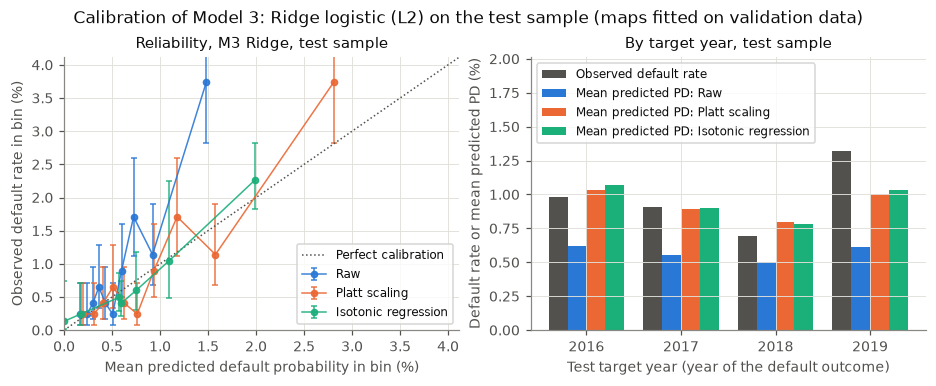

Note: the reliability panel's axes stop just beyond the largest plotted point, so interval bars that extend past that limit are cut off at the edge.


In [45]:
# ---- reliability bins and calibration figure -------------------------------------------------------------------------------
# bins are numbered from the highest predicted probability (bin 1), matching the decile convention; the plot is unaffected
s6["bins"] = {_s: [{**_r, "bin": _i + 1} for _i, _r in enumerate(reversed(reliability_bins(y_test, CAL_TEST[_s])))]
              for _s in CAL_SERIES}
bin_rows = []
for _s in CAL_SERIES:
    for _b in s6["bins"][_s]:
        bin_rows.append({"Series": CAL_LABELS[_s], "Bin": _b["bin"], "Firm-years": _b["n"], "Defaults": _b["defaults"],
                         "Mean predicted PD (%)": _b["mean_pred"], "Observed default rate (%)": _b["obs_rate"],
                         "Interval low (%)": _b["lo"], "Interval high (%)": _b["hi"]})
show(pd.DataFrame(bin_rows), "Reliability bins, test sample (quantile bins of each series; 95% Wilson interval for the observed rate)",
     formats={"Bin": "int", "Firm-years": "int", "Defaults": "int", "Mean predicted PD (%)": "pct2",
              "Observed default rate (%)": "pct2", "Interval low (%)": "pct2", "Interval high (%)": "pct2"})

CAL_YEARS = sorted(int(t) for t in np.unique(ty_test))
s6["by_year"] = {}
for _t in CAL_YEARS:
    _m = ty_test == _t
    s6["by_year"][str(_t)] = {"n": int(_m.sum()), "defaults": int(y_test[_m].sum()), "rate": float(y_test[_m].mean()),
                              **{_s: float(CAL_TEST[_s][_m].mean()) for _s in CAL_SERIES}}
year_table = pd.DataFrame([{"Test target year": str(_t), "Firm-years": s6["by_year"][str(_t)]["n"],
                            "Defaults": s6["by_year"][str(_t)]["defaults"],
                            "Observed default rate (%)": s6["by_year"][str(_t)]["rate"],
                            **{f"Mean PD, {CAL_LABELS[_s]} (%)": s6["by_year"][str(_t)][_s] for _s in CAL_SERIES}}
                           for _t in CAL_YEARS])
show(year_table, "Observed default rate and mean predicted PD by test target year",
     formats={"Firm-years": "int", "Defaults": "int", "Observed default rate (%)": "pct2",
              **{f"Mean PD, {CAL_LABELS[_s]} (%)": "pct2" for _s in CAL_SERIES}})

# ---- calibration gap by sample: default rate versus mean raw prediction, and its decomposition (descriptive) ----------
_raw_pipe = FINAL[CAL_MODEL]["pipe"]
_samples = {"train": (X_train, y_train, predict(_raw_pipe, X_train)), "validation": (X_valid, y_valid, CAL_VAL["raw"]),
            "test": (X_test, y_test, CAL_TEST["raw"])}
s6["by_sample"] = {_k: {"n": int(len(_y)), "defaults": int(_y.sum()), "rate": float(_y.mean()), "mean_pred_raw": float(_p.mean()),
                        "means": {_v: float(_X[_v].to_numpy(dtype=float).mean()) for _v in PROFILE_VARS}}
                   for _k, (_X, _y, _p) in _samples.items()}
_tr = s6["by_sample"]["train"]
s6["gap_decomp"] = {}
for _k in ("validation", "test"):
    _s = s6["by_sample"][_k]
    s6["gap_decomp"][_k] = {"total": _s["rate"] - _s["mean_pred_raw"], "base_rate_part": _s["rate"] - _tr["rate"],
                            "pred_shift_part": _tr["mean_pred_raw"] - _s["mean_pred_raw"],
                            "train_fit_part": _tr["rate"] - _tr["mean_pred_raw"]}
    _g = s6["gap_decomp"][_k]
    assert abs(_g["base_rate_part"] + _g["pred_shift_part"] + _g["train_fit_part"] - _g["total"]) <= 1e-12
_sample_names = {"train": "Training", "validation": "Validation", "test": "Test"}
show(pd.DataFrame([{"Sample": _sample_names[_k], "Firm-years": _v["n"], "Defaults": _v["defaults"], "Default rate": _v["rate"],
                    "Mean raw predicted PD": _v["mean_pred_raw"], **{f"Mean {var_label(_x)}": _v["means"][_x] for _x in PROFILE_VARS}}
                   for _k, _v in s6["by_sample"].items()]),
     "Default rate, mean raw prediction and predictor means by sample (the training predictions are in-sample; descriptive only)",
     formats={"Firm-years": "int", "Defaults": "int", "Default rate": "pct2", "Mean raw predicted PD": "pct2",
              **{f"Mean {var_label(_x)}": "f3" for _x in PROFILE_VARS}})
show(pd.DataFrame([{"Sample": _sample_names[_k], "Total gap (default rate minus mean prediction)": _g["total"],
                    "Part from the default-rate difference vs training": _g["base_rate_part"],
                    "Part from the lower mean prediction vs training": _g["pred_shift_part"],
                    "Part already present in training (in-sample)": _g["train_fit_part"]}
                   for _k, _g in s6["gap_decomp"].items()]),
     "Decomposition of the calibration gap, in percentage points of probability (the three parts add up to the total; "
     "the training part uses in-sample predictions; descriptive only)",
     formats={_c: "pct2" for _c in ("Total gap (default rate minus mean prediction)", "Part from the default-rate difference vs training",
                                    "Part from the lower mean prediction vs training", "Part already present in training (in-sample)")})

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4), layout="constrained")
ax = axes[0]
_top, _hi_all = 0.0, 0.0
for _s in CAL_SERIES:
    _b = s6["bins"][_s]
    _x = np.array([r["mean_pred"] for r in _b]) * 100
    _y = np.array([r["obs_rate"] for r in _b]) * 100
    _lo = np.array([r["lo"] for r in _b]) * 100
    _hi = np.array([r["hi"] for r in _b]) * 100
    ax.errorbar(_x, _y, yerr=[np.maximum(_y - _lo, 0.0), np.maximum(_hi - _y, 0.0)], fmt="o-", ms=4, lw=1.0, capsize=2,
                color=CAL_COLORS[_s], label=CAL_LABELS[_s], alpha=0.9)
    _top = max(_top, _x.max(), _y.max())
    _hi_all = max(_hi_all, _hi.max())
_top *= 1.1
ax.plot([0, _top], [0, _top], color=INK2, ls=":", lw=1.0, label="Perfect calibration")
ax.set_xlim(0, _top)
ax.set_ylim(0, _top)
ax.set_xlabel("Mean predicted default probability in bin (%)")
ax.set_ylabel("Observed default rate in bin (%)")
ax.set_title(f"Reliability, {CAL_SHORT}, test sample")
ax.legend(loc="lower right")

ax = axes[1]
_series = ["observed"] + CAL_SERIES
_colors = {"observed": INK2, **CAL_COLORS}
_names = {"observed": "Observed default rate", **{s: f"Mean predicted PD: {CAL_LABELS[s]}" for s in CAL_SERIES}}
_w = 0.2
for _i, _s in enumerate(_series):
    _vals = [s6["by_year"][str(t)]["rate" if _s == "observed" else _s] * 100 for t in CAL_YEARS]
    ax.bar(np.arange(len(CAL_YEARS)) + (_i - 1.5) * _w, _vals, width=_w, color=_colors[_s], label=_names[_s])
ax.set_xticks(np.arange(len(CAL_YEARS)), [str(t) for t in CAL_YEARS])
ax.set_xlabel("Test target year (year of the default outcome)")
ax.set_ylabel("Default rate or mean predicted PD (%)")
ax.set_title("By target year, test sample")
ax.set_ylim(0, ax.get_ylim()[1] * 1.45)
ax.legend(loc="upper left")
fig.suptitle(f"Calibration of {FINAL[CAL_MODEL]['name']} on the test sample (maps fitted on validation data)")
save_fig(fig, "calibration_test")
if _hi_all > _top:
    print("Note: the reliability panel's axes stop just beyond the largest plotted point, so interval bars that extend past that limit are cut off at the edge.")


In [46]:
# ---- supplementary: Platt scaling for all six models (each map fitted on that model's validation predictions) -----------
s6["platt_all"] = {}
for _m in MODELS:
    _pl = FINAL[_m]["platt"]
    s6["platt_all"][_m] = {"brier_raw": brier(y_test, TEST_PROB[_m]), "brier_platt": brier(y_test, TEST_PROB_PLATT[_m]),
                           "mean_raw": float(TEST_PROB[_m].mean()), "mean_platt": float(TEST_PROB_PLATT[_m].mean()),
                           "intercept": float(_pl.intercept_[0]), "slope": float(_pl.coef_[0, 0])}
platt_all = pd.DataFrame({
    "Model": [MODEL_NAMES[_m] for _m in MODELS],
    "Brier score, raw": [s6["platt_all"][_m]["brier_raw"] for _m in MODELS],
    "Brier score, Platt": [s6["platt_all"][_m]["brier_platt"] for _m in MODELS],
    "Mean predicted PD, raw (%)": [s6["platt_all"][_m]["mean_raw"] for _m in MODELS],
    "Mean predicted PD, Platt (%)": [s6["platt_all"][_m]["mean_platt"] for _m in MODELS],
    "Platt intercept": [s6["platt_all"][_m]["intercept"] for _m in MODELS],
    "Platt slope": [s6["platt_all"][_m]["slope"] for _m in MODELS],
})
show(platt_all, f"Test sample, all six models: raw vs Platt-scaled probabilities (observed default rate {fmt_num(s6['rates']['test'], 'pct2')}; "
     f"constant-forecast Brier score {fmt_num(s6['brier_ref_const'], 'f5')})",
     formats={"Brier score, raw": "f5", "Brier score, Platt": "f5", "Mean predicted PD, raw (%)": "pct2",
              "Mean predicted PD, Platt (%)": "pct2", "Platt intercept": "f3", "Platt slope": "f3"}, index_col="Model")


Test sample, all six models: raw vs Platt-scaled probabilities (observed default rate 0.97%; constant-forecast Brier score 0.00960)


Model,"Brier score, raw","Brier score, Platt","Mean predicted PD, raw (%)","Mean predicted PD, Platt (%)",Platt intercept,Platt slope
Model 1: Logistic regression,0.00954,0.00950,0.57%,0.93%,0.775,1.055
Model 2: LASSO logistic (L1),0.00953,0.00947,0.58%,0.94%,1.402,1.186
Model 3: Ridge logistic (L2),0.00954,0.00948,0.57%,0.93%,1.547,1.215
Model 4: Decision tree,0.00957,0.00955,0.58%,0.84%,-1.067,0.711
Model 5: Random forest,0.00955,0.00951,0.59%,0.86%,0.460,1.015
Model 6: XGBoost (boosted trees),0.00955,0.00951,0.58%,0.92%,0.454,0.996



The model calibrated is Model 3: Ridge logistic (L2), the strongest by validation ROC-AUC. Comparison rule: a calibrated series is called higher or lower than raw only if the 95% firm-resampling interval of the difference excludes zero; otherwise similar.

**Raw probabilities.** Test Brier score 0.00954, against 0.00960 for a constant forecast equal to the validation default rate: the model is only just below the flat forecast, which is typical when the event rate is near 1% because the Brier score is then dominated by non-events. The raw probabilities are too low on average: mean predicted probability 0.57% against 0.97% observed on test (validation: 0.52% against 0.83%). In the reliability plot, the raw curve lies above the 45-degree line at the high end: in the highest-risk bin the mean predicted probability is 1.48% but the observed rate is 3.74% (interval 2.82% to 4.96%), and in the third-highest-risk bin 0.72% against 1.71%. Lower bins are close to the line but have few defaults each.

**Platt scaling (fitted on validation).** Intercept 1.547 and slope 1.215 on the log-odds scale. Mean predicted probability on test moves to 0.93% against 0.97% observed, and the highest-risk bin to 2.81% against 3.74% observed, closer but still below. The Brier score falls to 0.00948 (Platt minus raw -0.00006 [-0.00010, -0.00002], lower): a lower probability error, but a small one in absolute terms. Ranking is unchanged by construction, since Platt scaling is a strictly increasing map: ROC-AUC 0.738, PR-AUC 0.046, KS 0.405 and top-decile capture 38.7% equal the raw values.

**Isotonic regression (fitted on validation).** The Brier score is 0.00947 (isotonic minus raw -0.00006 [-0.00014, +0.000003], similar under the resampling rule, with the interval only just including zero). Its step map has only 12 distinct output values, so many firm-years share the same calibrated value and the ranking can change: ROC-AUC 0.741 is similar to raw (+0.003 [-0.005, +0.011]) and top-decile capture is similar, but PR-AUC falls to 0.032 (raw 0.046; difference -0.014 [-0.045, -0.004], lower). The reliability plot shows only 7 isotonic bins, of unequal size, for the same reason.

**Does calibration help, and does it change ranking?** Platt scaling brings predicted probabilities closer to the observed level and lowers the Brier score slightly, at no cost to ranking. The test comparison is consistent with the pre-specified choice of Platt as the primary map (fixed on validation before any test result): isotonic is similar to raw on Brier and lower on PR-AUC, while Platt lowers Brier and leaves the ranking unchanged. Calibration on its own does not make the model sharp: the Brier score stays close to the constant-forecast value (0.00960). The same Platt pattern holds for all six models (test Brier raw to Platt: Model 1 0.00954 to 0.00950, LASSO 0.00953 to 0.00947, Ridge 0.00954 to 0.00948, tree 0.00957 to 0.00955, forest 0.00955 to 0.00951, XGBoost 0.00955 to 0.00951); these differences are not labelled.

**Base-rate drift and the shortfall.** Default rates (point estimates) rise across the samples: 0.72% training, 0.83% validation and 0.97% test. The raw probabilities fall short of the observed rate for two reasons. On test the mean prediction is 0.57% against 0.97% observed, a gap of 0.40 percentage points: 0.25 points reflect a higher default rate than in training and 0.15 points a lower mean prediction for later firm-years (the model predicts 0.72% on its own training sample, matching the training rate). On validation the gap of 0.31 points splits into 0.11 and 0.20. Later firm-years look safer on several predictors: Annual return averages -0.086 in training, 0.132 in validation and -0.012 in test, Return volatility 0.287, 0.236 and 0.246, and Log market value 9.263, 9.661 and 9.721. A possible reason, not tested here, is that these safer-looking predictors lowered the predictions while default rates rose. The Platt map corrects more than the level: its slope of 1.215 (above 1) stretches the spread of predictions as well as shifting them up.

By test target year the observed rate is 0.98%, 0.91%, 0.70% and 1.32% for 2016 to 2019, while the raw mean predicted probability is 0.62%, 0.55%, 0.50% and 0.61%, below the observed rate in every year. Platt-scaled means (1.03%, 0.89%, 0.79% and 1.00%) are close to the observed rate in 2016 and 2017, above it in 2018 and below it in 2019 (1.32% observed): they match the average level but move less than the observed rate. Probabilities fitted on training years need recalibration when the base rate moves. With four test years, this is a pattern to monitor, not an established trend.


### Interpretation of one linear model and one tree ensemble

In [47]:
# ---- interpretation: standardized coefficients, permutation importance (validation) and native importance ---------------
LIN_KEY, ENS_KEY = BEST["linear"], BEST["ensemble"]
lin_pipe, ens_pipe = FINAL[LIN_KEY]["pipe"], FINAL[ENS_KEY]["pipe"]


def _feature_series(pipe, values):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return pd.Series(np.asarray(values, dtype=float), index=[str(n) for n in names])


# standardized coefficients of the linear model (continuous predictors only)
coef = _feature_series(lin_pipe, lin_pipe.named_steps["clf"].coef_[0]).reindex(FEATURES)

# permutation importance on the validation sample, raw 22 columns so the industry dummies move together
perm_ens = permutation_importance(ens_pipe, X_valid, y_valid, scoring="roc_auc", n_repeats=PERM_REPEATS,
                                  random_state=SEED, n_jobs=1)
perm_lin = permutation_importance(lin_pipe, X_valid, y_valid, scoring="roc_auc", n_repeats=PERM_REPEATS,
                                  random_state=SEED, n_jobs=1)
assert list(X_valid.columns) == FEATURES

# native importance of the ensemble, industry dummies summed
native = _feature_series(ens_pipe, ens_pipe.named_steps["clf"].feature_importances_)
native.index = ["industry_code" if n.startswith("industry_code") else n for n in native.index]
native = native.groupby(level=0, sort=False).sum().reindex(FEATURES)
native = native / native.sum()

IMPORTANCE = pd.DataFrame(index=pd.Index(FEATURES), dtype=float)
IMPORTANCE["linear_coef"] = coef
IMPORTANCE["linear_rank"] = coef.abs().rank(ascending=False, method="min")
IMPORTANCE["perm_ens_mean"] = perm_ens.importances_mean
IMPORTANCE["perm_ens_sd"] = perm_ens.importances_std
IMPORTANCE["perm_ens_rank"] = IMPORTANCE["perm_ens_mean"].rank(ascending=False, method="min")
IMPORTANCE["native_ens"] = native
IMPORTANCE["native_rank"] = native.rank(ascending=False, method="min")
IMPORTANCE["perm_lin_mean"] = perm_lin.importances_mean
IMPORTANCE["perm_lin_sd"] = perm_lin.importances_std
IMPORTANCE["perm_lin_rank"] = IMPORTANCE["perm_lin_mean"].rank(ascending=False, method="min")
assert IMPORTANCE.shape == (len(FEATURES), 10)

imp = s6.setdefault("importance", {})
imp.update({"linear_model": LIN_KEY, "ensemble_model": ENS_KEY, "scoring": "roc_auc", "n_repeats": int(PERM_REPEATS), "vars": {}})
for _v in FEATURES:
    _row = IMPORTANCE.loc[_v]
    imp["vars"][_v] = {k: (int(_row[k]) if k.endswith("_rank") else float(_row[k]))
                       for k in IMPORTANCE.columns if np.isfinite(_row[k])}


def _top_by(rank_col, k=5):
    return [str(v) for v in IMPORTANCE.sort_values(rank_col, kind="stable").index[:k] if np.isfinite(IMPORTANCE.loc[v, rank_col])]


imp["top5"] = {"linear": _top_by("linear_rank"), "perm_ens": _top_by("perm_ens_rank"),
               "native": _top_by("native_rank"), "perm_lin": _top_by("perm_lin_rank")}
imp["top5_overlap_linear_perm_ens"] = int(len(set(imp["top5"]["linear"]) & set(imp["top5"]["perm_ens"])))
imp["rank_corr_perm_lin_perm_ens"] = spearman(IMPORTANCE["perm_lin_mean"], IMPORTANCE["perm_ens_mean"])

print(f"Linear model interpreted: {FINAL[LIN_KEY]['name']}; tree ensemble interpreted: {FINAL[ENS_KEY]['name']}.")
print(f"Permutation importance: validation sample, {PERM_REPEATS} shuffles per predictor, scoring by ROC-AUC; "
      f"the industry code is shuffled as one column.")
imp_table = IMPORTANCE.sort_values("perm_ens_rank", kind="stable").reset_index(names="v")
imp_table = pd.DataFrame({
    "Predictor": [var_label(v, unit=False) for v in imp_table["v"]],
    "Group": [GROUP_NAMES.get(VAR_GROUPS.get(v, ""), "Industry") for v in imp_table["v"]],
    "Linear standardized coefficient": imp_table["linear_coef"],
    "Linear rank (|coefficient|)": imp_table["linear_rank"],
    "Ensemble permutation drop in ROC-AUC": imp_table["perm_ens_mean"],
    "Ensemble permutation SD": imp_table["perm_ens_sd"],
    "Ensemble permutation rank": imp_table["perm_ens_rank"],
    "Ensemble native share": imp_table["native_ens"],
    "Ensemble native rank": imp_table["native_rank"],
    "Linear permutation drop in ROC-AUC": imp_table["perm_lin_mean"],
    "Linear permutation SD": imp_table["perm_lin_sd"],
    "Linear permutation rank": imp_table["perm_lin_rank"],
})
show(imp_table, "Predictor importance for the best linear model and the best tree ensemble (ordered by ensemble permutation rank; "
     "coefficient = log-odds change per one training standard deviation)",
     formats={"Linear standardized coefficient": "f3", "Linear rank (|coefficient|)": "int",
              "Ensemble permutation drop in ROC-AUC": "f4", "Ensemble permutation SD": "f4",
              "Ensemble permutation rank": "int", "Ensemble native share": "f3", "Ensemble native rank": "int",
              "Linear permutation drop in ROC-AUC": "f4", "Linear permutation SD": "f4", "Linear permutation rank": "int"},
     index_col="Predictor")
print(f"Spearman correlation between linear and ensemble permutation importance over {len(FEATURES)} predictors: "
      f"{fmt_num(imp['rank_corr_perm_lin_perm_ens'], 'f2')}; overlap of the five most important predictors "
      f"(linear coefficients vs ensemble permutation): {imp['top5_overlap_linear_perm_ens']} of 5.")


Linear model interpreted: Model 3: Ridge logistic (L2); tree ensemble interpreted: Model 6: XGBoost (boosted trees).
Permutation importance: validation sample, 10 shuffles per predictor, scoring by ROC-AUC; the industry code is shuffled as one column.
Predictor importance for the best linear model and the best tree ensemble (ordered by ensemble permutation rank; coefficient = log-odds change per one training standard deviation)


Predictor,Group,Linear standardized coefficient,Linear rank (|coefficient|),Ensemble permutation drop in ROC-AUC,Ensemble permutation SD,Ensemble permutation rank,Ensemble native share,Ensemble native rank,Linear permutation drop in ROC-AUC,Linear permutation SD,Linear permutation rank
Annual return,Market information,-0.176,1,0.0211,0.0060,1,0.041,8,0.0206,0.0037,1
Current liabilities / assets,Leverage / capital structure,0.084,7,0.0132,0.0070,2,0.134,1,-0.0016,0.0028,21
Log market value,Market information,-0.066,8,0.0122,0.0055,3,0.026,14,0.0095,0.0030,2
Long-term debt / assets,Leverage / capital structure,0.132,4,0.0077,0.0053,4,0.044,7,0.0002,0.0047,15
Quick ratio,Liquidity,-0.058,11,0.0052,0.0029,5,0.029,11,0.0035,0.0026,4
Retained earnings / assets,Profitability,-0.112,5,0.0033,0.0042,6,0.039,9,0.0023,0.0049,7
EBITDA / assets,Profitability,-0.036,15,0.0030,0.0013,7,0.056,5,0.0028,0.0012,5
Equity / assets,Leverage / capital structure,-0.133,3,0.0029,0.0035,8,0.110,3,0.0021,0.0058,9
Operating expense / sales,Operating efficiency,0.044,13,0.0026,0.0015,9,0.032,10,0.0024,0.0009,6
Inventory / sales,Operating efficiency,0.055,12,0.0022,0.0013,10,0.025,17,0.0007,0.0013,13


Spearman correlation between linear and ensemble permutation importance over 22 predictors: 0.56; overlap of the five most important predictors (linear coefficients vs ensemble permutation): 2 of 5.


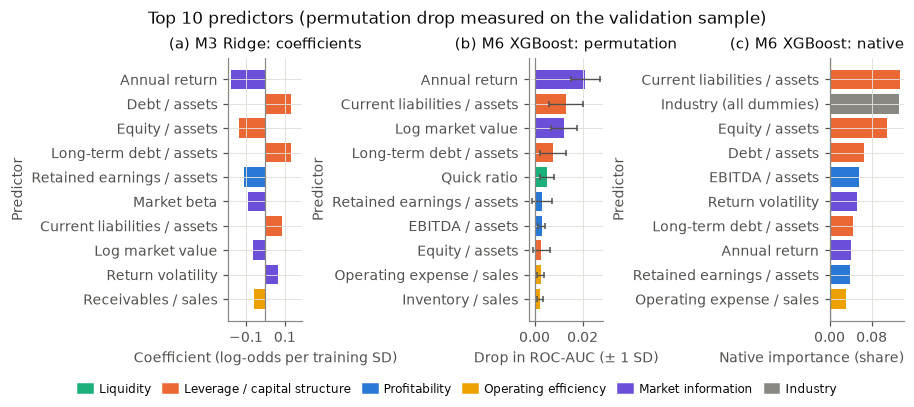

In [48]:
# ---- Figure: top predictors of the linear model and the tree ensemble -------------------------------------------------
def _group_of(v):
    return VAR_GROUPS.get(v, "industry")


def _top_rows(rank_col, k=N_TOP):
    idx = IMPORTANCE.sort_values(rank_col, kind="stable").index
    return [v for v in idx if np.isfinite(IMPORTANCE.loc[v, rank_col])][:k]


from matplotlib.ticker import MaxNLocator
fig, axes = plt.subplots(1, 3, figsize=(8.2, 3.6), layout="constrained")
panels = [
    ("linear_rank", "linear_coef", None, "Coefficient (log-odds per training SD)",
     f"(a) {FINAL[LIN_KEY]['short']}: coefficients"),
    ("perm_ens_rank", "perm_ens_mean", "perm_ens_sd", "Drop in ROC-AUC (± 1 SD)",
     f"(b) {FINAL[ENS_KEY]['short']}: permutation"),
    ("native_rank", "native_ens", None, "Native importance (share)",
     f"(c) {FINAL[ENS_KEY]['short']}: native"),
]
used_groups = []
for ax, (rank_col, val_col, sd_col, xlabel, title) in zip(axes, panels):
    vs = _top_rows(rank_col)
    vals = IMPORTANCE.loc[vs, val_col].to_numpy()
    cols = [GROUP_COLORS[_group_of(v)] for v in vs]
    used_groups += [_group_of(v) for v in vs]
    ax.barh(np.arange(len(vs)), vals, xerr=None if sd_col is None else IMPORTANCE.loc[vs, sd_col].to_numpy(),
            color=cols, error_kw={"ecolor": INK2, "lw": 0.9, "capsize": 2})
    ax.set_yticks(np.arange(len(vs)), [var_label(v, unit=False) for v in vs])
    ax.invert_yaxis()
    ax.axvline(0, color=MUTED, lw=0.8)
    _loc = "right" if rank_col == "native_rank" else "center"  # keeps the label and title of the narrow last panel inside the canvas
    ax.set_xlabel(xlabel, loc=_loc)
    ax.set_ylabel("Predictor")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=2))
    if vals.min() < 0:  # signed panel: two symmetric tick labels (crowded otherwise)
        _amax = float(np.abs(vals).max())
        _step = 10 ** np.floor(np.log10(_amax))
        _m = float(np.floor(_amax / _step) * _step)
        ax.set_xlim(-1.08 * _amax, 1.08 * _amax)
        ax.set_xticks([-_m, _m], [f"\u2212{_m:g}", f"{_m:g}"])  # two symmetric labels; the zero line is drawn
    ax.set_title(title, loc=_loc)
handles = [Patch(color=GROUP_COLORS[g], label=GROUP_NAMES.get(g, "Industry")) for g in GROUP_COLORS if g in used_groups]
fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False,
           handlelength=1.2, columnspacing=1.0, handletextpad=0.5)
fig.suptitle(f"Top {N_TOP} predictors (permutation drop measured on the validation sample)")
save_fig(fig, "importance_comparison")



Linear model: Model 3: Ridge logistic (L2); tree ensemble: Model 6: XGBoost (boosted trees) (the ensemble selected by validation ROC-AUC). These are predictive associations in this sample, not causal effects, and strongly correlated predictors share importance, so individual rankings of such variables are unstable.

**Linear coefficients (Ridge, standardized).** The five largest are Annual return (-0.176), Debt / assets (+0.133), Equity / assets (-0.133), Long-term debt / assets (+0.132) and Retained earnings / assets (-0.112). Higher leverage and weaker prior returns and accumulated earnings go with higher predicted risk, as expected. Debt / assets and Equity / assets are exact complements (r = -1.00) and Debt / assets and Long-term debt / assets have r = +0.96, so the three leverage coefficients really describe one leverage signal.

**Ensemble permutation importance (validation).** The top five by mean drop in validation ROC-AUC are Annual return (0.0211, SD 0.0060), Current liabilities / assets (0.0132, SD 0.0070), Log market value (0.0122, SD 0.0055), Long-term debt / assets (0.0077, SD 0.0053) and Quick ratio (0.0052, SD 0.0029). Ranks 2 and 3 are separated by less than their shuffle standard deviations, so the order beyond Annual return is not firmly determined. The ensemble's top five are a mix of market information (return, size) and leverage and liquidity, which is economically sensible as a distress profile (small firms, falling share prices, heavy short-term obligations), although permutation importance shows how much a variable matters, not in which direction.

**Agreement between the two models.** The two top-five lists share 2 of 5 variables (Annual return and Long-term debt / assets), and the Spearman correlation between the linear model's permutation importance and the ensemble's over all predictors is 0.56. Annual return is first on the Ridge coefficients, on the XGBoost permutation importance and on the Ridge permutation importance (the last is shown in the notebook table only), but only 8th on the XGBoost native importance. Its lead is modest on the first two: its coefficient is -0.176 against +0.133 for Debt / assets, and its ensemble permutation drop is 0.0211 (SD 0.0060) against 0.0132 (SD 0.0070) for Current liabilities / assets, a gap of similar size to the shuffle standard deviations. In the linear model's own permutation the lead is wider (0.0206 against 0.0095 for Log market value). Agreement is partial: the linear model's large leverage coefficients correspond to small permutation drops (Debt / assets 0.0021, Long-term debt / assets 0.0002). A possible reason, not tested here, is that permuting one of several highly correlated leverage variables leaves the others to carry the signal (the correlations above). The market beta coefficient (-0.091) is the sixth largest in Ridge, but the static table gave no clear prior for beta, so it is not given an economic reading here.

**Native importance versus permutation.** Native (gain) importance ranks Current liabilities / assets (0.134) and Industry (0.132) first, while Annual return, first by permutation, is ranked 8th. Industry has a negative permutation importance (-0.0015, SD 0.0019), so the splits on its dummies do not help ranking on validation. Gain importance is computed from splits made on the training data, so it can credit splits that do not generalize; permutation importance on held-out data is the more reliable guide.

**Seed.** The forest and XGBoost metrics and the permutation importances come from one random seed and can move somewhat across seeds; that variation was not assessed.


## 7. Stress-Period Analysis and Final Economic Conclusions

This section looks at two stress episodes and asks how they differ from the rest of the sample. Periods are defined by **target year**, the year in which the default outcome is observed:

- **Early-2000s stress:** target years 2001, 2002 and 2003, so the predictors come from fiscal years 2000 to 2002.
- **Global Financial Crisis:** target years 2007, 2008 and 2009, so the predictors come from fiscal years 2006 to 2008.
- **Other target years (non-stress):** every remaining target year in the data (2000, 2004-2006 and 2010-2019). Where a statement is limited to the training period, the comparison group is the other training target years (2000, 2004-2006 and 2010-2012).

**What this section is and is not.** Both stress periods lie in the training period. The section therefore describes the data and the fitted models; it does not select, tune or re-rank anything. Every model choice, threshold and calibration map was frozen in Section 5 before the test targets were opened, and the last code cell of this section checks that the frozen choices are unchanged.

**What is computed.**

1. *Realized default rates* by period, from the aggregate counts by target year, and the ratio of each stress rate to the non-stress rate.
2. *Predictor profile:* mean and median of six risk variables for each period. Only predictor values are used, so no default outcome enters this step.
3. *Standardized mean difference (SMD)* of each continuous predictor between a stress period and the non-stress years:

   SMD = (mean in stress period − mean in other years) / √((variance in stress period + variance in other years) / 2),

   with sample variances. The SMD measures the shift in units of the pooled standard deviation, so it is comparable across predictors with different scales. By convention an absolute SMD of at least 0.2 is called *notable* and below 0.1 *little difference*. The values are descriptive thresholds, not tests. As a sensitivity check, the SMD is also computed against only the other training target years, because the full non-stress group reaches into the validation and test years and long-run trends (for example in firm size or profitability) can contribute to a shift; a shift is called *robust* when it is notable with the same sign under both comparison groups.
4. *Link to the models:* each predictor's SMD next to its importance rank from Section 6 (standardized-coefficient rank of the best linear model and validation permutation rank of the best ensemble).
5. *Accounting versus market information.* Two unpenalized logistic regressions are fitted once on all training firm-years, one using only the accounting ratios and one using only the five market variables (both standardized, no industry indicators). Each fitted model is then scored within three groups of training firm-years: the early-2000s target years, the Global Financial Crisis target years and the other training target years. The ROC-AUC of each block is reported with a 95% interval from resampling whole firms with replacement within the group, and the market-minus-accounting difference is labelled *higher*, *lower* or *similar* with the same rule as in Section 5: the label is *higher* (*lower*) only if the middle 95% of the resampled differences lies entirely above (below) zero. Because these sub-models are fitted and scored on the same training years, the AUC values are in-sample. They describe how much each block separates defaulters from survivors in each period; they are never used to choose a final model.


In [49]:
# ---- c7.1 realized default rates by period (aggregate counts by target year) ---------------------
counts_ty = default_counts("target_year")
all_years = sorted(int(y) for y in counts_ty.index)
stress_years = sorted(y for ys in STRESS.values() for y in ys)
train_years = sorted(int(y) for y in np.unique(ty_train))
PERIOD_YEARS = {"dotcom": list(STRESS["dotcom"]), "gfc": list(STRESS["gfc"]),
                "nonstress": [y for y in all_years if y not in stress_years],
                "nonstress_train": [y for y in train_years if y not in stress_years]}


def year_text(ys):
    runs, start = [], ys[0]
    for a, b in zip(ys, ys[1:] + [None]):
        if b is None or b != a + 1:
            runs.append(str(start) if start == a else f"{start}-{a}")
            start = b
    return ", ".join(runs)


rows = []
for key, ys in PERIOD_YEARS.items():
    sub = counts_ty.loc[ys]
    n, d = int(sub["n"].sum()), int(sub["defaults"].sum())
    R["s7"].setdefault("periods", {})[key] = {"years": list(ys), "n": n, "defaults": d, "rate": d / n}
rate_non = R["s7"]["periods"]["nonstress"]["rate"]
R["s7"]["rate_ratio"] = {k: R["s7"]["periods"][k]["rate"] / rate_non for k in STRESS}
for key in PERIOD_YEARS:
    p = R["s7"]["periods"][key]
    rows.append({"Period": PERIOD_NAMES[key], "Target years": year_text(p["years"]), "Firm-years": p["n"],
                 "Defaults": p["defaults"], "Default rate": p["rate"],
                 "Ratio to other target years": R["s7"]["rate_ratio"].get(key, np.nan)})
tab = pd.DataFrame(rows)
sys.stdout.flush()
show(tab, "Realized default rates by period (all firm-years, grouped by target year)",
     formats={"Firm-years": "int", "Defaults": "int", "Default rate": "pct2", "Ratio to other target years": "f2"})
record_check("stress_years_in_training",
             all(y in train_years for y in stress_years) and all(y in train_years for y in PERIOD_YEARS["nonstress_train"]),
             "every stress target year lies in the training period, so this section is in-sample and descriptive")


Realized default rates by period (all firm-years, grouped by target year)


Period,Target years,Firm-years,Defaults,Default rate,Ratio to other target years
Early-2000s stress (target years 2001-2003),2001-2003,"14,774",34,0.23%,0.29
Global Financial Crisis (target years 2007-2009),2007-2009,"11,994",168,1.40%,1.79
Other target years,"2000, 2004-2006, 2010-2019","51,914",407,0.78%,
Other training target years,"2000, 2004-2006, 2010-2012","29,159",201,0.69%,


  passed: every stress target year lies in the training period, so this section is in-sample and descriptive


In [50]:
# ---- c7.2 predictor profile by period (predictor values only) --------------------------------
PERIOD_SHORT = {"dotcom": "Early-2000s", "gfc": "Financial crisis", "nonstress": "Other years"}
period_mask = {k: df["target_year"].isin(PERIOD_YEARS[k]).to_numpy() for k in PERIOD_SHORT}
R["s7"]["profile"] = {}
prof_rows = []
for v in PROFILE_VARS:
    row = {"Variable": var_label(v)}
    R["s7"]["profile"][v] = {}
    for k in PERIOD_SHORT:
        x = df.loc[period_mask[k], v].to_numpy(dtype=float)
        mean_, med_ = float(x.mean()), float(np.median(x))
        R["s7"]["profile"][v][k] = {"mean": mean_, "median": med_}
        row[f"{PERIOD_SHORT[k]}: mean"], row[f"{PERIOD_SHORT[k]}: median"] = mean_, med_
    prof_rows.append(row)
sys.stdout.flush()
show(pd.DataFrame(prof_rows), "Predictor profile by period (all firm-years grouped by target year)",
     formats={c: "f3" for c in pd.DataFrame(prof_rows).columns if c != "Variable"})


Predictor profile by period (all firm-years grouped by target year)


Variable,Early-2000s: mean,Early-2000s: median,Financial crisis: mean,Financial crisis: median,Other years: mean,Other years: median
Debt / assets (ratio),0.417,0.409,0.417,0.405,0.400,0.390
Net income / assets (ratio),0.063,0.064,0.058,0.060,0.077,0.078
Current ratio (ratio),0.910,0.831,0.897,0.817,0.960,0.880
Log market value (log $ millions),9.130,9.130,9.227,9.245,9.498,9.500
Annual return (decimal return),-0.273,-0.275,-0.201,-0.139,0.055,0.054
Return volatility (decimal volatility),0.297,0.297,0.324,0.312,0.256,0.253


Standardized mean difference of each predictor: stress period minus other target years


Group,Variable,SMD early-2000s,Reading early-2000s,SMD financial crisis,Reading financial crisis
Liquidity,Current ratio (ratio),-0.13,in between,-0.17,in between
Liquidity,Quick ratio (ratio),-0.13,in between,-0.16,in between
Leverage / capital structure,Debt / assets (ratio),+0.09,little difference,+0.09,little difference
Leverage / capital structure,Long-term debt / assets (ratio),+0.08,little difference,+0.09,little difference
Leverage / capital structure,Current liabilities / assets (ratio),+0.15,in between,+0.19,in between
Leverage / capital structure,Equity / assets (ratio),-0.09,little difference,-0.09,little difference
Profitability,Net income / assets (ratio),-0.25,notable,-0.32,notable
Profitability,EBITDA / assets (ratio),-0.24,notable,-0.31,notable
Profitability,EBIT / assets (ratio),-0.24,notable,-0.30,notable
Profitability,Retained earnings / assets (ratio),-0.22,notable,-0.26,notable


Early-2000s: 8 of 21 predictors have a notable shift; largest absolute shifts: Annual return (-1.24), Return volatility (+0.47), Log market value (-0.30)
Financial crisis: 9 of 21 predictors have a notable shift; largest absolute shifts: Annual return (-0.75), Return volatility (+0.64), Market-to-book (-0.37)
Mean absolute SMD by economic group


Group,Mean absolute SMD early-2000s,Mean absolute SMD financial crisis
Liquidity,0.13,0.16
Leverage / capital structure,0.10,0.12
Profitability,0.20,0.26
Operating efficiency,0.07,0.09
Market information,0.46,0.40


Sensitivity of the standardized mean difference to the comparison group: all other target years (as above) versus only the other training target years (2000, 2004-2006, 2010-2012)


Group,Variable,Early-2000s: vs all other years,Early-2000s: vs other training years,Financial crisis: vs all other years,Financial crisis: vs other training years
Liquidity,Current ratio (ratio),-0.13,-0.10,-0.17,-0.13
Liquidity,Quick ratio (ratio),-0.13,-0.10,-0.16,-0.13
Leverage / capital structure,Debt / assets (ratio),+0.09,+0.06,+0.09,+0.06
Leverage / capital structure,Long-term debt / assets (ratio),+0.08,+0.06,+0.09,+0.06
Leverage / capital structure,Current liabilities / assets (ratio),+0.15,+0.11,+0.19,+0.15
Leverage / capital structure,Equity / assets (ratio),-0.09,-0.06,-0.09,-0.06
Profitability,Net income / assets (ratio),-0.25,-0.16,-0.32,-0.24
Profitability,EBITDA / assets (ratio),-0.24,-0.16,-0.31,-0.23
Profitability,EBIT / assets (ratio),-0.24,-0.16,-0.30,-0.22
Profitability,Retained earnings / assets (ratio),-0.22,-0.15,-0.26,-0.19


Early-2000s: 8 of 21 notable against all other target years, 3 against the other training target years; notable (at least 0.2 in absolute value) with the same sign under both comparison groups: Market-to-book, Annual return, Return volatility.
Financial crisis: 9 of 21 notable against all other target years, 6 against the other training target years; notable (at least 0.2 in absolute value) with the same sign under both comparison groups: Net income / assets, EBITDA / assets, EBIT / assets, Market-to-book, Annual return, Return volatility.


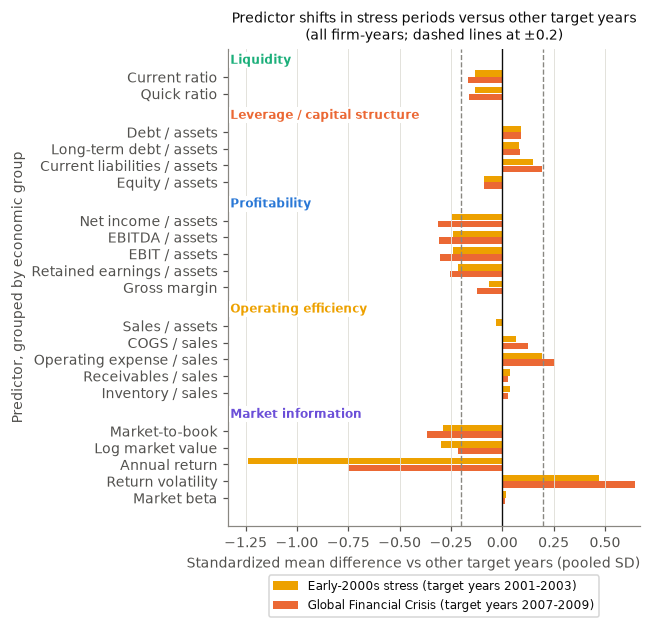

In [51]:
# ---- c7.3 standardized mean differences and figure ------------------------------------------
R["s7"]["smd"] = {k: {} for k in STRESS}
for k in STRESS:
    for v in CONT:
        R["s7"]["smd"][k][v] = smd(df.loc[period_mask[k], v], df.loc[period_mask["nonstress"], v])


def smd_reading(s):
    return "notable" if abs(s) >= SMD_NOTABLE else ("little difference" if abs(s) < SMD_SMALL else "in between")


R["s7"]["top3"] = {k: sorted(CONT, key=lambda v: -abs(R["s7"]["smd"][k][v]))[:3] for k in STRESS}
R["s7"]["n_notable"] = {k: int(sum(abs(R["s7"]["smd"][k][v]) >= SMD_NOTABLE for v in CONT)) for k in STRESS}
R["s7"]["group_mean_abs_smd"] = {k: {g: float(np.mean([abs(R["s7"]["smd"][k][v]) for v in vs]))
                                     for g, vs in GROUPS.items()} for k in STRESS}
smd_rows = [{"Group": GROUP_NAMES[VAR_GROUPS[v]], "Variable": var_label(v),
             "SMD early-2000s": R["s7"]["smd"]["dotcom"][v], "Reading early-2000s": smd_reading(R["s7"]["smd"]["dotcom"][v]),
             "SMD financial crisis": R["s7"]["smd"]["gfc"][v], "Reading financial crisis": smd_reading(R["s7"]["smd"]["gfc"][v])}
            for v in CONT]
sys.stdout.flush()
show(pd.DataFrame(smd_rows), "Standardized mean difference of each predictor: stress period minus other target years",
     formats={"SMD early-2000s": "sf2", "SMD financial crisis": "sf2"})
for k in STRESS:
    print(f"{PERIOD_SHORT[k]}: {R['s7']['n_notable'][k]} of {len(CONT)} predictors have a notable shift; largest absolute shifts: "
          + ", ".join(f"{var_label(v, unit=False)} ({fmt_num(R['s7']['smd'][k][v], 'sf2')})" for v in R["s7"]["top3"][k]))
sys.stdout.flush()
show(pd.DataFrame({"Group": [GROUP_NAMES[g] for g in GROUPS],
                   "Mean absolute SMD early-2000s": [R["s7"]["group_mean_abs_smd"]["dotcom"][g] for g in GROUPS],
                   "Mean absolute SMD financial crisis": [R["s7"]["group_mean_abs_smd"]["gfc"][g] for g in GROUPS]}),
     "Mean absolute SMD by economic group", formats={"Mean absolute SMD early-2000s": "f2",
                                                    "Mean absolute SMD financial crisis": "f2"})

# sensitivity: the same SMD against the other training target years only (2000, 2004-2006, 2010-2012)
period_mask["nonstress_train"] = df["target_year"].isin(PERIOD_YEARS["nonstress_train"]).to_numpy()
R["s7"]["smd_train_ref"] = {k: {v: smd(df.loc[period_mask[k], v], df.loc[period_mask["nonstress_train"], v]) for v in CONT}
                            for k in STRESS}
R["s7"]["n_notable_train_ref"] = {k: int(sum(abs(R["s7"]["smd_train_ref"][k][v]) >= SMD_NOTABLE for v in CONT)) for k in STRESS}
R["s7"]["robust_notable"] = {k: [v for v in CONT
                                 if abs(R["s7"]["smd"][k][v]) >= SMD_NOTABLE and abs(R["s7"]["smd_train_ref"][k][v]) >= SMD_NOTABLE
                                 and np.sign(R["s7"]["smd"][k][v]) == np.sign(R["s7"]["smd_train_ref"][k][v])] for k in STRESS}
sens_rows = [{"Group": GROUP_NAMES[VAR_GROUPS[v]], "Variable": var_label(v),
              "Early-2000s: vs all other years": R["s7"]["smd"]["dotcom"][v],
              "Early-2000s: vs other training years": R["s7"]["smd_train_ref"]["dotcom"][v],
              "Financial crisis: vs all other years": R["s7"]["smd"]["gfc"][v],
              "Financial crisis: vs other training years": R["s7"]["smd_train_ref"]["gfc"][v]} for v in CONT]
sys.stdout.flush()
show(pd.DataFrame(sens_rows),
     "Sensitivity of the standardized mean difference to the comparison group: all other target years (as above) versus only the other "
     "training target years (2000, 2004-2006, 2010-2012)",
     formats={c: "sf2" for c in ("Early-2000s: vs all other years", "Early-2000s: vs other training years",
                                 "Financial crisis: vs all other years", "Financial crisis: vs other training years")})
for k in STRESS:
    print(f"{PERIOD_SHORT[k]}: {R['s7']['n_notable'][k]} of {len(CONT)} notable against all other target years, "
          f"{R['s7']['n_notable_train_ref'][k]} against the other training target years; notable (at least 0.2 in absolute value) "
          "with the same sign under both comparison groups: "
          + (", ".join(var_label(v, unit=False) for v in R["s7"]["robust_notable"][k]) or "none") + ".")

# figure: predictors grouped by economic group, one bar per stress period
ypos, ylabels, group_rows, y = {}, [], [], 0.0
for g, vs in GROUPS.items():
    group_rows.append((g, y)); y += 1.0
    for v in vs:
        ypos[v] = y; y += 1.0
    y += 0.3
fig, ax = plt.subplots(figsize=(5.8, 5.6), layout="constrained")
for k, off in (("dotcom", -0.2), ("gfc", 0.2)):
    ax.barh([ypos[v] + off for v in CONT], [R["s7"]["smd"][k][v] for v in CONT], height=0.38,
            color=PERIOD_COLORS[k], label=PERIOD_NAMES[k])
ax.axvline(0, color=INK, lw=0.9)
for ref in (-SMD_NOTABLE, SMD_NOTABLE):
    ax.axvline(ref, color=MUTED, lw=0.9, ls="--")
ax.set_yticks([ypos[v] for v in CONT], [var_label(v, unit=False) for v in CONT])
for g, gy in group_rows:
    ax.text(0.005, gy, GROUP_NAMES[g], transform=ax.get_yaxis_transform(), ha="left", va="center",
            fontsize=8, fontweight="bold", color=GROUP_COLORS[g],
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.0}, zorder=5)
ax.invert_yaxis()
ax.set_xlim(right=1.04 * max(R["s7"]["smd"][k][v] for k in ("dotcom", "gfc") for v in CONT))  # keeps the last tick label on the canvas
ax.grid(axis="y", visible=False)
ax.set_xlabel("Standardized mean difference vs other target years (pooled SD)", loc="right")
ax.set_ylabel("Predictor, grouped by economic group")
ax.set_title("Predictor shifts in stress periods versus other target years\n(all firm-years; dashed lines at ±0.2)", fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=1)
save_fig(fig, "stress_smd")


In [52]:
# ---- c7.4 link between stress shifts and model importance (read-only from Section 6) --------------
R["s7"]["link"] = {}
link_rows = []
for v in CONT:
    entry = {"smd_dotcom": R["s7"]["smd"]["dotcom"][v], "smd_gfc": R["s7"]["smd"]["gfc"][v],
             "perm_ens_rank": int(IMPORTANCE.loc[v, "perm_ens_rank"])}
    lin = IMPORTANCE.loc[v, "linear_rank"]
    if np.isfinite(lin):
        entry["linear_rank"] = int(lin)
    R["s7"]["link"][v] = entry
    link_rows.append({"Variable": var_label(v), "SMD early-2000s": entry["smd_dotcom"], "SMD financial crisis": entry["smd_gfc"],
                      "Linear model rank (1 = largest coefficient)": entry.get("linear_rank", np.nan),
                      "Ensemble permutation rank (1 = largest drop)": entry["perm_ens_rank"]})
sys.stdout.flush()
show(pd.DataFrame(link_rows), "Stress shifts next to model importance ranks (ranks among the model's predictors, from Section 6)",
     formats={"SMD early-2000s": "sf2", "SMD financial crisis": "sf2",
              "Linear model rank (1 = largest coefficient)": "int", "Ensemble permutation rank (1 = largest drop)": "int"})

# in-sample fit of the calibrated model by period: observed default rate (Wilson interval) versus mean raw prediction
_pred_train = predict(FINAL[BEST["overall"]]["pipe"], X_train)
_pred_masks = {"dotcom": np.isin(ty_train, PERIOD_YEARS["dotcom"]), "gfc": np.isin(ty_train, PERIOD_YEARS["gfc"]),
               "nonstress_train": np.isin(ty_train, PERIOD_YEARS["nonstress_train"])}
R["s7"]["pred_by_period"] = {}
for _k, _m in _pred_masks.items():
    _n, _d = int(_m.sum()), int(y_train[_m].sum())
    _lo, _hi = wilson(_d, _n)
    R["s7"]["pred_by_period"][_k] = {"n": _n, "defaults": _d, "rate": _d / _n, "rate_lo": float(_lo), "rate_hi": float(_hi),
                                     "mean_pred": float(_pred_train[_m].mean())}
sys.stdout.flush()
show(pd.DataFrame([{"Period": PERIOD_NAMES[_k], "Firm-years": _v["n"], "Defaults": _v["defaults"], "Observed default rate": _v["rate"],
                    "Interval low": _v["rate_lo"], "Interval high": _v["rate_hi"], "Mean predicted PD": _v["mean_pred"]}
                   for _k, _v in R["s7"]["pred_by_period"].items()]),
     f"In-sample fit of {FINAL[BEST['overall']]['name']} by period: observed default rate with a 95% Wilson interval versus mean "
     "predicted probability (training rows, so the fit is in-sample; descriptive only)",
     formats={"Firm-years": "int", "Defaults": "int", "Observed default rate": "pct2", "Interval low": "pct2",
              "Interval high": "pct2", "Mean predicted PD": "pct2"})


Stress shifts next to model importance ranks (ranks among the model's predictors, from Section 6)


Variable,SMD early-2000s,SMD financial crisis,Linear model rank (1 = largest coefficient),Ensemble permutation rank (1 = largest drop)
Current ratio (ratio),-0.13,-0.17,14,12
Quick ratio (ratio),-0.13,-0.16,11,5
Debt / assets (ratio),+0.09,+0.09,2,14
Long-term debt / assets (ratio),+0.08,+0.09,4,4
Current liabilities / assets (ratio),+0.15,+0.19,7,2
Equity / assets (ratio),-0.09,-0.09,3,8
Net income / assets (ratio),-0.25,-0.32,16,16
EBITDA / assets (ratio),-0.24,-0.31,15,7
EBIT / assets (ratio),-0.24,-0.30,21,18
Retained earnings / assets (ratio),-0.22,-0.26,5,6


In-sample fit of Model 3: Ridge logistic (L2) by period: observed default rate with a 95% Wilson interval versus mean predicted probability (training rows, so the fit is in-sample; descriptive only)


Period,Firm-years,Defaults,Observed default rate,Interval low,Interval high,Mean predicted PD
Early-2000s stress (target years 2001-2003),"14,774",34,0.23%,0.16%,0.32%,0.81%
Global Financial Crisis (target years 2007-2009),"11,994",168,1.40%,1.21%,1.63%,0.87%
Other training target years,"29,159",201,0.69%,0.60%,0.79%,0.62%


In [53]:
# ---- c7.5 accounting versus market information within training target-year groups ------------------
def block_model():
    return Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=np.inf, solver="newton-cholesky", tol=1e-8, max_iter=1000))])


acc_model = block_model().fit(X_train[ACCOUNTING_VARS], y_train)
mkt_model = block_model().fit(X_train[MARKET_VARS], y_train)
p_acc = acc_model.predict_proba(X_train[ACCOUNTING_VARS])[:, 1].astype(np.float64)
p_mkt = mkt_model.predict_proba(X_train[MARKET_VARS])[:, 1].astype(np.float64)
print(f"Accounting block: {len(ACCOUNTING_VARS)} ratios; market block: {len(MARKET_VARS)} variables; "
      f"each fitted once on {len(y_train):,} training firm-years.")

block_groups = {"dotcom": np.isin(ty_train, STRESS["dotcom"]), "gfc": np.isin(ty_train, STRESS["gfc"]),
                "nonstress_train": np.isin(ty_train, PERIOD_YEARS["nonstress_train"])}
R["s7"]["blocks"] = {"accounting_vars": list(ACCOUNTING_VARS), "market_vars": list(MARKET_VARS), "auc": {}}
block_rows = []
for k, mask in block_groups.items():
    yy, gg = y_train[mask], g_train[mask]
    pa, pm = p_acc[mask], p_mkt[mask]
    boot = paired_bootstrap(yy, {"accounting": pa, "market": pm}, gg)
    a_auc, m_auc = roc_auc(yy, pa), roc_auc(yy, pm)
    a_lo, a_hi = metric_interval(boot["accounting"]["roc_auc"])
    m_lo, m_hi = metric_interval(boot["market"]["roc_auc"])
    diff = pair_summary(m_auc, a_auc, boot["market"]["roc_auc"], boot["accounting"]["roc_auc"])
    R["s7"]["blocks"]["auc"][k] = {"n": int(mask.sum()), "defaults": int(yy.sum()),
                                   "accounting": {"auc": a_auc, "lo": a_lo, "hi": a_hi},
                                   "market": {"auc": m_auc, "lo": m_lo, "hi": m_hi}, "diff": diff}
    block_rows.append({"Period": PERIOD_NAMES[k], "Firm-years": int(mask.sum()), "Defaults": int(yy.sum()),
                       "Accounting ROC-AUC [95% interval]": f"{fmt_num(a_auc, 'f3')} [{fmt_num(a_lo, 'f3')}, {fmt_num(a_hi, 'f3')}]",
                       "Market ROC-AUC [95% interval]": f"{fmt_num(m_auc, 'f3')} [{fmt_num(m_lo, 'f3')}, {fmt_num(m_hi, 'f3')}]",
                       "Market minus accounting [95% interval]":
                           f"{fmt_num(diff['d'], 'sf3')} [{fmt_num(diff['lo'], 'sf3')}, {fmt_num(diff['hi'], 'sf3')}]",
                       "Label": diff["label"]})
sys.stdout.flush()
show(pd.DataFrame(block_rows),
     "Accounting-only versus market-only logistic models, scored within training target-year groups (in-sample, descriptive)",
     formats={"Firm-years": "int", "Defaults": "int"})

# the frozen choices must be exactly what Section 5 froze
digest_after = digest_of(build_frozen())
record_check("frozen_unchanged_after_stress", digest_after == FROZEN_DIGEST,
             "the frozen choices are unchanged after the stress analysis (checksum recomputed and equal)")


Accounting block: 14 ratios; market block: 5 variables; each fitted once on 55,927 training firm-years.
Accounting-only versus market-only logistic models, scored within training target-year groups (in-sample, descriptive)


Period,Firm-years,Defaults,Accounting ROC-AUC [95% interval],Market ROC-AUC [95% interval],Market minus accounting [95% interval],Label
Early-2000s stress (target years 2001-2003),"14,774",34,"0.714 [0.627, 0.788]","0.665 [0.586, 0.743]","-0.049 [-0.137, +0.040]",similar
Global Financial Crisis (target years 2007-2009),"11,994",168,"0.711 [0.675, 0.748]","0.620 [0.580, 0.662]","-0.091 [-0.133, -0.048]",lower
Other training target years,"29,159",201,"0.677 [0.639, 0.712]","0.673 [0.636, 0.708]","-0.004 [-0.046, +0.037]",similar


  passed: the frozen choices are unchanged after the stress analysis (checksum recomputed and equal)



**What this section is.** Both stress periods are target years inside the training period, so every statement below is in-sample and descriptive. It does not select or re-rank models; all choices were frozen before the test years were scored. The profile and SMD analyses use predictor values only, never default outcomes, and cover all firm-years in the stated target years; because the periods are defined by target year, the predictors come from fiscal years 2000-2002 and 2006-2008. For the accounting and market sub-models, the rule for labels is as before: higher or lower only if the 95% firm-resampling interval excludes zero, otherwise similar.

**Realized default rates.**

- *Early-2000s stress (2001-2003):* 0.23% (34 defaults in 14,774 firm-years), below the 0.78% of the other target years (0.29 times that rate) and below the 0.69% of the other training target years. In this dataset the early-2000s years do not show a default spike. A possible reason, not tested here, is that the lowest rates fall in the first target years of the sample, so the comparison may reflect how the sample begins as much as the economy.
- *Global Financial Crisis (2007-2009):* 1.40% (168 defaults in 11,994 firm-years), 1.79 times the other target years' rate and above the 0.69% of the other training years.

**Which characteristics move most (SMD, stress years against other target years).**

- *Early-2000s:* 8 of 21 predictors have a notable shift (absolute SMD at least 0.2) against all other target years, but only 3 against the other training target years, which removes part of the differences between earlier and later years (time trends or changing sample composition) in firm size and profitability. The largest shifts against all other target years are Annual return (-1.24), Return volatility (+0.47) and Log market value (-0.30).
- *Financial crisis:* 9 of 21 are notable against all other target years and 6 against the other training target years. The largest against all other target years are Annual return (-0.75), Return volatility (+0.64) and Market-to-book (-0.37).
- *Shifts that hold under both comparison groups* (same sign and absolute SMD at least 0.2 against both): in the early-2000s Market-to-book, Annual return and Return volatility; in the crisis Net income / assets, EBITDA / assets, EBIT / assets, Market-to-book, Annual return and Return volatility. The market-based shifts (return, volatility, Market-to-book) hold in both periods; the profitability shifts hold only in the crisis.
- *By group (against all other target years):* the mean absolute SMD is highest for market information (0.46 early-2000s, 0.40 crisis), then profitability (0.20 and 0.26), with liquidity (0.13 and 0.16), leverage (0.10 and 0.12) and operating efficiency (0.07 and 0.09) smaller. Against all other target years the four profitability ratios other than gross margin shift by at least 0.2 in both periods (for example Net income / assets -0.25 and -0.32), but against the other training years Net income / assets is -0.16 in the early-2000s and -0.24 in the crisis, so the early-2000s profitability shifts, like the Log market value shift (-0.30 against -0.17), partly reflect differences between earlier and later years (time trends or changing sample composition) and not only the stress. Debt / assets (+0.09 and +0.09) shows little difference.
- *Profile (means, stress against other years):* Annual return -0.273 early-2000s and -0.201 crisis against 0.055; Return volatility 0.297 and 0.324 against 0.256; Net income / assets 0.063 and 0.058 against 0.077.

**Are these characteristics important in the models?** Partly. Annual return, the largest shift in both periods, is also first in the Ridge coefficients (rank 1) and in the ensemble permutation importance (rank 1). Log market value ranks 3 in the ensemble. Others do not line up: Return volatility moves strongly (+0.47 and +0.64) but ranks 9 in the linear model and 15 in the ensemble; Market-to-book moves by -0.29 and -0.37 but ranks 20 and 20; Debt / assets barely moves but is the linear model's rank 2. A large stress-period shift in the average level of a variable is not the same as importance for separating defaulters from survivors.

**Accounting against market information (in-sample, training years only).** Accounting-only and market-only logistic models, each fitted once on all training rows, differ by period in how well they separate defaulters. The accounting block has 14 predictors and the market block 5, and both are scored in-sample, so the larger block has a mechanical advantage that the comparison does not remove:

- *Early-2000s (34 defaults):* accounting ROC-AUC 0.714 [0.627, 0.788], market 0.665 [0.586, 0.743]; market minus accounting -0.049 [-0.137, +0.040], similar.
- *Financial crisis (168 defaults):* accounting 0.711 [0.675, 0.748], market 0.620 [0.580, 0.662]; market minus accounting -0.091 [-0.133, -0.048], lower.
- *Other training years (201 defaults):* 0.677 and 0.673; difference -0.004 [-0.046, +0.037], similar.

The two blocks differ detectably in discriminating power only in the Global Financial Crisis years, where the market block separates defaulters less well than the accounting block; the data do not show market information being more useful in stress. In the early-2000s window the 34 defaults leave the comparison inconclusive. Despite Annual return's large average shift, the market block is not stronger in stress. A possible reason, not tested here, is that a market-wide fall in returns moves all firms together and so does little to separate defaulters from survivors within the same year.



**In-sample evidence that the mapping differs by regime.** The same fitted Ridge over-predicts default in the early-2000s target years (mean predicted probability 0.81% against 0.23% observed, interval 0.16% to 0.32%) and under-predicts it in the Global Financial Crisis years (0.87% against 1.40%, interval 1.21% to 1.63%). In the other training years the mean prediction (0.62%) lies inside the observed interval (0.60% to 0.79%). The intervals treat firm-years as independent and the comparison is in-sample and descriptive, but it is concrete evidence that the relationship between characteristics and default differed across these regimes.

**Signs to monitor.** These are descriptive signs that relationships may shift across regimes, not established evidence of a shift; most are not tested by the resampling rule.

- *Base rates move.* The annual default rate ranges from 0.06% to 1.50%, and the sample rates (point estimates) rise from 0.72% (training) to 0.83% (validation) and 0.97% (test).
- *Firm characteristics move.* In the stress periods Annual return shifts by -1.24 (early-2000s) and -0.75 (crisis) standard deviations, and Return volatility by +0.47 and +0.64, so a model fitted on pooled years sees very different inputs in stress; the Annual return, Return volatility and Market-to-book shifts hold against both comparison groups, whereas the size and profitability shifts partly reflect differences between earlier and later years (time trends or changing sample composition).
- *The market-versus-accounting gap is detectable only in the crisis years.* Within the crisis target years the market-only model separates defaulters less well than the accounting-only model (-0.091 [-0.133, -0.048], lower), while in the early-2000s target years (-0.049 [-0.137, +0.040]) and the other training years the two are similar (-0.004 [-0.046, +0.037]).
- *Out-of-sample metrics move.* Test ROC-AUC exceeds validation ROC-AUC for every frozen model (point estimates on different samples; the intervals overlap), by +0.030 to +0.059. A possible reason, not tested here, is the composition of the test years.
- *Calibration moves.* The Ridge probabilities, even after Platt scaling on validation, average 1.00% in 2019 against an observed 1.32%, and the raw probabilities are below the observed rate in each test year; of the 0.40-point test shortfall, 0.25 points reflect a higher default rate than in training and 0.15 points lower predictions for later firm-years (Section 6).

In general, relationships between firm ratios and default can shift for several reasons: base rates and credit supply change over the cycle; policy support (such as low interest rates or bailouts) can keep weak firms alive in some periods and not in others; market variables such as returns and volatility co-move across the whole economy; accounting ratios are reported with a lag; and the mix of firms in the sample changes over time. Four test years and one chronological split cannot establish how stable the relationships are.

**Implications for deployment.**

- Monitor the realized default rate and the average predicted probability by year, and the averages of the main predictors (predictor-level drift: later firm-years look safer on Annual return, Return volatility and Log market value); recalibrate the probability map (refit the Platt map on recent data) when they diverge, because probabilities fitted on earlier years need recalibration after a base-rate shift. The Platt slope of 1.215 shows that the correction is more than a level shift.
- Re-estimate periodically, and track the inputs with the largest stress shifts (return and volatility measures) as an early signal that the model is operating outside the conditions it was fitted on.
- Keep a challenger (here Model 6: XGBoost (boosted trees)), compared on the same recent data, to see whether the ranking between linear and nonlinear models changes.
- Treat thresholds as a policy choice to revisit: a fixed cut-off tuned in one regime flags a different share of firms in another.
- Run stress diagnostics like those above on the deployed model's inputs, noting that the stress years here are in the training period and say nothing about out-of-sample performance in a crisis.


### Recommendation for a credit-risk team


**Which model, and why.** Deploy Model 3: Ridge logistic (L2), with Model 6: XGBoost (boosted trees) as the challenger. The choice follows the rule fixed on validation before the test years were opened: if the best model by validation ROC-AUC is linear, it is the deployment candidate. Here the best model by validation ROC-AUC is Model 3: Ridge logistic (L2) (0.697 [0.642, 0.754]), so the rule label is "not needed". The pre-specified rule therefore coincides here with the highest validation ROC-AUC, and the 0.0001 tie tolerance acts essentially as a strict maximum: it breaks near-exact ties only, not sampling noise. Test and stress results were not used to choose, and can only confirm or qualify the choice.

**Ridge or LASSO?** The rule took Ridge because its validation ROC-AUC (0.697) is higher than LASSO's (0.696) by more than the 0.0001 tie tolerance. The data do not separate the two, though: LASSO minus Ridge is -0.001 [-0.006, +0.005] on validation and +0.004 [-0.0002, +0.009] on test, both similar under the resampling rule (the test interval only just includes zero). LASSO is an equally defensible choice, and a sparser one: it sets 18 of 31 coefficients to zero (an alternative solution with the same fit has 19, because the split between Debt / assets and Equity / assets is arbitrary), whereas Ridge keeps every member of the correlated groups with shrunken weights, which may be a stability advantage (a possible reason, not tested here). LASSO's test ROC-AUC (0.742) is numerically higher than Ridge's (0.738), but choosing LASSO now for that reason would use test outcomes to select a model, so the frozen choice stays.

**Would I choose the highest AUC automatically? No.** Here "no" means not switching to the test leader and not preferring complexity for a small, noisy margin. Between Ridge and LASSO, the numerically higher validation model (Ridge) and the numerically higher test model (LASSO) differ, while both comparisons are labelled similar, so the highest number alone would not settle the choice. Against the ensembles, on validation Ridge is similar to the forest (+0.020 for Ridge minus forest [-0.010, +0.050]) and XGBoost (+0.015 [-0.004, +0.034]); only the decision tree is lower than it. A top AUC by a small, noisy margin is therefore not a reason to prefer a more complex model. The test results are consistent with the deployment choice: Ridge has test ROC-AUC 0.738 [0.693, 0.783] and is higher than the decision tree and Model 1 (-0.018 for Model 1 minus Ridge), and similar to LASSO, the forest and XGBoost.

**How the criteria bear on the decision.**

- *Ranking.* In the test sample Ridge's highest-risk decile has a default rate of 3.74%, holds 38.7% of defaults (46 of 119) and has PR-AUC 0.046 and KS 0.405.
- *Calibration.* Raw probabilities are too low (0.57% predicted against 0.97% observed), so the validation Platt map should be applied (0.93% mean predicted, Brier 0.00948 against 0.00954 raw, lower) and refreshed as the base rate moves.
- *Interpretability.* A linear model gives a transparent, auditable link between inputs and risk; its largest coefficients (Annual return, leverage measures, Retained earnings / assets) have sensible signs, with the caveat that correlated variables share coefficients and that coefficients are predictive associations, not causal effects.
- *Stability.* There is concrete in-sample evidence that the mapping from characteristics to default differs across regimes: the fitted Ridge's mean predicted probability is 0.81% in the early-2000s target years against 0.23% observed (interval 0.16% to 0.32%) and 0.87% in the crisis years against 1.40% (1.21% to 1.63%), while in the other training years it lies inside the observed interval. Out of sample, calibration drifts by year: the raw Ridge probabilities average 0.50% to 0.62% across the test years against observed rates of 0.70% to 1.32%, and even after the Platt map the 2019 mean is 1.00% against 1.32% observed. In the training years the market-only block is lower than the accounting-only block only in the crisis target years (-0.091 [-0.133, -0.048]). Coefficients of correlated predictors are sensitive to the penalty: the Spearman correlation of absolute coefficients between Model 1 and Ridge is 0.29, and their top-ten lists overlap in 6 of 10 variables. Stability across regimes is therefore not established for any model, so monitoring (including predictor-level drift) and recalibration matter.
- *False-positive costs.* At the validation threshold (0.0183) Ridge flags 203 test firm-years, of which 16 default and 187 do not (precision 7.9%, recall 13.4%); in the top decile there are 25.72 non-defaults per captured default. The threshold maximizes F1 on validation, so it is not cost-based: a team should set it from the cost of a missed default against the cost of reviewing or rejecting a sound firm, and may prefer a ranking-based screen (for example the top decile).

**Main limitations.**

- The data are an anonymized firm-year panel with amounts on a synthetic scale: results illustrate methods, not real-world magnitudes.
- Defaults are rare (87 in validation, 119 in test), so intervals are wide and small gaps between models can be noise.
- One chronological split with four test years; base rates drift, so a fitted model needs recalibration, and the stress years lie in the training period, so the stress analysis is descriptive and in-sample.
- The panel contains the same firms across years: all 3,712 test firms appear in training, so the results describe later years of observed firms, not new borrowers.
- Predictors and costs are limited to the supplied ratios; no refit on training plus validation, and no cost-based threshold, was used.


## Appendix: Reproducibility Checks and Results Export

The first table maps each methodological safeguard to the checks that evidence it. The second table lists every check run during the notebook. The final cell confirms that all checks passed, that the test targets were read exactly once, and writes every stored result to `results_summary.json`.

In [54]:
# ---- checks registry: name -> plain description ------------------------------------------------
CHECK_DESCRIPTIONS = {
    "csv_shapes_ok": "The four files have the expected shapes and the model file holds the expected columns",
    "documented_counts_match": "Firm-years, firms, sample period and defaults equal the documented counts",
    "no_missing_or_infinite": "No missing values and no infinite values in the predictors",
    "target_year_is_fiscal_plus_one": "The outcome year is the predictor fiscal year plus one in every row",
    "split_matches_fiscal_rule": "The fiscal-year split rule reproduces the supplied split column",
    "no_duplicate_firm_years": "No firm appears twice in the same fiscal year",
    "one_default_per_firm_none_after": "Each firm defaults at most once and has no later firm-years",
    "raw_keys_targets_match": "The raw file has the same keys, split and default flags as the model file",
    "annual_counts_match": "Annual firm-years and defaults equal the annual counts file",
    "ratios_reproduced": "All 21 ratios are reproduced from the raw components within tolerance",
    "exact_complements": "Equity / assets and COGS / sales are exact complements of debt / assets and gross margin",
    "model1_design_full_rank": "The Model 1 design matrix has full column rank",
    "all21_design_rank_deficient": "The design with all 21 ratios is rank deficient (the reason for the Model 1 drop)",
    "scaler_fit_on_train": "Scaling statistics equal the training-sample means",
    "undersampling_train_only": "Undersampling uses training rows only and keeps every training default",
    "thresholds_from_validation": "Frozen thresholds equal the maximum-F1 thresholds recomputed on validation",
    "calibrators_fit_on_validation": "Calibration maps are reproduced by refitting on validation predictions",
    "test_locked_until_freeze": "Test outcomes enter only Section 1's aggregate counts and data-integrity checks (one default per firm, raw/model agreement); none is used for any model, setting, threshold or calibration before the freeze",
    "freeze_digest_unchanged": "The frozen choices have the same digest when the test is scored",
    "bootstrap_metrics_match_sklearn": "Unit-weight resampling metrics equal the direct metric functions",
    "deciles_from_predictions": "Deciles are built from predicted probabilities and sum to the test defaults",
    "stress_years_in_training": "The stress periods lie within the training years",
    "frozen_unchanged_after_stress": "No final model is fitted, tuned or selected after the unlock; the only later fits are the descriptive Section 7 sub-models on training rows (the frozen choices are unchanged after the stress analysis)",
    "figures_labelled": "All twelve figures exist with labelled axes and titles",
}
CHECKLIST = [
    ("All data files are read correctly",
     ["csv_shapes_ok", "documented_counts_match", "raw_keys_targets_match"]),
    ("Predictors at fiscal year t forecast the default outcome in t + 1",
     ["target_year_is_fiscal_plus_one", "split_matches_fiscal_rule"]),
    ("Transformations are estimated on training data only", ["scaler_fit_on_train"]),
    ("Validation data are used for tuning, imbalance-method selection, thresholds and calibration",
     ["thresholds_from_validation", "calibrators_fit_on_validation"]),
    ("Test outcomes are used only for final evaluation",
     ["test_locked_until_freeze", "freeze_digest_unchanged"]),
    ("Undersampling is never applied to validation or test data", ["undersampling_train_only"]),
    ("Risk deciles are based on predicted probabilities, not realized outcomes", ["deciles_from_predictions"]),
    ("The stress-period section is used for interpretation, not to choose the best model",
     ["stress_years_in_training", "frozen_unchanged_after_stress"]),
    ("All required plots and tables are present and labelled", ["figures_labelled"]),
]
FIGURE_NAMES = ["annual_default_rate", "train_distributions", "train_correlation_heatmap", "linear_coefficients",
                "tree_depth_curve", "decision_tree_top", "imbalance_comparison", "roc_pr_test", "risk_deciles_test",
                "calibration_test", "importance_comparison", "stress_smd"]

# ---- test-target reads and figure labels ----------------------------------------------------------
R["s5"]["test_target_reads"] = LOCK.test_reads
fig_ok = (sorted(R["figures"]) == sorted(FIGURE_NAMES)
          and all(f["file"] and all(a.get("axis_off") or (a["title"].strip() and a["xlabel"].strip() and a["ylabel"].strip())
                                    for a in f["axes"]) for f in R["figures"].values()))
R["checks"]["figures_labelled"] = bool(fig_ok)


def check_status(name):
    return "not run" if name not in R["checks"] else ("yes" if R["checks"][name] is True else "no")


checklist_rows = [{"Safeguard": item,
                   "Evidence": "; ".join(CHECK_DESCRIPTIONS[c] for c in names),
                   "Passed": "yes" if all(check_status(c) == "yes" for c in names) else "no"}
                  for item, names in CHECKLIST]
check_rows = [{"Check": name, "What it verifies": CHECK_DESCRIPTIONS[name], "Passed": check_status(name)}
              for name in CHECK_DESCRIPTIONS]
extra_checks = sorted(set(R["checks"]) - set(CHECK_DESCRIPTIONS) - {"all_passed"})
check_rows += [{"Check": name, "What it verifies": "additional check recorded by a section",
                "Passed": check_status(name)} for name in extra_checks]
show(pd.DataFrame(checklist_rows), "Methodology checklist")
show(pd.DataFrame(check_rows), "All reproducibility checks")

test_reads_ok = (LOCK.test_reads == 1)
failed = [r["Check"] for r in check_rows if r["Passed"] != "yes"]
R["checks"]["all_passed"] = bool(not failed and test_reads_ok)
print(f"Checks passed: {sum(r['Passed'] == 'yes' for r in check_rows)} of {len(check_rows)}; "
      f"test targets were read {LOCK.test_reads} time(s) (expected 1).")
assert R["checks"]["all_passed"], f"Checks not passed: {failed}; test target reads: {LOCK.test_reads}"


def count_keys(obj):
    return sum(1 + count_keys(v) for v in obj.values()) if isinstance(obj, dict) else 0


payload = to_py(R)
with open("results_summary.json", "w", encoding="utf-8") as handle:
    json.dump(payload, handle, indent=1, sort_keys=True, allow_nan=False)
print(f"Wrote results_summary.json with {count_keys(payload):,} keys in {len(payload)} top-level groups.")


Methodology checklist


Safeguard,Evidence,Passed
All data files are read correctly,"The four files have the expected shapes and the model file holds the expected columns; Firm-years, firms, sample period and defaults equal the documented counts; The raw file has the same keys, split and default flags as the model file",yes
Predictors at fiscal year t forecast the default outcome in t + 1,The outcome year is the predictor fiscal year plus one in every row; The fiscal-year split rule reproduces the supplied split column,yes
Transformations are estimated on training data only,Scaling statistics equal the training-sample means,yes
"Validation data are used for tuning, imbalance-method selection, thresholds and calibration",Frozen thresholds equal the maximum-F1 thresholds recomputed on validation; Calibration maps are reproduced by refitting on validation predictions,yes
Test outcomes are used only for final evaluation,"Test outcomes enter only Section 1's aggregate counts and data-integrity checks (one default per firm, raw/model agreement); none is used for any model, setting, threshold or calibration before the freeze; The frozen choices have the same digest when the test is scored",yes
Undersampling is never applied to validation or test data,Undersampling uses training rows only and keeps every training default,yes
"Risk deciles are based on predicted probabilities, not realized outcomes",Deciles are built from predicted probabilities and sum to the test defaults,yes
"The stress-period section is used for interpretation, not to choose the best model","The stress periods lie within the training years; No final model is fitted, tuned or selected after the unlock; the only later fits are the descriptive Section 7 sub-models on training rows (the frozen choices are unchanged after the stress analysis)",yes
All required plots and tables are present and labelled,All twelve figures exist with labelled axes and titles,yes


All reproducibility checks


Check,What it verifies,Passed
csv_shapes_ok,The four files have the expected shapes and the model file holds the expected columns,yes
documented_counts_match,"Firm-years, firms, sample period and defaults equal the documented counts",yes
no_missing_or_infinite,No missing values and no infinite values in the predictors,yes
target_year_is_fiscal_plus_one,The outcome year is the predictor fiscal year plus one in every row,yes
split_matches_fiscal_rule,The fiscal-year split rule reproduces the supplied split column,yes
no_duplicate_firm_years,No firm appears twice in the same fiscal year,yes
one_default_per_firm_none_after,Each firm defaults at most once and has no later firm-years,yes
raw_keys_targets_match,"The raw file has the same keys, split and default flags as the model file",yes
annual_counts_match,Annual firm-years and defaults equal the annual counts file,yes
ratios_reproduced,All 21 ratios are reproduced from the raw components within tolerance,yes


Checks passed: 24 of 24; test targets were read 1 time(s) (expected 1).
Wrote results_summary.json with 3,420 keys in 11 top-level groups.
